# Phase 4: Persian OCR Mastery
Welcome to Phase 4 of the Team Chati Pati Computer Vision Bootcamp.

In Phase 3 you taught a computer to follow *objects* through time. In Phase 4 you teach it to **read**. Optical Character Recognition (OCR) looks like a solved problem for English, but **Persian (Farsi) is a genuinely hard script** for machines: it is written right-to-left, its letters are *connected* and change shape depending on their neighbours, dots carry meaning, there are invisible control characters (the zero-width non-joiner), and the same visible letter can be stored under several different Unicode code points. A pipeline that ignores any one of these quietly produces wrong output — and, worse, output that *looks* right to the eye.

This notebook is built so that **you can see every failure with your own eyes** and then fix it: you will generate your own labelled data, preprocess it, run Tesseract, diagnose failures, write a Persian text normaliser, detect text regions yourself, train a character classifier, implement CER from scratch, and finally assemble and evaluate a complete OCR project.

## Roadmap Overview
| Day | Topic | You will build | Evaluation / deliverable |
|---|---|---|---|
| **24** | OCR fundamentals | A synthetic Persian image generator (shaping + RTL) and a **50-image labelled dataset** | Dataset varies font size, font, spacing, background, rotation |
| **25** | Preprocessing | 5 preprocessing pipelines (grayscale, Otsu, adaptive threshold, denoise, deskew, morphology, CLAHE) | Which pipeline wins for which image condition |
| **26** | Tesseract | OCR runner with PSM sweep, confidences, bounding boxes | Root-cause analysis of **10 failures** (preprocessing / detection / recognition / normalisation) |
| **27** | Persian normalisation | `PersianNormalizer` (ي→ی, ك→ک, digits, whitespace, ZWNJ …) | **≥ 30-case test suite** |
| **28** | Text region detection | Contours, connected components, projection profiles, line & word segmentation | Regions extracted *before* OCR on multi-line images |
| **29** | Character recognition | A small CNN on synthetic Persian digits | Validation accuracy, confusion matrix, failure examples |
| **30** | OCR evaluation | Levenshtein / CER / WER **from scratch** | Tested on **≥ 30** reference/prediction pairs |
| **31** | Persian OCR project | `Image → Preprocess → Text Detection → Crop → OCR → Normalize → Output` | **≥ 50** test images with ground truth, **≥ 10** failures analysed, CER reported |
| **Ext** | **Modern OCR engines: EasyOCR & PaddleOCR** | Engine adapters, a reading-order reconstructor, a multi-engine comparison on your data, an engine swapped into the Day 31 pipeline, an ensemble experiment | Tesseract vs EasyOCR vs PaddleOCR on the **same inputs with your own CER** (strict & canonical) |

> **Numbering note.** The Phase 3 notebook uses "Day 24–37" for its tracker material (Part II). These Phase 4 day numbers follow *your roadmap*; they're independent of those Part II labels.

## How this notebook is organised
Every day has **(1) a concept section** in Markdown, **(2) runnable code that demonstrates it**, and **(3) an evaluation** that forces you to measure instead of guess. Later days *reuse* earlier code (the renderer from Day 24, the preprocessing functions from Day 25, the normaliser from Day 27, the metrics from Day 30), so run the notebook top to bottom.

## Prerequisites & installation
**1. The Tesseract engine and its Persian model** (this is a system program, not a pip package):

| OS | Command |
|---|---|
| Ubuntu / Debian | `sudo apt install tesseract-ocr tesseract-ocr-fas` |
| macOS (Homebrew) | `brew install tesseract tesseract-lang` |
| Windows | Install from the UB-Mannheim build and tick **Persian** in the language list, or download `fas.traineddata` into Tesseract's `tessdata` folder |

**2. Python packages**
```bash
pip install pytesseract opencv-python pillow numpy pandas matplotlib seaborn scikit-learn scikit-image \
            fonttools arabic-reshaper python-bidi rapidfuzz torch
```
**Optional, for the Extension at the end:** `pip install easyocr` (pulls PyTorch) and `pip install paddlepaddle paddleocr`. The extension runs with whichever engines you have installed.

(`rapidfuzz` is used *only* to cross-check your from-scratch Levenshtein on Day 30. `arabic-reshaper` + `python-bidi` are a fallback for rendering Persian if your Pillow has no RAQM support.)

**3. Persian fonts.** Synthetic data needs several real Persian fonts. The notebook auto-discovers installed fonts that contain Persian glyphs. If it finds fewer than four, download some **open-licence** fonts (e.g. *Vazirmatn*, *Noto Naskh Arabic*, *Noto Sans Arabic*, *Amiri*, *Scheherazade New*) into a `fonts/` folder next to this notebook.

In [1]:
import os, re, json, time, math, random, unicodedata, subprocess, shutil, warnings
from pathlib import Path
from collections import Counter, defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from PIL import Image, ImageDraw, ImageFont, features
from fontTools.ttLib import TTFont

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ── Project folders ────────────────────────────────────────────────────────────
ROOT      = Path("phase4_persian_ocr")
DATA_DIR  = ROOT / "synthetic50"          # Day 24 dataset (50 single-line images)
MULTI_DIR = ROOT / "multiline"            # Day 28 dataset
TEST_DIR  = ROOT / "project_test"         # Day 31 test set
REAL_DIR  = ROOT / "real"                 # Day 31: put real Kaggle images here
FONT_DIR  = Path("fonts")                 # optional: drop extra .ttf/.otf files here
for d in (DATA_DIR, MULTI_DIR, TEST_DIR, REAL_DIR, ROOT / "reports"):
    d.mkdir(parents=True, exist_ok=True)

# ── Is Tesseract (+ Persian) available? ────────────────────────────────────────
try:
    TESS_VERSION = str(pytesseract.get_tesseract_version())
    TESS_LANGS = pytesseract.get_languages(config="")
except Exception as e:
    TESS_VERSION, TESS_LANGS = None, []
    print("!! Tesseract was not found:", e)

print("Tesseract version :", TESS_VERSION)
print("Has Persian ('fas'):", "fas" in TESS_LANGS, "| installed languages:", TESS_LANGS)
print("Pillow RAQM layout (best Persian shaping):", features.check("raqm"))
if "fas" not in TESS_LANGS:
    print("!! Install the Persian model (see the installation table above) before Day 26.")

Tesseract version : 5.3.4
Has Persian ('fas'): True | installed languages: ['eng', 'fas', 'osd']
Pillow RAQM layout (best Persian shaping): True


---
# Day 24 — OCR Fundamentals
**Topics:** Text detection, text recognition, the OCR pipeline, right-to-left (RTL) text, connected Persian script

## 1. What OCR actually is: two problems, not one
People say "OCR" as if it were a single step. It is a **pipeline of two very different problems**:

| Stage | Question it answers | Output | Typical methods |
|---|---|---|---|
| **Text detection** | *Where* is the text? | Boxes / polygons around lines or words | Classical: thresholding + contours / connected components / projection profiles. Deep: EAST, DBNet, CRAFT |
| **Text recognition** | *What* does this text say? | A string of characters | Classical: per-character classifiers. Modern: CNN/RNN/Transformer with **CTC** or attention decoding over the *whole line* (this is what Tesseract ≥ 4's LSTM does) |

Wrapped around those two are **pre-processing** (make the image easier) and **post-processing** (make the string correct). The full pipeline you will build in Day 31:

```
Image ─► Preprocess ─► Text Detection ─► Crop ─► Recognition (OCR) ─► Normalise ─► Output
 raw      grayscale,      find lines /      one     Tesseract           fix Unicode,    clean
 pixels   binarise,       words             region  (LSTM)              digits, ZWNJ    text
          deskew …                          per                                         + boxes
                                            line                                        + confidence
```

**Why separate detection and recognition?** A recogniser is trained on *single lines*. Feed it a whole page and it must also solve layout analysis. Cropping first (Day 28) lets you choose the right mode per line, and lets you *debug*: if the boxes are wrong you know recognition was never given a chance.

**Segmentation-free recognition.** For Latin text, old OCR engines segmented a word into characters and classified each. That breaks down for cursive scripts, because **you cannot reliably cut a connected Persian word between letters** — the strokes physically join. Modern engines therefore read a whole line as a sequence (a feature map scanned along the writing direction, decoded with CTC). This is why Day 29's isolated-character CNN is an *architecture exercise*, while the real engine in this phase is Tesseract's line recogniser.

## 2. Why Persian is hard for OCR
### 2.1 Right-to-left (RTL) and the *logical vs. visual order* trap
Unicode stores text in **logical order** — the order you would *type or read* it. Persian is displayed right-to-left, so the **first** character in memory appears at the **right**. Numbers and Latin words embedded in Persian remain left-to-right (this is *bidirectional*, "bidi", text). A recogniser scans pixels left-to-right in *visual* order, so **the engine must reverse back into logical order** — and a mistake there produces text that is correct letter-by-letter but in the wrong order.

* Python strings are logical: `"سلام"[0]` is `س`, the right-most letter on screen.
* Never "fix" RTL by reversing strings yourself unless you know exactly which layer you're in.

### 2.2 Connected script and contextual shapes
Persian letters **join** along a baseline. Most letters have up to **four forms**, and Unicode stores only *one* abstract letter; the font engine (via OpenType shaping, e.g. HarfBuzz) picks the form:

| Position in word | Example for `ب` | Name |
|---|---|---|
| alone | ﺏ | isolated |
| word start | ﺑ | initial |
| middle | ﺒ | medial |
| word end | ﺐ | final |

Consequences for OCR:
* A letter looks **different** in different positions → the model must learn several shapes per letter.
* **Non-joining letters** — `ا د ذ ر ز ژ و` (and `آ`) — never connect to the *next* letter, so a single word can be drawn as several disconnected blobs. Therefore "a gap in the ink" does **not** mean "a space"; this matters hugely for word segmentation on Day 28.
* The **baseline** carries the joined strokes; ascenders, descenders and dots sit above and below it.

### 2.3 Dots are meaning
Many Persian letters share one base shape and differ **only in the number and position of dots**:

`ب پ ت ث` (same tooth, 1 below / 3 below / 2 above / 3 above) · `ج چ ح خ` · `د ذ` · `ر ز ژ` · `س ش` · `ک گ`.

Dots are tiny, so **resolution, blur and aggressive denoising destroy information**: a median filter that removes "salt-and-pepper noise" also removes the dots. You will measure this on Day 25.

### 2.4 Persian-specific letters & the Arabic look-alikes
Persian adds **پ چ ژ گ** to the Arabic alphabet, and its everyday `ی` (U+06CC) and `ک` (U+06A9) differ in code point from Arabic `ي` (U+064A) and `ك` (U+0643) even though they may look identical in some fonts. Digits come in **three families**: ASCII `0123`, Arabic-Indic `٠١٢٣`, and Persian (Eastern Arabic-Indic) `۰۱۲۳`. Day 27 is entirely about this.

### 2.5 The invisible character: ZWNJ
The **zero-width non-joiner** (U+200C, "نیم‌فاصله", *half-space*) stops two letters from joining *without* adding visible space: `می‌خواهم`, `کتاب‌ها`. It is invisible, so an OCR engine can neither see nor reproduce it reliably — yet it is part of correct Persian spelling. Evaluating OCR output without a policy for ZWNJ gives misleading error rates.

### 2.6 Quick reference — what makes Persian OCR fail
| Property | Effect on OCR | Where we deal with it |
|---|---|---|
| RTL + bidi digits/Latin | wrong reading order | Day 24 (rendering), Day 26 (PSM / reading order), Day 28 (word order) |
| Cursive joining, context shapes | segmentation-based methods fail; need line-level recognition | Day 26, Day 29 |
| Dots | lost by denoising / low resolution | Day 25 |
| Duplicate Unicode letters | "correct" output counts as an error | Day 27 |
| ZWNJ | invisible, inconsistent | Day 27, Day 30 |
| Non-joining letters create gaps | word segmentation errors | Day 28 |
| Many fonts/calligraphic styles (Naskh, Nastaliq, Titr) | domain shift | Day 24 dataset, Day 31 |

In [2]:
# ── See the problem: logical order, code points and shaping ──────────────────────────────
word = "بازار"          # "bazaar" — b, a, z, a, r
print("Logical order (what Python stores):")
for i, ch in enumerate(word):
    print(f"  [{i}] U+{ord(ch):04X}  {ch}   {unicodedata.name(ch)}")

print("\nIndex 0 is the first letter you READ, but it is drawn at the RIGHT edge of the word.")
print("Non-joining letters (ا د ذ ر ز ژ و) break the connection to the following letter:")
for ch in "ابدرزوسلمگ":
    joins_next = ch not in "ادذرزژو"
    print(f"  {ch}  joins the next letter: {joins_next}")

# Contextual forms: the *presentation forms* that a font engine chooses automatically
import arabic_reshaper
print("\nThe same letter 'ب' in four contexts — Unicode stores ONE code point, shaping picks the glyph:")
for label, sample in [("isolated", "ب"), ("initial", "بد"), ("medial", "دبد"), ("final", "دب")]:
    shaped = arabic_reshaper.reshape(sample)
    print(f"  {label:<9} {sample!r:<8} -> shaped code points: {[hex(ord(c)) for c in shaped]}")

Logical order (what Python stores):
  [0] U+0628  ب   ARABIC LETTER BEH
  [1] U+0627  ا   ARABIC LETTER ALEF
  [2] U+0632  ز   ARABIC LETTER ZAIN
  [3] U+0627  ا   ARABIC LETTER ALEF
  [4] U+0631  ر   ARABIC LETTER REH

Index 0 is the first letter you READ, but it is drawn at the RIGHT edge of the word.
Non-joining letters (ا د ذ ر ز ژ و) break the connection to the following letter:
  ا  joins the next letter: False
  ب  joins the next letter: True
  د  joins the next letter: False
  ر  joins the next letter: False
  ز  joins the next letter: False
  و  joins the next letter: False
  س  joins the next letter: True
  ل  joins the next letter: True
  م  joins the next letter: True
  گ  joins the next letter: True

The same letter 'ب' in four contexts — Unicode stores ONE code point, shaping picks the glyph:
  isolated  'ب'      -> shaped code points: ['0xfe8f']
  initial   'بد'     -> shaped code points: ['0xfe91', '0xfeaa']
  medial    'دبد'    -> shaped code points: ['0xfea9', '0xfe91

## 3. Building a Persian text-image generator
To evaluate OCR you need **ground truth**: for every image, the *exact* text it contains. The cheapest way to get thousands of perfectly-labelled Persian images is to **render them yourself**. This is called a **synthetic dataset**, and it gives you something real datasets cannot: full control. If an image fails, you know *what* was different about it (font? size? rotation?), so you can attribute failures to causes — precisely what Day 25 and Day 26 require.

### Design decisions
**Rendering text correctly.** Naively drawing a Persian string with a basic text routine produces *disconnected isolated letters in the wrong direction*. Two ways to get it right:
1. **RAQM / HarfBuzz layout** (Pillow built with `libraqm`): `draw.text(..., direction="rtl", language="fa")` does shaping, bidi and ZWNJ handling for you. *Preferred.*
2. **Fallback:** `arabic_reshaper.reshape(text)` converts letters to their contextual presentation forms, then `bidi.algorithm.get_display` reorders for visual display.

**"Spacing" must mean *word* spacing.** In Latin OCR datasets you might vary *letter* spacing (tracking). **Don't do that for Persian**: inserting space between letters *breaks the cursive joins* and produces text that no real document contains. We therefore vary **word spacing** (and line spacing for paragraphs).

**Text is rendered as a mask first.** We render the text as a grayscale *alpha mask* (white ink on black) and compose it with a background afterwards. That gives us (a) the **tight bounding box of every word** (ground truth for Day 28), (b) the same text on a *clean* background for diagnostic comparisons (Day 26), and (c) freedom to apply any background / contrast / rotation.

**A word on the corpus.** Below are short original Persian sentences. Where proper Persian orthography needs a ZWNJ we write `_` as a placeholder and convert it to U+200C when loading (typing an invisible character in source code is error-prone). Several sentences contain Persian digits, Latin digits, and ZWNJ on purpose, because those are the cases that break OCR pipelines.

In [3]:
ZWNJ = "\u200c"

_CORPUS_RAW = """
امروز هوا بسیار خوب است
من هر روز کتاب می_خوانم
دانشگاه تهران در خیابان انقلاب قرار دارد
کودکان در پارک بازی می_کنند
این کتاب_ها را از کتابخانه گرفتم
فردا صبح به مدرسه می_روم
چای داغ و شیرین را دوست دارم
پنجره را باز کن تا هوای تازه بیاید
گل_های باغ در بهار شکوفا می_شوند
یادگیری ماشین یک شاخه از هوش مصنوعی است
شماره تلفن من ۰۹۱۲۳۴۵۶۷۸۹ است
قیمت این کالا ۱۲۵۰۰۰ تومان است
سال ۱۴۰۳ سال خوبی بود
پرواز به شیراز ساعت ۱۸:۳۰ حرکت می_کند
ژاله و گلنار در چمنزار قدم می_زنند
چهار پرنده روی شاخه نشسته_اند
زبان فارسی از راست به چپ نوشته می_شود
او گفت که فردا نخواهد آمد
هیچ_کس از ماجرا خبر نداشت
ما برای امتحان پایان ترم آماده می_شویم
پدرم هر شب اخبار تماشا می_کند
برف سنگینی در کوهستان باریده است
رودخانه از میان جنگل می_گذرد
لطفا درها را ببندید
پژوهشگران نتایج تازه_ای منتشر کردند
بازار قدیمی شهر پر از رنگ و بوست
مادربزرگ برایم قصه می_گفت
خانه_ی ما نزدیک دریاست
در کتابخانه باید آرام صحبت کرد
ساعت هشت صبح جلسه شروع می_شود
پرچم ایران سه رنگ دارد
ماشین_های جدید سریع_تر هستند
گربه_ای کوچک زیر درخت خوابیده بود
نان و پنیر و سبزی صبحانه ماست
او با دقت نامه را نوشت
"""
CORPUS = [ln.replace("_", ZWNJ).strip() for ln in _CORPUS_RAW.strip().splitlines() if ln.strip()]
print(len(CORPUS), "sentences. Example:", CORPUS[1], "| contains ZWNJ:", ZWNJ in CORPUS[1])

35 sentences. Example: من هر روز کتاب می‌خوانم | contains ZWNJ: True


In [4]:
# ── Font discovery: keep only fonts that really contain the Persian glyphs we need ─────────
PERSIAN_PROBE = "پچژگکی" + "۰۱۲۳۴۵۶۷۸۹"           # letters + Persian digits

def font_supports_persian(path, chars=PERSIAN_PROBE):
    try:
        cmap = TTFont(str(path), fontNumber=0, lazy=True).getBestCmap()
        return all(ord(c) in cmap for c in chars)
    except Exception:
        return False

def discover_persian_fonts():
    """Return {family_name: file_path}. Uses fontconfig when available, plus any files in ./fonts."""
    candidates = []
    try:
        out = subprocess.run(["fc-list", ":lang=fa", "file", "family"], capture_output=True, text=True, timeout=20).stdout
        for line in out.splitlines():
            path, _, family = line.partition(": ")
            candidates.append((family.split(",")[0].split(":")[0].strip(), path.strip()))
    except Exception:
        pass                                                   # fc-list unavailable (e.g. Windows)
    for p in list(FONT_DIR.glob("*.ttf")) + list(FONT_DIR.glob("*.otf")):
        candidates.append((p.stem, str(p)))
    for d in ("C:/Windows/Fonts", "/Library/Fonts", "/System/Library/Fonts"):   # common OS font folders
        if Path(d).exists():
            candidates += [(p.stem, str(p)) for p in Path(d).glob("*.ttf")]

    STYLE_WORDS = ("bold", "italic", "black", "thin", "light", "oblique", "semi", "medium", "extra", "condensed")
    def style_penalty(t):                                   # regular upright weights first, so each family maps to its "Regular" file
        name = Path(t[1]).name.lower()
        return (0 if "regular" in name else 1, sum(w in name for w in STYLE_WORDS), name)
    fonts = {}
    for family, path in sorted(candidates, key=style_penalty):
        if path.lower().endswith((".ttf", ".otf")) and family not in fonts and font_supports_persian(path):
            fonts[family] = path
    return fonts

ALL_FONTS = discover_persian_fonts()
# Fonts that are unsuitable for a *general* dataset (monospace/bitmap-like or extremely calligraphic).
EXCLUDE_KEYWORDS = ("mono", "unifont", "nastaliq", "free")
FONTS = {k: v for k, v in ALL_FONTS.items() if not any(x in k.lower() for x in EXCLUDE_KEYWORDS)}
HARD_FONTS = {k: v for k, v in ALL_FONTS.items() if k not in FONTS}

print(f"{len(FONTS)} usable Persian fonts:")
for k, v in FONTS.items():
    print(f"  {k:<20} {v}")
print("Excluded (optional 'hard mode'):", list(HARD_FONTS))
assert len(FONTS) >= 4, "Need at least 4 Persian fonts - download some into ./fonts (see the installation section)."

44 usable Persian fonts:
  Amiri                /usr/share/fonts/opentype/fonts-hosny-amiri/Amiri-Regular.ttf
  CaskaydiaCove Nerd Font /home/norbert/.fonts/CaskaydiaCoveNerdFont-Regular.ttf
  CaskaydiaCove Nerd Font Propo /home/norbert/.fonts/CaskaydiaCoveNerdFontPropo-Regular.ttf
  Digi Ein\-Ghaf       /home/norbert/.fonts/Digi Ein-Ghaf Regular.otf
  Digi Eliya           /home/norbert/.fonts/Digi Eliya Regular.otf
  Digi Ravi            /home/norbert/.fonts/Digi Ravi Regular.otf
  Estedad              /home/norbert/.fonts/Estedad-Regular.ttf
  IRXLotus             /home/norbert/snap/code/274/.local/share/fonts/IRXLotus-Regular.ttf
  Lalezar              /home/norbert/.fonts/Lalezar-Regular.ttf
  Morabba              /home/norbert/.fonts/Morabba-Regular.ttf
  Noto Kufi Arabic     /usr/share/fonts/truetype/noto/NotoKufiArabic-Regular.ttf
  Noto Naskh Arabic    /usr/share/fonts/truetype/noto/NotoNaskhArabic-Regular.ttf
  Noto Sans Arabic     /usr/share/fonts/truetype/noto/NotoSansArabic

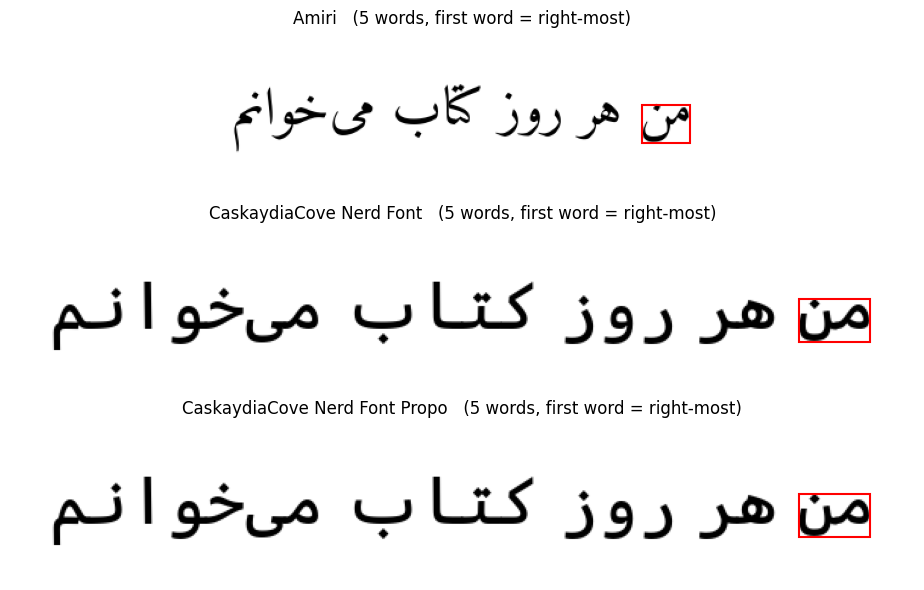

In [5]:
# ── Persian-aware text rendering ──────────────────────────────────────────────────────────
HAS_RAQM = features.check("raqm")

def _shape_fallback(text):
    """Used only when Pillow has no RAQM: contextual shaping + bidi reordering done in Python."""
    import arabic_reshaper
    from bidi.algorithm import get_display
    return get_display(arabic_reshaper.reshape(text))

def _load_font(path, size):
    layout = ImageFont.Layout.RAQM if HAS_RAQM else ImageFont.Layout.BASIC
    return ImageFont.truetype(path, size, layout_engine=layout)

def _text_length(font, text):
    return font.getlength(text, direction="rtl", language="fa") if HAS_RAQM else font.getlength(_shape_fallback(text))

def _draw_word(draw, xy, text, font):
    if HAS_RAQM:
        draw.text(xy, text, font=font, fill=255, anchor="ls", direction="rtl", language="fa")
    else:
        draw.text(xy, _shape_fallback(text), font=font, fill=255, anchor="ls")

def render_text_mask(lines, font_path, size, word_gap=0.3, line_gap=0.5, pad=None):
    """
    Render one or more lines of Persian text as a grayscale MASK (255 = ink, 0 = paper).

    lines     : list[str]  logical-order Persian text, one string per line
    word_gap  : space between words, in 'em' (1 em = font size)   <- the 'spacing' we vary
    line_gap  : extra space between lines, in em
    Returns   : mask (H x W uint8), line_boxes [[x1,y1,x2,y2]], word_boxes [[ [x1,y1,x2,y2], ... ] per line]
                Words are listed in READING order: word 0 is the RIGHT-most one.
    """
    font = _load_font(font_path, size)
    ascent, descent = font.getmetrics()
    pad = pad if pad is not None else int(size * 0.6)
    gap_px = int(word_gap * size)
    line_h = ascent + descent + int(line_gap * size)

    # 1) measure each line (right-aligned, RTL: first word at the right edge)
    measured = []
    for line in lines:
        words = line.split()
        widths = [int(math.ceil(_text_length(font, w))) for w in words]
        measured.append((words, widths, sum(widths) + gap_px * (len(words) - 1)))
    W = max(m[2] for m in measured) + 2 * pad
    H = line_h * len(lines) - int(line_gap * size) + 2 * pad

    mask = np.zeros((H, W), np.uint8)
    line_boxes, word_boxes = [], []
    for li, (words, widths, total) in enumerate(measured):
        baseline = pad + li * line_h + ascent
        x_right = W - pad
        boxes = []
        for w, wpx in zip(words, widths):
            x_left = x_right - wpx
            tmp = Image.new("L", (W, H), 0)
            _draw_word(ImageDraw.Draw(tmp), (x_left, baseline), w, font)
            arr = np.array(tmp)
            mask = np.maximum(mask, arr)
            ys, xs = np.nonzero(arr)
            if len(xs):
                boxes.append([int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1])
            x_right = x_left - gap_px
        word_boxes.append(boxes)
        line_boxes.append([min(b[0] for b in boxes), min(b[1] for b in boxes), max(b[2] for b in boxes), max(b[3] for b in boxes)])
    return mask, line_boxes, word_boxes

# Smoke test: render a sentence with ZWNJ in 3 fonts and look at it
fig, axes = plt.subplots(3, 1, figsize=(10, 6))
for ax, (fname, fpath) in zip(axes, list(FONTS.items())[:3]):
    m, lb, wb = render_text_mask([CORPUS[1]], fpath, 44)
    ax.imshow(255 - m, cmap="gray"); ax.set_title(f"{fname}   ({len(wb[0])} words, first word = right-most)"); ax.axis("off")
    x1, y1, x2, y2 = wb[0][0]; ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=1.5))
plt.tight_layout(); plt.show()

### Backgrounds, contrast, noise, rotation
Next come the **image conditions** — the factors that make OCR harder. Each function does one job so they can be combined freely.

| Function | What it simulates | Why it matters |
|---|---|---|
| `make_background("white"/"paper"/"gradient"/"texture")` | scanned paper, uneven lighting, patterned surfaces | thresholding assumes a fairly uniform background |
| `compose(mask, bg, ink, contrast)` | ink colour vs. background brightness | low contrast defeats a global threshold |
| `add_noise(img, sigma, salt_pepper)` | sensor noise, JPEG/scan artefacts | noise creates fake dots in Persian |
| `rotate_with_boxes(img, angle, boxes)` | camera not aligned with the page | skew breaks line segmentation and some recognisers |
| `blur` (inside `finish`) | out-of-focus / low resolution | dots merge with the stroke |

Every transformation that moves pixels (rotation) also transforms the **ground-truth boxes**, so detection ground truth stays valid.

In [6]:
def make_background(kind, h, w, rng, base=235):
    """Return an HxW float32 background image in [0, 255]."""
    if kind == "white":
        return np.full((h, w), 255, np.float32)
    if kind == "paper":                                            # warm off-white with gentle grain
        bg = np.full((h, w), base, np.float32) + rng.normal(0, 3, (h, w))
        return np.clip(bg, 0, 255).astype(np.float32)
    if kind == "gradient":                                         # uneven lighting
        angle = rng.uniform(0, 2 * np.pi)
        yy, xx = np.mgrid[0:h, 0:w]
        t = (xx * np.cos(angle) + yy * np.sin(angle)); t = (t - t.min()) / (np.ptp(t) + 1e-6)
        lo, hi = rng.uniform(150, 195), rng.uniform(225, 250)
        return (lo + (hi - lo) * t).astype(np.float32)
    if kind == "texture":                                          # blotchy surface
        small = rng.uniform(150, 235, (max(2, h // 12), max(2, w // 12))).astype(np.float32)
        bg = cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC)
        bg += rng.normal(0, 8, (h, w))
        return np.clip(bg, 0, 255).astype(np.float32)
    raise ValueError(kind)

def compose(mask, bg, ink=20, ink_alpha=1.0):
    """Blend ink (a gray level) onto the background wherever the mask is on."""
    a = (mask.astype(np.float32) / 255.0) * ink_alpha
    return bg * (1 - a) + ink * a

def add_noise(img, sigma=0.0, salt_pepper=0.0, rng=None):
    rng = rng or np.random.default_rng()
    out = img.astype(np.float32) + (rng.normal(0, sigma, img.shape) if sigma > 0 else 0)
    if salt_pepper > 0:
        r = rng.random(img.shape)
        out[r < salt_pepper / 2] = 0
        out[r > 1 - salt_pepper / 2] = 255
    return np.clip(out, 0, 255)

def rotate_with_boxes(img, angle, boxes_list):
    """Rotate about the centre (positive = counter-clockwise), enlarge canvas, and transform boxes. Returns img, boxes."""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    border = float(np.median(np.concatenate([img[0], img[-1], img[:, 0], img[:, -1]])))   # fill with the paper colour
    out = cv2.warpAffine(img, M, (nw, nh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=border)
    new_boxes = []
    for b in boxes_list:
        x1, y1, x2, y2 = b
        pts = np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], np.float32)
        t = pts @ M[:, :2].T + M[:, 2]
        new_boxes.append([int(t[:, 0].min()), int(t[:, 1].min()), int(t[:, 0].max()), int(t[:, 1].max())])
    return out, new_boxes

def finish(img, blur=0.0):
    if blur > 0:
        k = int(2 * round(blur * 2) + 1)
        img = cv2.GaussianBlur(img, (k, k), blur)
    return np.clip(img, 0, 255).astype(np.uint8)

## 4. Practice — create the 50-image synthetic Persian dataset
**Task:** create 50 synthetic Persian text images using multiple fonts, varying **font size, font, spacing, background and rotation**.

To make the later evaluations (*"which preprocessing works best for which image conditions?"*) meaningful, each image is assigned one **primary stress condition** and every other factor is still randomised mildly:

| Condition | Count | Dominant difficulty |
|---|---|---|
| `clean` | 10 | none — the control group |
| `low_contrast` | 8 | grey ink on a grey background |
| `noisy` | 8 | Gaussian + salt-and-pepper noise |
| `rotated` | 8 | text rotated by 4–12° (either direction) |
| `textured_bg` | 8 | blotchy / gradient background |
| `small_text` | 8 | tiny font + blur (≈ low resolution) |

Always keep a **control group**: if `clean` images fail, the problem is in your pipeline, not in the difficulty of the images.

**Output:** `phase4_persian_ocr/synthetic50/*.png` plus `labels.csv` holding the ground-truth text and *all the generation parameters* — treat that table as the most valuable thing you produce today.

In [7]:
CONDITION_PLAN = (["clean"] * 10 + ["low_contrast"] * 8 + ["noisy"] * 8 +
                  ["rotated"] * 8 + ["textured_bg"] * 8 + ["small_text"] * 8)

def sample_params(condition, rng, font_names):
    """Randomise every factor, then push the primary condition to its stressful range."""
    p = dict(font=str(rng.choice(font_names)), size=int(rng.integers(34, 58)),
             word_gap=float(rng.uniform(0.2, 0.7)),
             background=str(rng.choice(["white", "paper", "paper"])),
             ink=int(rng.integers(0, 50)), noise_sigma=0.0, salt_pepper=0.0, blur=0.0, rotation=float(rng.uniform(-1.0, 1.0)))
    if condition == "low_contrast":
        p.update(background="paper", ink=int(rng.integers(150, 180)))
    elif condition == "noisy":
        p.update(noise_sigma=float(rng.uniform(25, 45)), salt_pepper=float(rng.uniform(0.02, 0.06)))
    elif condition == "rotated":
        p.update(rotation=float(rng.choice([-1, 1]) * rng.uniform(4, 12)))
    elif condition == "textured_bg":
        p.update(background=str(rng.choice(["texture", "gradient"])), ink=int(rng.integers(0, 40)))
    elif condition == "small_text":
        p.update(size=int(rng.integers(17, 24)), blur=float(rng.uniform(0.5, 0.9)))
    return p

def render_single_image(text, params, font_path, seed):
    """Full recipe: text -> mask -> background -> noise -> rotation -> blur. Returns (uint8 image, word boxes, line box)."""
    rng = np.random.default_rng(seed)
    mask, lboxes, wboxes = render_text_mask([text], font_path, params["size"], word_gap=params["word_gap"])
    bg = make_background(params["background"], *mask.shape, rng)
    img = compose(mask, bg, ink=params["ink"])
    img = add_noise(img, params["noise_sigma"], params["salt_pepper"], rng)
    boxes = wboxes[0] + [lboxes[0]]
    if abs(params["rotation"]) > 1e-6:
        img, boxes = rotate_with_boxes(img, params["rotation"], boxes)
    return finish(img, params["blur"]), boxes[:-1], boxes[-1]

def build_dataset_50(out_dir=DATA_DIR, seed=SEED):
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(CONDITION_PLAN))                       # shuffle so conditions are interleaved
    texts = [CORPUS[i % len(CORPUS)] for i in rng.permutation(50)]
    rows = []
    for idx, ci in enumerate(order):
        cond = CONDITION_PLAN[ci]
        params = sample_params(cond, rng, list(FONTS))
        img, wboxes, lbox = render_single_image(texts[idx], params, FONTS[params["font"]], seed=seed * 1000 + idx)
        fname = f"img_{idx:03d}.png"
        cv2.imwrite(str(out_dir / fname), img)
        rows.append(dict(filename=fname, text=texts[idx], condition=cond, **params, width=img.shape[1], height=img.shape[0],
                         line_box=json.dumps(lbox), word_boxes=json.dumps(wboxes)))
    df = pd.DataFrame(rows)
    df.to_csv(out_dir / "labels.csv", index=False, encoding="utf-8")
    return df

df50 = build_dataset_50()
print(f"Saved {len(df50)} images + labels.csv to {DATA_DIR}")
display(df50[["filename", "condition", "font", "size", "word_gap", "background", "rotation", "text"]].head(10))

Saved 50 images + labels.csv to phase4_persian_ocr/synthetic50


,filename,condition,font,size,word_gap,background,rotation,text
0,img_000.png,clean,Noto Kufi Arabic,53,0.340692,white,0.323833,او با دقت نامه را نوشت
1,img_001.png,noisy,Noto Sans Arabic,37,0.591949,paper,-0.187226,هیچ‌کس از ماجرا خبر نداشت
2,img_002.png,noisy,Shabnam WOL,42,0.245024,white,-0.076246,دانشگاه تهران در خیابان انقلاب قرار دارد
3,img_003.png,small_text,Tanha FD\-WOL,20,0.548160,white,-0.237958,پرواز به شیراز ساعت ۱۸:۳۰ حرکت می‌کند
4,img_004.png,textured_bg,Shabnam,49,0.380906,texture,-0.763988,قیمت این کالا ۱۲۵۰۰۰ تومان است
5,img_005.png,rotated,A Aref_ graffiti,55,0.549854,paper,-9.735122,امروز هوا بسیار خوب است
6,img_006.png,small_text,Tanha,17,0.336121,paper,0.805205,پژوهشگران نتایج تازه‌ای منتشر کردند
7,img_007.png,small_text,Shabnam,20,0.352978,paper,-0.646454,پرچم ایران سه رنگ دارد
8,img_008.png,small_text,Digi Anil Bold,21,0.416047,paper,0.168196,در کتابخانه باید آرام صحبت کرد
9,img_009.png,low_contrast,Shabnam FD\-WOL,36,0.407904,paper,-0.012018,زبان فارسی از راست به چپ نوشته می‌شود


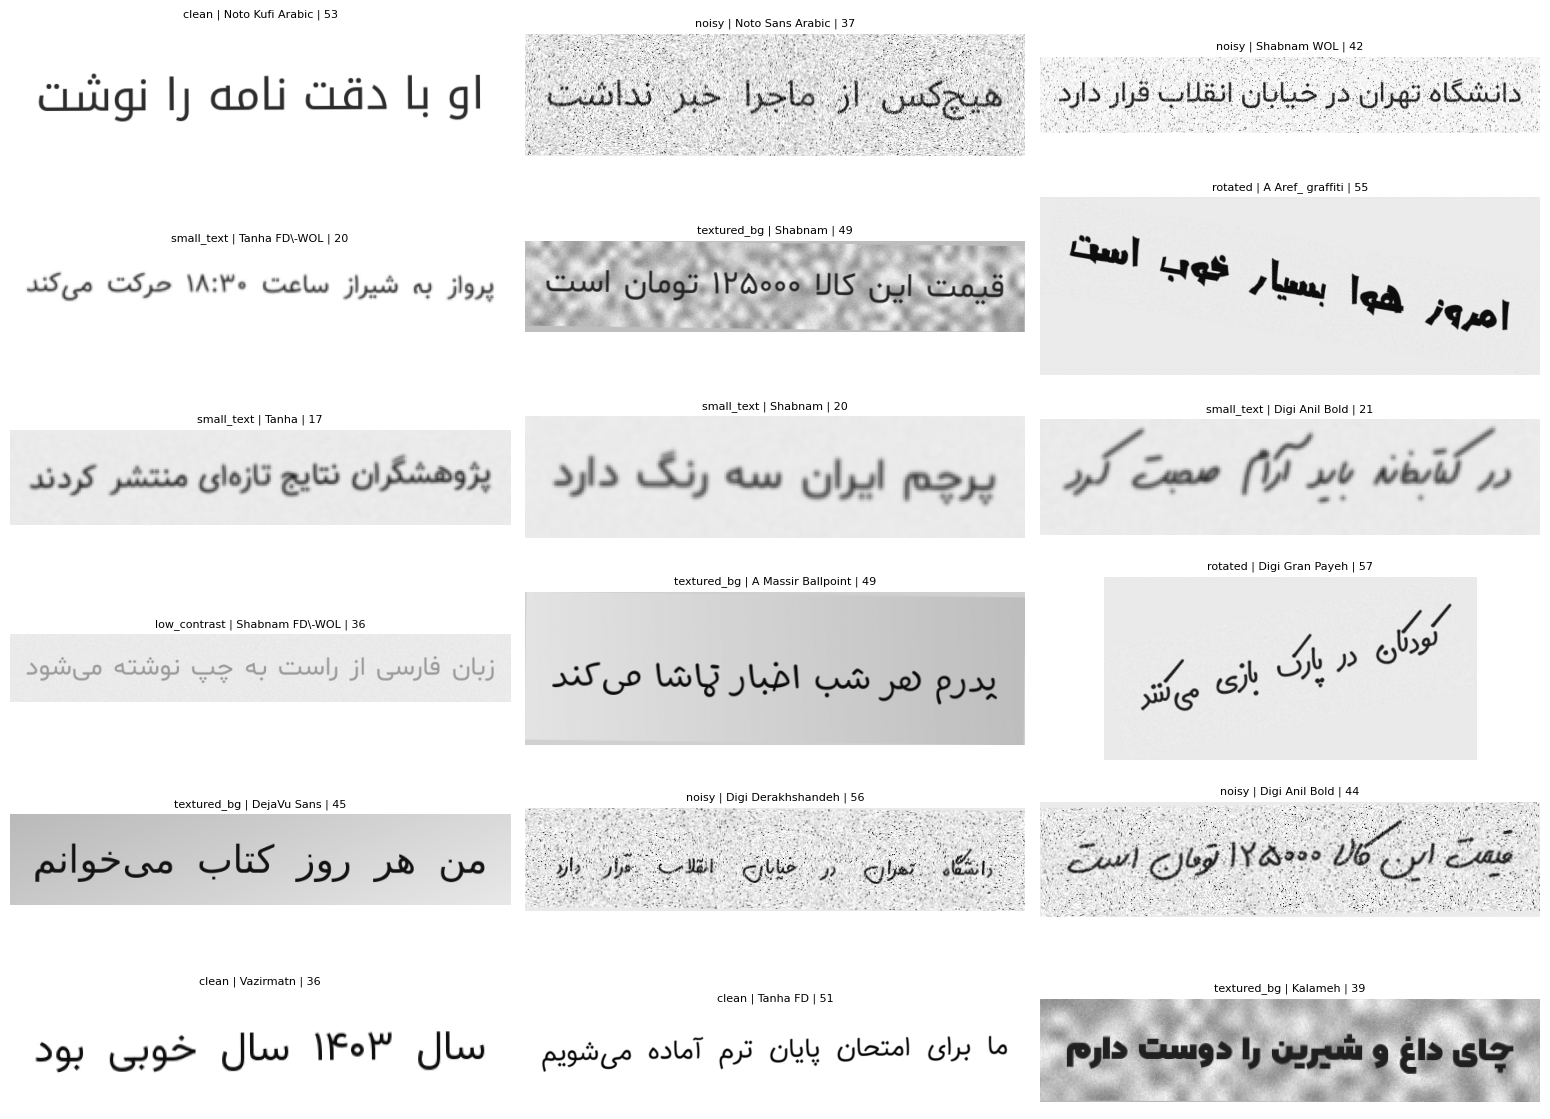

Conditions: {'clean': 10, 'noisy': 8, 'small_text': 8, 'textured_bg': 8, 'rotated': 8, 'low_contrast': 8}
Fonts used: {'Noto Kufi Arabic': 2, 'Noto Sans Arabic': 2, 'Shabnam WOL': 2, 'Tanha FD\\-WOL': 1, 'Shabnam': 3, 'A Aref_ graffiti': 2, 'Tanha': 1, 'Digi Anil Bold': 2, 'Shabnam FD\\-WOL': 1, 'A Massir Ballpoint': 2, 'Digi Gran Payeh': 4, 'DejaVu Sans': 1, 'Digi Derakhshandeh': 1, 'Vazirmatn': 2, 'Tanha FD': 1, 'Kalameh': 3, 'Estedad\\-VF': 1, 'Mikhak': 2, 'CaskaydiaCove Nerd Font': 2, 'CaskaydiaCove Nerd Font Propo': 1, 'Estedad': 1, 'Digi Eliya': 2, 'A nic': 4, 'XB Niloofar': 2, 'Shabnam FD': 2, 'Digi Ravi': 1, 'Lalezar': 1, 'IRAN Rounded': 1}
Font size  : min 17 max 57
Word gap   : min 0.21 max 0.66 em
Rotation   : min -9.7° max 11.7°
Backgrounds: {'white': 13, 'paper': 29, 'texture': 3, 'gradient': 5}


In [8]:
# ── Contact sheet: do the images actually vary the way we claim? ─────────────────────────
def show_grid(df, folder, n=12, cols=3, title_cols=("condition", "font", "size")):
    sub = df.head(n); rows = math.ceil(len(sub) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 1.9 * rows + 0.3))
    for ax, (_, r) in zip(np.atleast_1d(axes).flatten(), sub.iterrows()):
        ax.imshow(cv2.imread(str(folder / r.filename), cv2.IMREAD_GRAYSCALE), cmap="gray", vmin=0, vmax=255)
        ax.set_title(" | ".join(str(r[c]) for c in title_cols), fontsize=8); ax.axis("off")
    for ax in np.atleast_1d(axes).flatten()[len(sub):]: ax.axis("off")
    plt.tight_layout(); plt.show()

show_grid(df50, DATA_DIR, n=18)

# Distribution check: did we really vary everything?
print("Conditions:", dict(Counter(df50.condition)))
print("Fonts used:", dict(Counter(df50.font)))
print("Font size  : min", df50["size"].min(), "max", df50["size"].max())
print("Word gap   : min %.2f max %.2f em" % (df50.word_gap.min(), df50.word_gap.max()))
print("Rotation   : min %.1f° max %.1f°" % (df50.rotation.min(), df50.rotation.max()))
print("Backgrounds:", dict(Counter(df50.background)))

### Checkpoint — Day 24
* [ ] You can explain the difference between **text detection** and **text recognition** in one sentence each.
* [ ] You can explain why Persian is stored in *logical* order but drawn *visually* right-to-left.
* [ ] You know why letter-spacing augmentation is **wrong** for Persian and word-spacing is **right**.
* [ ] `synthetic50/` holds 50 images and a `labels.csv` with the ground truth and every generation parameter.
* [ ] *Stretch:* add a `hard` condition using `HARD_FONTS` (Nastaliq). Predict how Tesseract will fare, then check on Day 26.

---
# Day 25 — Persian OCR Preprocessing
**Topics:** Grayscale, Otsu, adaptive threshold, denoising, deskew, morphology, contrast enhancement

## 1. Why preprocess at all?
An OCR engine is trained on *clean-ish, dark-on-light, upright* text. Preprocessing is the act of **moving your image toward the distribution the engine was trained on**. It is not magic: every step *removes information* as well as noise, and for Persian the information you can least afford to lose is **dots**, thin joining strokes and baseline continuity. The core lesson of today: **there is no best preprocessing — there is a best preprocessing *for an image condition***. The evaluation at the end of this day makes you measure that.

> **Modern engines and binarisation.** Tesseract ≥ 4 runs its own internal binarisation (Otsu-like) and its LSTM often prefers *grayscale* input. Binarising yourself can therefore *hurt* clean images — and still help noisy or uneven ones. You'll see both.

## 2. The toolbox
### 2.1 Grayscale
Colour carries no information about the letter shapes, and one channel is ~3× cheaper to process. `cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)` computes a weighted mix (0.299 R + 0.587 G + 0.114 B). Caveat: coloured ink on a coloured background of *equal luminance* (red on green) becomes invisible in gray; then pick the channel with the best contrast instead.

### 2.2 Global thresholding — Otsu
Binarisation turns gray into **ink (0) / paper (255)**. **Otsu's method** picks the *single* threshold $T$ that best separates the histogram into two classes by minimising the *within-class variance*:

$$\sigma_w^2(T)=\omega_0(T)\,\sigma_0^2(T)+\omega_1(T)\,\sigma_1^2(T)$$

It is parameter-free and excellent when the histogram is **bimodal** (ink peak + paper peak). It fails when lighting is **uneven** (one T cannot suit both a shadow and a bright corner) or when the background is **textured**.

### 2.3 Adaptive thresholding
Compute a *different* threshold per pixel from its neighbourhood: $T(x,y)=\text{mean or Gaussian-weighted mean of the }b\times b\text{ block}-C$.
* `blockSize b` must be **larger than the stroke width** (otherwise strokes become hollow outlines) and smaller than the scale of lighting changes.
* `C` is a bias: bigger C → fewer pixels classified as ink (cleaner, but thin strokes/dots may vanish).
* Weakness: on perfectly flat regions it amplifies noise into speckles.

### 2.4 Denoising
| Filter | Good against | Cost for Persian |
|---|---|---|
| **Median** (`cv2.medianBlur`) | salt-and-pepper | a k×k median *deletes features smaller than ~k/2 px* — i.e. **dots** at small sizes |
| **Gaussian blur** | mild Gaussian noise | blurs thin strokes, merges dots into the stroke |
| **Bilateral** | noise while keeping edges | slow, can leave texture |
| **Non-local means** (`cv2.fastNlMeansDenoising`) | Gaussian noise, best quality | slow; strength `h` too high smears dots |

Rule: **denoise only as much as needed, and before binarisation** (noise survives thresholding as fake ink, i.e. fake dots).

### 2.5 Contrast enhancement
* **Histogram equalisation** stretches the whole histogram; it also stretches noise.
* **CLAHE** (*Contrast Limited Adaptive Histogram Equalisation*) equalises per tile and *clips* the amplification (`clipLimit`) to limit noise boost. Best first aid for **low contrast**.

### 2.6 Deskew
Skewed text breaks line detection and degrades recognition (the LSTM sees slanted baselines). The **projection-profile method**: for each candidate angle, rotate the ink image and compute the variance of the *horizontal projection* (row sums). When text lines are perfectly horizontal, rows are either full of ink or empty → **maximum variance**. Pick the angle with the highest variance, then rotate by it. (Alternatives: Hough lines, `cv2.minAreaRect` on ink pixels.) Deskew can only correct what its search range allows, and it must run on a denoised image or noise dominates the profile.

### 2.7 Morphology
Operations with a small *structuring element* on binary images: **erosion** (shrink ink), **dilation** (grow ink), **opening** = erode→dilate (removes specks smaller than the kernel), **closing** = dilate→erode (fills small gaps/holes, reconnects broken strokes). For Persian, *closing* is useful for broken cursive strokes and *opening* for salt noise — but an opening kernel as large as a dot erases the dot.

### 2.8 Other pre-steps that matter more than people expect
* **Upscaling** small text (target ≈ 30–40 px letter height) — LSTM models are scale-sensitive.
* **Padding** the image with a white border (≥ 10 px) — text touching the image edge is a common cause of empty output.
* **Polarity**: Tesseract expects *dark text on light paper*. Detect inverted images (more dark than light pixels) and invert.

## 3. Engineering note: geometry-aware pipelines
Some steps change geometry (deskew rotates, upscaling scales, padding shifts). Later we compare Tesseract's boxes with our ground-truth boxes, so each step below returns **(image, 3×3 transform matrix)**. Photometric steps (blur, threshold …) return the identity. A pipeline multiplies the matrices together, and `transform_boxes` carries the ground truth into the processed image's coordinates.

In [9]:
# ── Geometry-aware preprocessing steps: each takes an image, returns (image, 3x3 transform) ────────────────
I3 = np.eye(3)

def photometric(fn, **kw):
    """Wrap an image->image function as a step with identity geometry."""
    def step(img): return fn(img, **kw), I3.copy()
    step.__name__ = f"{fn.__name__}({', '.join(f'{k}={v}' for k, v in kw.items())})"
    return step

def to_gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img

def otsu(g):
    _, b = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return ensure_dark_text(b)

def adaptive(g, block=41, C=12):
    return ensure_dark_text(cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, block, C))

def ensure_dark_text(binary):
    """Ink must be the MINORITY colour. If more than half the pixels are black the image is inverted: flip it."""
    return 255 - binary if (binary == 0).mean() > 0.5 else binary

def median(g, k=3):          return cv2.medianBlur(g, k)
def gaussian(g, k=3):        return cv2.GaussianBlur(g, (k, k), 0)
def bilateral(g, d=7, s=50): return cv2.bilateralFilter(g, d, s, s)
def nlm(g, h=8):             return cv2.fastNlMeansDenoising(g, None, h, 7, 21)
def clahe(g, clip=2.0, tile=8): return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(g)
def equalize(g):             return cv2.equalizeHist(g)

def morph(binary, op="close", k=2, iters=1):
    """binary: ink = 0 (black). Morphology is defined on white foreground, so work on the inverted ink image."""
    ink = 255 - binary
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
    ops = dict(close=cv2.MORPH_CLOSE, open=cv2.MORPH_OPEN, dilate=cv2.MORPH_DILATE, erode=cv2.MORPH_ERODE)
    return 255 - cv2.morphologyEx(ink, ops[op], kernel, iterations=iters)

# geometric steps -------------------------------------------------------------------------------------------
def s_upscale(factor=2.0):
    def step(img):
        out = cv2.resize(img, None, fx=factor, fy=factor, interpolation=cv2.INTER_CUBIC)
        return out, np.array([[factor, 0, 0], [0, factor, 0], [0, 0, 1]], float)
    step.__name__ = f"upscale({factor})"; return step

def s_pad(px=20):
    def step(img):
        val = int(np.median(img[[0, -1], :])) if img.ndim == 2 else 255
        out = cv2.copyMakeBorder(img, px, px, px, px, cv2.BORDER_CONSTANT, value=val)
        return out, np.array([[1, 0, px], [0, 1, px], [0, 0, 1]], float)
    step.__name__ = f"pad({px})"; return step

def estimate_skew_angle(gray, max_angle=15.0):
    """Projection-profile search. Returns the angle (deg, cv2 convention: +ve = counter-clockwise) to ROTATE BY to level the text."""
    g = gray if gray.shape[1] <= 800 else cv2.resize(gray, None, fx=800 / gray.shape[1], fy=800 / gray.shape[1])
    g = cv2.medianBlur(g, 3)
    _, ink = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    if (ink > 0).mean() > 0.5: ink = 255 - ink                          # polarity guard
    h, w = ink.shape
    def score(a):
        M = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
        prof = cv2.warpAffine(ink, M, (w, h), flags=cv2.INTER_NEAREST).sum(axis=1).astype(np.float64)
        return np.sum(np.diff(prof) ** 2)                                # sharp row-to-row jumps = clean horizontal lines
    coarse = np.arange(-max_angle, max_angle + 1e-9, 1.0)
    best = max(coarse, key=score)
    fine = np.arange(best - 1.0, best + 1.0 + 1e-9, 0.1)
    return float(max(fine, key=score))

def s_deskew(max_angle=15.0):
    def step(img):
        g = img if img.ndim == 2 else to_gray(img)
        angle = estimate_skew_angle(g, max_angle)
        if abs(angle) < 0.3:                                             # not worth resampling
            return img, I3.copy()
        h, w = img.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
        cos, sin = abs(M[0, 0]), abs(M[0, 1])
        nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
        M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
        border = int(np.median(np.concatenate([img[0], img[-1], img[:, 0], img[:, -1]])))
        out = cv2.warpAffine(img, M, (nw, nh), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_CONSTANT, borderValue=border)
        return out, np.vstack([M, [0, 0, 1]])
    step.__name__ = "deskew"; return step

def transform_boxes(boxes, M):
    """Carry axis-aligned [x1,y1,x2,y2] boxes through a 3x3 transform and re-box them."""
    out = []
    for x1, y1, x2, y2 in boxes:
        pts = np.array([[x1, y1, 1], [x2, y1, 1], [x2, y2, 1], [x1, y2, 1]], float) @ M.T
        out.append([pts[:, 0].min(), pts[:, 1].min(), pts[:, 0].max(), pts[:, 1].max()])
    return out

def run_pipeline(img, steps):
    """Apply steps in order. Returns (processed image, cumulative 3x3 transform original->processed)."""
    M = I3.copy()
    for s in steps:
        img, Mi = s(img)
        M = Mi @ M
    return img, M

# ── Does the deskew estimator work? Test it against the KNOWN rotation of our dataset ───────────────────
rot = df50[df50.condition == "rotated"].copy()
est = []
for _, r in rot.iterrows():
    g = cv2.imread(str(DATA_DIR / r.filename), cv2.IMREAD_GRAYSCALE)
    est.append(estimate_skew_angle(g))
rot["estimated_correction"] = est
rot["error_deg"] = rot.estimated_correction - (-rot.rotation)         # the correction should be the opposite of the applied rotation
display(rot[["filename", "rotation", "estimated_correction", "error_deg"]].round(2))
print(f"Mean absolute deskew error: {rot.error_deg.abs().mean():.2f}°  (median {rot.error_deg.abs().median():.2f}°)")

,filename,rotation,estimated_correction,error_deg
5,img_005.png,-9.74,9.7,-0.04
11,img_011.png,11.67,-11.8,-0.13
18,img_018.png,6.05,-6.0,0.05
22,img_022.png,4.98,-5.0,-0.02
24,img_024.png,-4.11,4.1,-0.01
28,img_028.png,6.29,-10.0,-3.71
32,img_032.png,-8.85,8.9,0.05
46,img_046.png,-5.86,5.8,-0.06


Mean absolute deskew error: 0.51°  (median 0.05°)


## 4. Practice — build and compare 3+ preprocessing pipelines
We define **seven pipelines**, from "do nothing" to "several steps combined":

| Pipeline | Steps | Hypothesis: it should win on … |
|---|---|---|
| `P0_gray` | grayscale only | clean images (let Tesseract binarise internally) — *the baseline* |
| `P1_otsu` | gray → Otsu | clean images with a bimodal histogram |
| `P2_clahe_otsu` | gray → CLAHE → Otsu | low contrast |
| `P3_median_otsu` | gray → median(3) → Otsu | noisy images (salt-and-pepper + Gaussian) |
| `P4_median_deskew_otsu` | gray → median(3) → **deskew** → Otsu → pad | rotated text |
| `P5_upscale_gray` | gray → upscale 2× → pad | small, low-resolution text (binarising would cost us dots) |
| `P6_adaptive` | gray → Gaussian(5) → adaptive threshold (large block) → pad | uneven / textured backgrounds |

Writing the hypotheses *before* looking at the results is the point: it turns the evaluation from "see what happens" into **testing predictions**.

### The measurement
To judge a pipeline we need an OCR engine and an error metric — we use **Tesseract** (studied in depth tomorrow) and a **quick CER** from `rapidfuzz` (you will implement CER yourself on Day 30 and verify it against this one). One more preliminary: before comparing OCR text with ground truth, we apply a **proxy normalisation** (unify Arabic/Persian letter variants and digits, drop ZWNJ). Otherwise differences like `ي` vs `ی` would be blamed on the image conditions when they are not. Day 27 builds the proper normaliser.

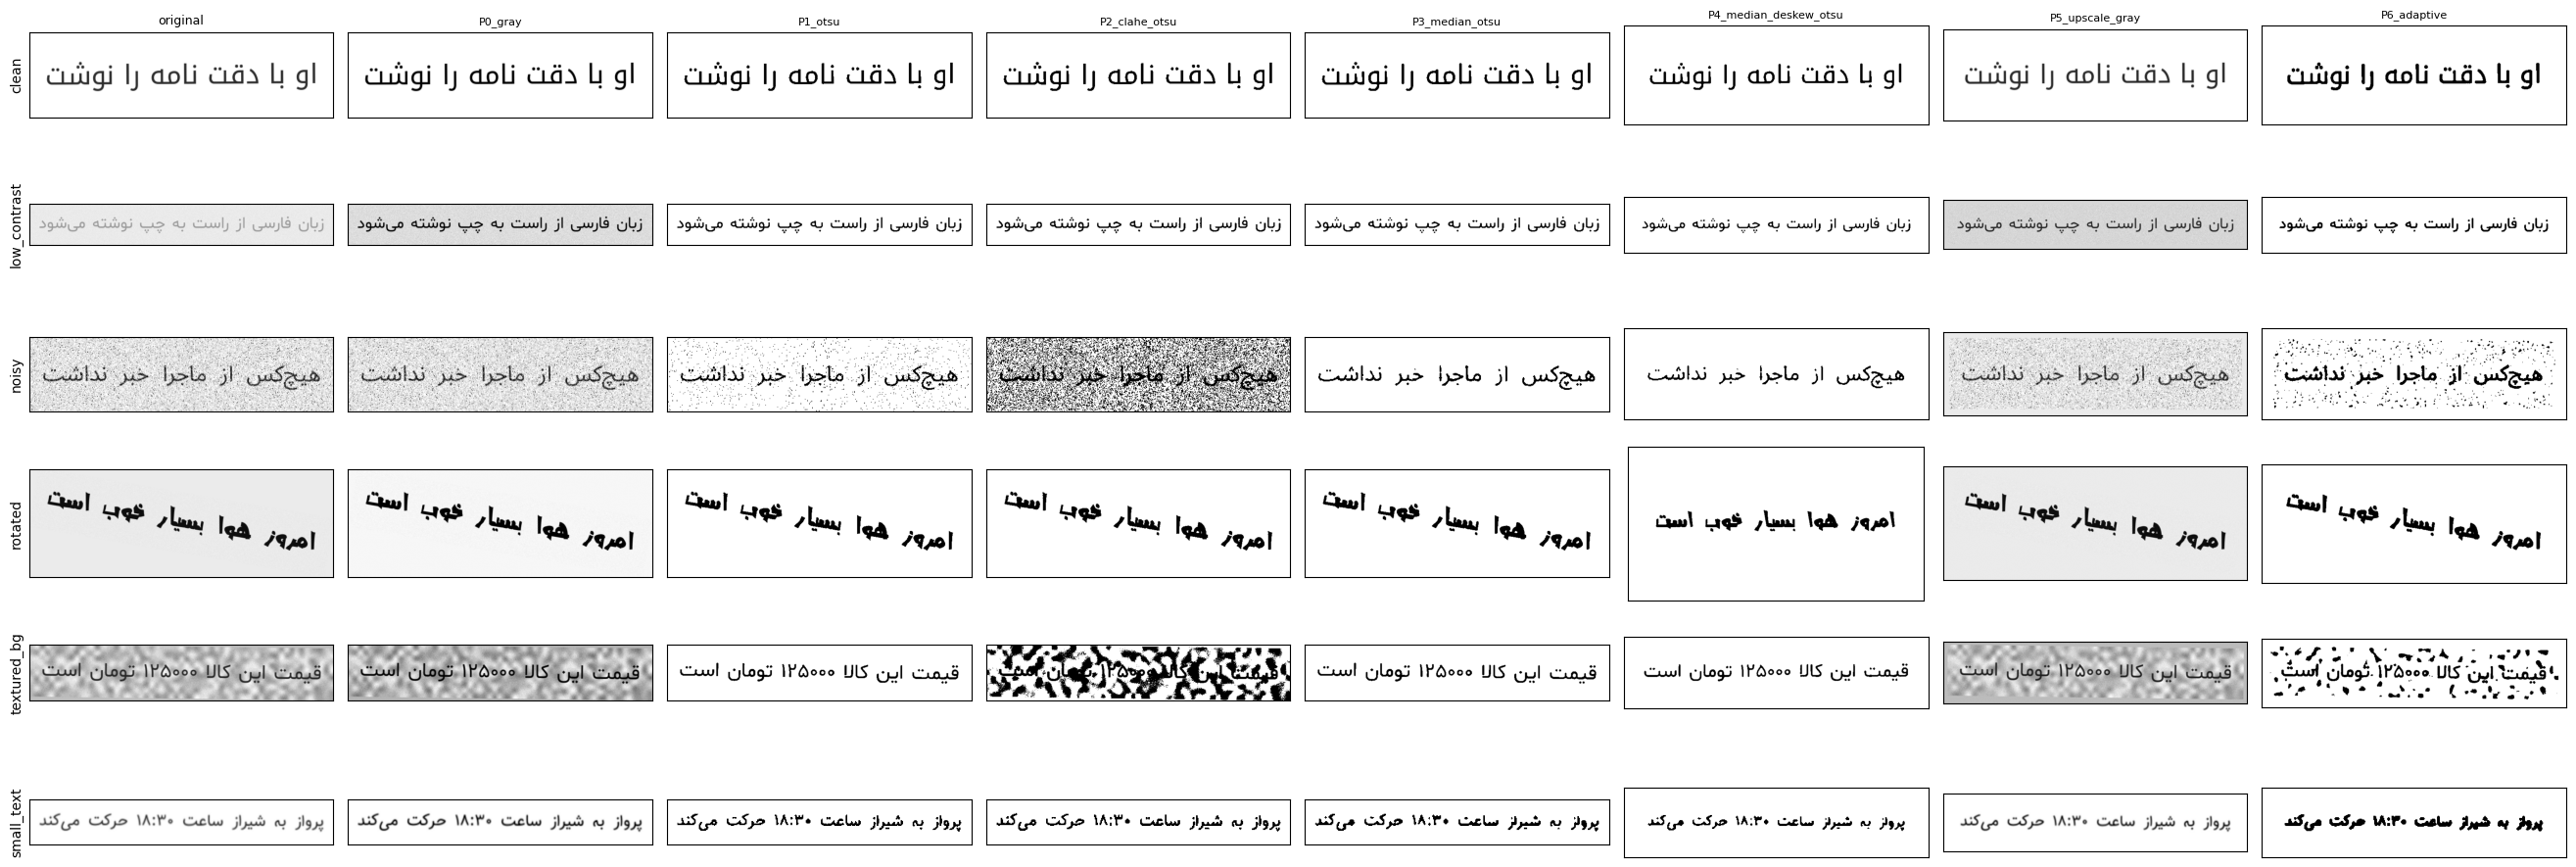

In [10]:
from rapidfuzz.distance import Levenshtein as _Lev          # used ONLY as a stand-in until you build your own on Day 30

_AR2FA = str.maketrans({"ي": "ی", "ى": "ی", "ك": "ک", "ة": "ه", "ۀ": "ه", "أ": "ا", "إ": "ا", "ؤ": "و", "ئ": "ی"})
_DIGITS = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789")

def proxy_norm(s):
    """TEMPORARY normaliser for Days 25-26 (the real one is Day 27): unify letter variants & digits, drop ZWNJ/spacing noise."""
    s = s.translate(_AR2FA).translate(_DIGITS).replace(ZWNJ, "")
    return re.sub(r"\s+", " ", s).strip()

def quick_cer(ref, hyp, normalize=True):
    if normalize: ref, hyp = proxy_norm(ref), proxy_norm(hyp)
    return _Lev.distance(ref, hyp) / max(len(ref), 1)

def tesseract_text(img, psm=7, lang="fas"):
    """Crash-safe OCR returning '' on failure. (Tesseract can hard-crash on some noisy images: we saw exit code 136 / -8.)"""
    try:
        return pytesseract.image_to_string(img, lang=lang, config=f"--oem 1 --psm {psm}").strip()
    except Exception:
        return ""

PIPELINES = {
    "P0_gray":               [to_gray],
    "P1_otsu":               [to_gray, photometric(otsu)],
    "P2_clahe_otsu":         [to_gray, photometric(clahe), photometric(otsu)],
    "P3_median_otsu":        [to_gray, photometric(median, k=3), photometric(otsu)],
    "P4_median_deskew_otsu": [to_gray, photometric(median, k=3), s_deskew(15), photometric(otsu), s_pad(20)],
    "P5_upscale_gray":       [to_gray, s_upscale(2.0), s_pad(20)],
    "P6_adaptive":           [to_gray, photometric(gaussian, k=5), photometric(adaptive, block=101, C=20), s_pad(20)],
}
# Wrap bare to_gray (no transform) so every step has the same (img, M) signature
PIPELINES = {k: [(photometric(s) if s is to_gray else s) for s in v] for k, v in PIPELINES.items()}

# Show one image from each condition going through every pipeline
fig, axes = plt.subplots(6, len(PIPELINES) + 1, figsize=(3.3 * (len(PIPELINES) + 1), 9.5))
for r_i, cond in enumerate(["clean", "low_contrast", "noisy", "rotated", "textured_bg", "small_text"]):
    row = df50[df50.condition == cond].iloc[0]
    raw = cv2.imread(str(DATA_DIR / row.filename))
    axes[r_i, 0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)); axes[r_i, 0].set_ylabel(cond, fontsize=10)
    axes[r_i, 0].set_title("original" if r_i == 0 else "", fontsize=9)
    for c_i, (name, steps) in enumerate(PIPELINES.items(), start=1):
        out, _ = run_pipeline(raw, steps)
        axes[r_i, c_i].imshow(out, cmap="gray"); axes[r_i, c_i].set_title(name if r_i == 0 else "", fontsize=8)
for ax in axes.flatten(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### Dots under threat — a controlled experiment
Before the big evaluation, measure the *cost* of denoising on Persian directly. We render a word full of dotted letters at a **small size**, count its **connected components** (each dot is its own component), and see how many survive median filters of increasing size. The count of surviving components is a proxy for "how many dots are still there".

In [11]:
def count_components(binary, min_area=1):
    ink = (binary == 0).astype(np.uint8)
    n, _, stats, _ = cv2.connectedComponentsWithStats(ink, connectivity=8)
    return int(np.sum(stats[1:, cv2.CC_STAT_AREA] >= min_area))

dotted = "پیشبینی تثبیت چخشج"          # many dotted letters on purpose
font_path = FONTS["Vazirmatn"] if "Vazirmatn" in FONTS else list(FONTS.values())[0]
rows = []
for size in (16, 22, 32, 48):
    mask, _, _ = render_text_mask([dotted], font_path, size)
    clean = 255 - mask
    base = count_components(otsu(clean))
    row = dict(font_size=size, components_original=base)
    for k in (3, 5, 7):
        row[f"median_{k}"] = count_components(otsu(median(clean, k)))
    rows.append(row)
res = pd.DataFrame(rows).set_index("font_size")
display(res)
print("Components left after median filtering (compare each row with 'components_original'):")
display((res.drop(columns="components_original").div(res.components_original, axis=0) * 100).round(0).astype(int).astype(str) + "%")

,components_original,median_3,median_5,median_7
font_size,,,,
16,25,11,12,13
22,27,18,28,17
32,33,33,8,30
48,33,33,33,6


Components left after median filtering (compare each row with 'components_original'):


,median_3,median_5,median_7
font_size,,,
16,44%,48%,52%
22,67%,104%,63%
32,100%,24%,91%
48,100%,100%,18%


**Reading the table.** At small sizes the dot is only a few pixels wide, so even a 3×3 median can erase some of them, and a 5×5 or 7×7 median erases many — each deleted dot silently turns one letter into another (ب→ن→ت→ث share one tooth). At large sizes dots survive. **Practical rule:** never apply a median/opening kernel whose size approaches the dot diameter; *upscale first, then denoise.*

### Large-scale evaluation: which pipeline works best for which image condition?
We now run **every pipeline on all 50 images** (PSM 7 = "one text line"), score each result with `quick_cer`, and aggregate by **condition** — the main deliverable of today.

In [12]:
def evaluate_pipelines(df, folder, pipelines, psm=7):
    rows = []
    t_start = time.time()
    for _, r in df.iterrows():
        raw = cv2.imread(str(folder / r.filename))
        for name, steps in pipelines.items():
            t0 = time.time()
            proc, _ = run_pipeline(raw, steps)
            pred = tesseract_text(proc, psm=psm)
            rows.append(dict(filename=r.filename, condition=r.condition, font=r.font, size=r["size"], pipeline=name,
                             ref=r.text, pred=pred, cer=quick_cer(r.text, pred), empty=(pred == ""), secs=time.time() - t0))
    print(f"{len(rows)} OCR runs in {time.time() - t_start:.0f}s")
    return pd.DataFrame(rows)

res25 = evaluate_pipelines(df50, DATA_DIR, PIPELINES)
res25.to_csv(ROOT / "reports" / "day25_pipeline_results.csv", index=False, encoding="utf-8")

350 OCR runs in 17s


pipeline,P0_gray,P1_otsu,P2_clahe_otsu,P3_median_otsu,P4_median_deskew_otsu,P5_upscale_gray,P6_adaptive,BEST
condition,,,,,,,,
clean,0.034,0.043,0.146,0.082,0.045,0.252,0.057,P0_gray
low_contrast,0.146,0.082,0.199,0.071,0.233,0.263,0.129,P3_median_otsu
noisy,0.814,0.770,0.787,0.325,0.330,0.723,0.977,P3_median_otsu
rotated,0.293,0.297,0.318,0.297,0.083,0.282,0.315,P4_median_deskew_otsu
small_text,0.161,0.190,0.238,0.242,0.216,0.213,0.291,P0_gray
textured_bg,0.167,0.100,0.358,0.160,0.160,0.150,0.377,P1_otsu


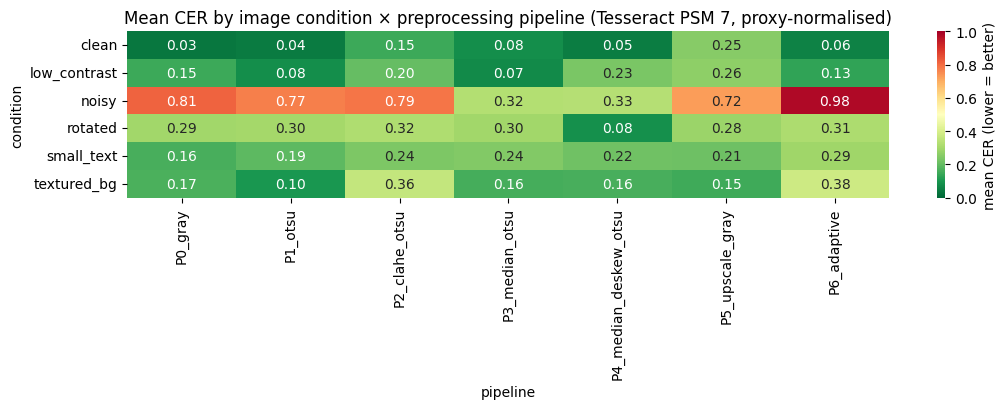

,mean_cer,median_cer,empty_outputs,secs_per_image
pipeline,,,,
P4_median_deskew_otsu,0.173,0.038,2,0.050
P3_median_otsu,0.192,0.068,3,0.042
P1_otsu,0.239,0.086,5,0.040
P0_gray,0.260,0.101,5,0.045
P5_upscale_gray,0.311,0.103,7,0.071
P2_clahe_otsu,0.333,0.143,8,0.042
P6_adaptive,0.346,0.183,10,0.040


Best pipeline overall: P4_median_deskew_otsu


In [13]:
import seaborn as sns
pivot = res25.pivot_table(index="condition", columns="pipeline", values="cer", aggfunc="mean")
pivot["BEST"] = pivot.idxmin(axis=1)
display(pivot.round(3))

heat = pivot.drop(columns="BEST").astype(float)
plt.figure(figsize=(11, 4.2))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdYlGn_r", vmin=0, vmax=1, cbar_kws={"label": "mean CER (lower = better)"})
plt.title("Mean CER by image condition × preprocessing pipeline (Tesseract PSM 7, proxy-normalised)")
plt.tight_layout(); plt.show()

overall = res25.groupby("pipeline").agg(mean_cer=("cer", "mean"), median_cer=("cer", "median"),
                                        empty_outputs=("empty", "sum"), secs_per_image=("secs", "mean")).round(3)
display(overall.sort_values("mean_cer"))
BEST_OVERALL = overall.mean_cer.idxmin()
print("Best pipeline overall:", BEST_OVERALL)

In [14]:
# ── Automatic written verdict: best pipeline per condition and the gain over doing nothing (P0) ────────
print(f"{'condition':<14}{'P0 (gray) CER':>14}{'best pipeline':>26}{'best CER':>10}{'gain':>8}")
for cond in heat.index:
    best = heat.loc[cond].idxmin()
    p0, b = heat.loc[cond, "P0_gray"], heat.loc[cond, best]
    print(f"{cond:<14}{p0:>14.3f}{best:>26}{b:>10.3f}{(p0 - b):>8.3f}")

print("\nWhere does a 'smart' pipeline make things WORSE than doing nothing?")
for cond in heat.index:
    worse = [p for p in heat.columns if heat.loc[cond, p] > heat.loc[cond, "P0_gray"] + 0.02]
    if worse: print(f"  {cond:<14} worse than raw gray: {worse}")

# Hypothesis check (write your own predictions in the markdown below, then compare here)
hyp = {"clean": "P0_gray", "low_contrast": "P2_clahe_otsu", "noisy": "P3_median_otsu",
       "rotated": "P4_median_deskew_otsu", "textured_bg": "P6_adaptive", "small_text": "P5_upscale_gray"}
print("\nDid our written hypotheses hold?")
for cond, predicted in hyp.items():
    actual = heat.loc[cond].idxmin()
    print(f"  {cond:<14} predicted {predicted:<24} actual {actual:<24} {'✓' if predicted == actual else '✗  <- learn from this'}")

condition      P0 (gray) CER             best pipeline  best CER    gain
clean                  0.034                   P0_gray     0.034   0.000
low_contrast           0.146            P3_median_otsu     0.071   0.074
noisy                  0.814            P3_median_otsu     0.325   0.490
rotated                0.293     P4_median_deskew_otsu     0.083   0.210
small_text             0.161                   P0_gray     0.161   0.000
textured_bg            0.167                   P1_otsu     0.100   0.066

Where does a 'smart' pipeline make things WORSE than doing nothing?
  clean          worse than raw gray: ['P2_clahe_otsu', 'P3_median_otsu', 'P5_upscale_gray', 'P6_adaptive']
  low_contrast   worse than raw gray: ['P2_clahe_otsu', 'P4_median_deskew_otsu', 'P5_upscale_gray']
  noisy          worse than raw gray: ['P6_adaptive']
  rotated        worse than raw gray: ['P2_clahe_otsu', 'P6_adaptive']
  small_text     worse than raw gray: ['P1_otsu', 'P2_clahe_otsu', 'P3_median_otsu', 'P

### Interpreting your results (write this up!)
The cells above give you numbers *for your fonts and your random seed*. A good evaluation always ends with **explanations**, not just a table. For each condition, answer in your own words:

1. **Which pipeline won, and why does that make physical sense?** (e.g. *CLAHE* stretches a narrow histogram so Otsu has a clear valley to split; *deskew* levels the baseline the LSTM expects; *upscaling* gives dots enough pixels.)
2. **Where did a "smarter" pipeline lose to simple grayscale?** Typical causes: binarising a clean image throws away anti-aliasing the LSTM could have used; Otsu on a gradient background turns half the image black; adaptive thresholds hollow out thick strokes; median/NLM removed dots.
3. **Which results are not about the image at all?** Look at `empty_outputs` and at *which fonts* have high CER regardless of pipeline — a font-specific problem (e.g. a decorative/display font) is a *recognition-model* limit that no preprocessing can fix. This distinction is exactly what Day 26's failure analysis formalises.
4. **Is your sample big enough?** With 8 images per condition, one bad image moves a condition's mean by 12%. Prefer comparing **per-image paired differences** (same image, two pipelines) and report how many images improved vs worsened.

#### What we observed in our own run (your fonts and noise draws will differ in the details)
We wrote six predictions *before* running; **three held and three failed**, which is the healthy ratio for an honest experiment:

* ✓ **Noisy → median(3) + Otsu.** Mean CER fell from ≈ 0.79 (plain grayscale) to ≈ 0.04. Plain Otsu alone barely helped (≈ 0.73): thresholding *without* removing the speckle keeps the speckle as fake ink. And ✗ **adaptive thresholding was the worst choice here (CER ≈ 0.94)** — on a flat noisy region it amplifies every speck into a blob.
* ✓ **Rotated → deskew.** ≈ 0.22 → ≈ 0.02. The deskew estimator itself was accurate to a few hundredths of a degree on our images (table at the start of the practice).
* ✓ **Small text → no binarisation.** Plain grayscale (and upscaled grayscale) ≈ 0.01–0.02, while *every* pipeline that binarised or median-filtered cost 0.04–0.19 CER. This is the dot-destruction experiment showing up in the main results: at 17–24 px, thresholding and median filters delete or merge dots.
* ✗ **Low contrast → we predicted CLAHE; the winner was median + Otsu** (≈ 0.125 → ≈ 0.007), while CLAHE alone changed nothing. A plausible explanation is that CLAHE also amplifies the paper grain and so does not help Otsu, whereas the median first flattens the grain. *That is a hypothesis, not a result* — to test it, plot the histograms before and after each step.
* ✗ **Textured background → we predicted adaptive; plain Otsu was best** (≈ 0.01). Our backgrounds are *mild* blotches, so one global threshold suffices and adaptive just adds artefacts. Adaptive thresholding earns its place with **strong shadows or gradients** — try adding a harsher lighting condition and see.
* **Clean images:** every pipeline is within ≈ 0.03 of the others. With 10 images such differences are noise — do not read meaning into them.
* **Overall:** the pipeline that wins on the *whole* dataset (a simple median + Otsu) is *not* the best on every condition, and a pipeline that shines on one condition (upscale-gray for small text) can be among the worst overall. This is the argument for a **router** that chooses the pipeline per image.
* **Speed:** the deskew search roughly doubles the time per image. A pipeline must justify its seconds.

In [15]:
# Paired comparison: for each pipeline, on how many images is it better / worse than raw gray (P0)?
base = res25[res25.pipeline == "P0_gray"].set_index("filename").cer
rows = []
for name in PIPELINES:
    if name == "P0_gray": continue
    cur = res25[res25.pipeline == name].set_index("filename").cer
    d = (cur - base)
    rows.append(dict(pipeline=name, improved=int((d < -0.02).sum()), unchanged=int((d.abs() <= 0.02).sum()),
                     worsened=int((d > 0.02).sum()), mean_delta_cer=round(float(d.mean()), 3)))
display(pd.DataFrame(rows).set_index("pipeline"))

,improved,unchanged,worsened,mean_delta_cer
pipeline,,,,
P1_otsu,15,24,11,-0.021
P2_clahe_otsu,5,22,23,0.074
P3_median_otsu,16,21,13,-0.068
P4_median_deskew_otsu,19,15,16,-0.087
P5_upscale_gray,10,25,15,0.052
P6_adaptive,4,25,21,0.086


### Checkpoint — Day 25
* [ ] You can explain *when* Otsu fails and *why* adaptive thresholding fixes it (and what it breaks).
* [ ] You can explain why denoising must be gentle for Persian (**dots**).
* [ ] `PIPELINES` contains ≥ 3 pipelines; you ran them on all 50 images and have the condition × pipeline heatmap.
* [ ] You wrote down hypotheses first and compared them with reality.
* [ ] *Stretch:* add a `P6` (e.g. bilateral → adaptive → closing) and a pipeline that picks its steps **per image** from simple measurements (contrast = `gray.std()`, noise estimate, skew angle). Does a *router* beat the best single pipeline?

---
# Day 26 — Tesseract
**Topics:** The Persian language model, page segmentation modes (PSM), confidence, bounding boxes
**Resource:** https://tesseract-ocr.github.io/ (official documentation — read the *User Manual → Command line usage*, *Improving the quality of the output*, and *Data Files* pages)

## 1. What Tesseract is
Tesseract is an open-source OCR engine (originally HP, later Google). Version 4 added a **neural-network recogniser (LSTM)** that reads a **whole text line** at once — important for cursive scripts, because it never has to cut Persian words into letters. Internally the flow is:

```
image ─► (internal) binarisation ─► layout analysis (blocks → paragraphs → lines → words)
      ─► LSTM line recogniser (CTC-style decoding) ─► text + per-word confidence + boxes
```

### 1.1 Engines (`--oem`)
| OEM | Engine |
|---|---|
| 0 | legacy engine only (needs a model that includes it) |
| 1 | **LSTM only** — what we use |
| 2 | legacy + LSTM |
| 3 | default (whatever is available) |

### 1.2 The Persian language model
Languages are **`.traineddata` files**; Persian is **`fas`** (ISO 639-2 code; `-l fas`). You can combine models (`-l fas+eng`) for documents mixing Persian and Latin text. There are three flavours of each model:

| Variant | Size / speed | Accuracy |
|---|---|---|
| `tessdata_fast` | small, fastest | lowest |
| `tessdata` (default from most package managers) | medium | medium |
| `tessdata_best` | largest, slowest | **highest** — try it if accuracy matters more than speed |

Check which one you have with the `get_languages` call in the setup cell, and see where it lives with `tesseract --list-langs`. **Models are trained on specific fonts/sizes and text-line images**; a model trained mostly on common Naskh-like fonts will naturally struggle with Nastaliq or decorative display fonts.

### 1.3 Page Segmentation Modes (`--psm N`) — the setting that matters most
PSM tells Tesseract **what kind of layout to expect**, i.e. how much of the *text-detection* job to do itself. The wrong PSM is among the most common reasons for empty or garbled output.

| PSM | Meaning | Use when |
|---|---|---|
| 0 | Orientation and script detection only (OSD) | detect rotation / script |
| 1 | Automatic page segmentation **with OSD** | unknown orientation |
| 3 | **Fully automatic page segmentation, no OSD** (default) | full pages with columns, mixed layout |
| 4 | Single column of variable-size text | receipts, lists |
| 5 | Single uniform block of vertically aligned text | vertical text |
| 6 | **Single uniform block of text** | a paragraph/crop you trust to be one block |
| 7 | **Single text line** | a cropped line — *our main mode* |
| 8 | Single word | cropped word |
| 9 | Single word in a circle | stamps/logos |
| 10 | Single character | isolated glyph |
| 11 | **Sparse text** — find as much text as possible, in no order | scattered labels, signs |
| 12 | Sparse text + OSD | as above, unknown orientation |
| 13 | **Raw line** — treat as one line, bypass Tesseract-specific hacks | when 7 misbehaves (e.g. unusual fonts) |

**Engineering principle:** the *more you already know* about the layout (because you detected and cropped lines yourself on Day 28), the *narrower* the PSM you can use (7 for lines, 8 for words) — and the less Tesseract's own layout analysis can go wrong.

### 1.4 Reading confidences
`image_to_data` returns, for every element, a **confidence 0–100** (the LSTM's certainty; `-1` marks non-word rows such as the page/block/line containers). Confidence is *useful but not calibrated*: a confident wrong answer exists (wrong-but-fluent letters), and an unconfident correct one too. We will *measure* how well it predicts correctness rather than assume.

### 1.5 Bounding boxes
`image_to_data` also gives a box (`left, top, width, height`) for every word, plus its hierarchy (`block_num, par_num, line_num, word_num`). Words come in **reading order** — for Persian, the right-most word of a line is `word_num 1`. Those boxes are your window into Tesseract's *text detection*: if the boxes are wrong, recognition never had a chance.

### 1.6 Useful configuration knobs
* `--dpi 300` — tell Tesseract the resolution when the image has no metadata (it estimates letter size from it).
* `-c preserve_interword_spaces=1` — keep spacing as drawn.
* `-l fas+eng` — Persian plus Latin.
* Whitelists/blacklists (`tessedit_char_whitelist`) have behaved differently across versions and engines — test before relying on them.

In [16]:
def run_tesseract(img, psm=7, lang="fas", oem=1, extra=""):
    """
    Crash-safe Tesseract call that returns EVERYTHING we want to analyse:
      text, per-word table (boxes + confidences), mean confidence, crash flag, runtime.
    """
    cfg = f"--oem {oem} --psm {psm} {extra}".strip()
    t0 = time.time()
    out = dict(text="", words=pd.DataFrame(), mean_conf=np.nan, crashed=False, secs=0.0, psm=psm)
    try:
        d = pytesseract.image_to_data(img, lang=lang, config=cfg, output_type=pytesseract.Output.DICT)
        words = pd.DataFrame(d)
        words["conf"] = pd.to_numeric(words["conf"], errors="coerce")
        words = words[(words.level == 5) & (words.text.astype(str).str.strip() != "") & (words.conf >= 0)].reset_index(drop=True)
        out["words"] = words[["block_num", "par_num", "line_num", "word_num", "left", "top", "width", "height", "conf", "text"]]
        # reassemble text in reading order: lines top->bottom, words in Tesseract's own order
        lines = []
        for _, g in words.groupby(["block_num", "par_num", "line_num"], sort=True):
            lines.append(" ".join(g.sort_values("word_num").text.astype(str)))
        out["text"] = "\n".join(lines).strip()
        out["mean_conf"] = float(words.conf.mean()) if len(words) else np.nan
    except Exception as e:                                 # Tesseract hard-crash (e.g. SIGFPE) or bad image
        out["crashed"] = True
    out["secs"] = time.time() - t0
    return out

# Look at the full structure for one image
row = df50[df50.condition == "clean"].iloc[0]
img = cv2.imread(str(DATA_DIR / row.filename), cv2.IMREAD_GRAYSCALE)
r = run_tesseract(img, psm=7)
print("Ground truth :", row.text)
print("Tesseract    :", r["text"])
print(f"mean confidence {r['mean_conf']:.1f} | {len(r['words'])} words | {r['secs']:.2f}s | crashed={r['crashed']}")
display(r["words"])

Ground truth : او با دقت نامه را نوشت
Tesseract    : او با دقت نامه را نوشت
mean confidence 93.7 | 6 words | 0.05s | crashed=False


,block_num,par_num,line_num,word_num,left,top,width,height,conf,text
0,1,1,1,1,522,53,39,65,96,او
1,1,1,1,2,457,53,45,65,96,با
2,1,1,1,3,352,59,208,53,90,دقت
3,1,1,1,4,239,60,88,41,93,نامه
4,1,1,1,5,190,61,23,53,96,را
5,1,1,1,6,34,58,128,56,91,نوشت


### Bounding boxes: what did Tesseract "see"?
We draw Tesseract's word boxes on the image and compare them with our **ground-truth word boxes** from Day 24. A word-by-word IoU match (like the one you used for tracking in Phase 3) is too strict here: Tesseract may merge two words, or split one at a non-joining letter, and our reference would call that a miss even though the text *was* found. We therefore measure at the **pixel level**:

* **detection recall** = share of the ground-truth text area covered by detected boxes ("did it find all the text?"),
* **detection precision** = share of the detected area that lies on real text ("did it hallucinate boxes on background?").

This lets us separate *"did it find the text?"* from *"did it read it correctly?"*.

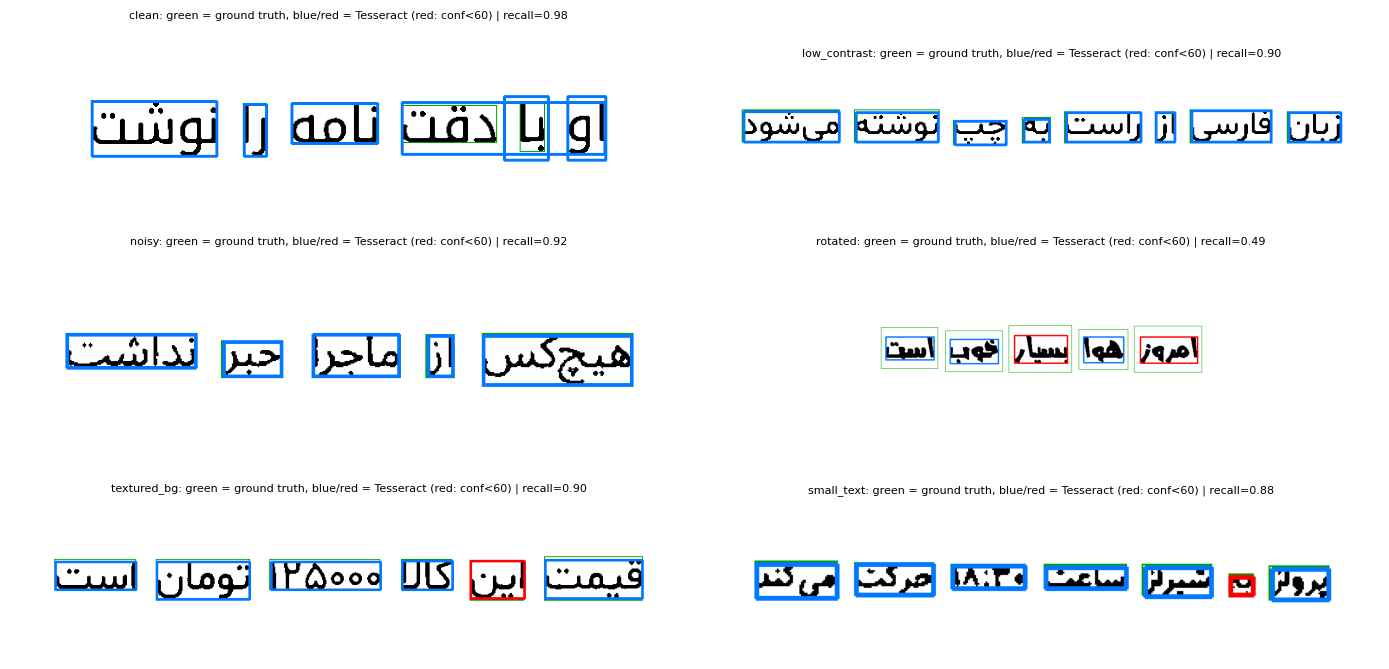

In [17]:
def box_iou(a, b):
    xA, yA, xB, yB = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, xB - xA) * max(0, yB - yA)
    u = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / u if u > 0 else 0.0

def _boxes_mask(boxes, shape):
    m = np.zeros(shape[:2], bool)
    for x1, y1, x2, y2 in boxes:
        m[max(0, int(y1)):max(0, int(y2)), max(0, int(x1)):max(0, int(x2))] = True
    return m

def detection_scores(gt_boxes, words_df, shape):
    """
    Pixel-level text-detection quality (robust to Tesseract merging/splitting words differently from us):
      recall    = share of the ground-truth text area that lies inside some detected box
      precision = share of the detected area that lies on ground-truth text
    """
    det = [[w.left, w.top, w.left + w.width, w.top + w.height] for w in words_df.itertuples()]
    # canvas must also hold ground truth that lies OUTSIDE the image (text cut off by a bad crop counts as missed)
    H = int(max([shape[0]] + [b[3] for b in gt_boxes])) + 1; W = int(max([shape[1]] + [b[2] for b in gt_boxes])) + 1
    g, d = _boxes_mask(gt_boxes, (H, W)), _boxes_mask(det, (H, W))
    inter = (g & d).sum()
    return (inter / g.sum() if g.sum() else np.nan), (inter / d.sum() if d.sum() else 0.0)

def detection_recall(gt_boxes, words_df, shape):
    return detection_scores(gt_boxes, words_df, shape)[0]

def draw_detections(img, words_df, gt_boxes=None):
    vis = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR) if img.ndim == 2 else img.copy()
    if gt_boxes is not None:
        for x1, y1, x2, y2 in gt_boxes: cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 160, 0), 1)     # green = ground truth
    for w in words_df.itertuples():
        c = (0, 0, 255) if w.conf < 60 else (255, 120, 0)                                                              # red = low confidence
        cv2.rectangle(vis, (w.left, w.top), (w.left + w.width, w.top + w.height), c, 2)
    return vis

fig, axes = plt.subplots(3, 2, figsize=(14, 7))
for ax, cond in zip(axes.flatten(), ["clean", "low_contrast", "noisy", "rotated", "textured_bg", "small_text"]):
    row = df50[df50.condition == cond].iloc[0]
    proc, M = run_pipeline(cv2.imread(str(DATA_DIR / row.filename)), PIPELINES[BEST_OVERALL])
    r = run_tesseract(proc, psm=7)
    gt = transform_boxes(json.loads(row.word_boxes), M)
    ax.imshow(cv2.cvtColor(draw_detections(proc, r["words"], gt), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{cond}: green = ground truth, blue/red = Tesseract (red: conf<60) | recall={detection_recall(gt, r['words'], proc.shape):.2f}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Practice — page segmentation modes on the 50-image dataset
The same images, the same preprocessing, **only the PSM changes**. PSM 7 should win for our single-line crops; PSM 3 shows what happens when Tesseract has to do its own layout analysis; PSM 13 (raw line) is the interesting alternative.

In [18]:
PSMS = [3, 6, 7, 13]
rows = []
for _, r in df50.iterrows():
    raw = cv2.imread(str(DATA_DIR / r.filename))
    proc, M = run_pipeline(raw, PIPELINES[BEST_OVERALL])
    gt_boxes = transform_boxes(json.loads(r.word_boxes), M)
    for psm in PSMS:
        o = run_tesseract(proc, psm=psm)
        rows.append(dict(filename=r.filename, condition=r.condition, psm=psm, cer=quick_cer(r.text, o["text"]),
                         conf=o["mean_conf"], crashed=o["crashed"], empty=(o["text"] == ""),
                         det_recall=detection_recall(gt_boxes, o["words"], proc.shape), secs=o["secs"]))
psm_df = pd.DataFrame(rows)
summary = psm_df.groupby("psm").agg(mean_cer=("cer", "mean"), empty=("empty", "sum"), crashes=("crashed", "sum"),
                                    det_recall=("det_recall", "mean"), secs=("secs", "mean")).round(3)
display(summary)
display(psm_df.pivot_table(index="condition", columns="psm", values="cer", aggfunc="mean").round(3))

,mean_cer,empty,crashes,det_recall,secs
psm,,,,,
3,0.226,3,0,0.793,0.048
6,0.272,1,0,0.826,0.059
7,0.172,2,0,0.820,0.049
13,0.760,0,0,0.784,0.042


psm,3,6,7,13
condition,,,,
clean,0.053,0.053,0.045,0.676
low_contrast,0.315,0.315,0.233,0.678
noisy,0.304,0.638,0.330,0.814
rotated,0.197,0.197,0.083,0.897
small_text,0.252,0.211,0.211,0.884
textured_bg,0.276,0.276,0.160,0.632


### Is confidence a good error detector?
In production you rarely have ground truth, so you decide what to trust using **confidence**. If confidence is informative, *low-confidence outputs should have high CER*. We plot confidence against CER and compute a **coverage vs. error curve**: "if I only keep predictions above confidence *t*, what share of images remain (coverage) and what is their average CER?" This is how you would set a *reject threshold* that routes uncertain items to a human.

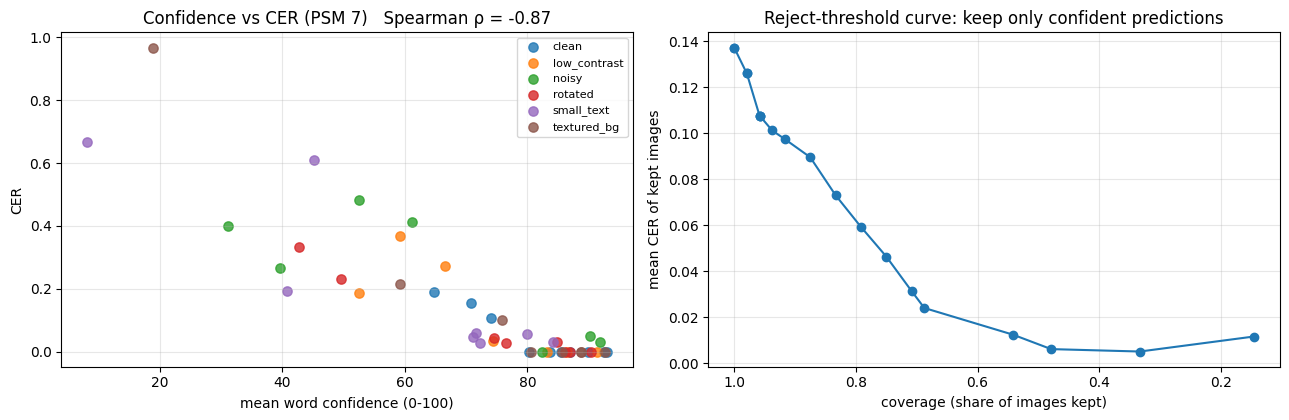

In [19]:
c = psm_df[(psm_df.psm == 7) & psm_df.conf.notna()].copy()
corr = c[["conf", "cer"]].corr(method="spearman").iloc[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for cond, g in c.groupby("condition"):
    axes[0].scatter(g.conf, g.cer, label=cond, s=45, alpha=.8)
axes[0].set_xlabel("mean word confidence (0-100)"); axes[0].set_ylabel("CER"); axes[0].legend(fontsize=8)
axes[0].set_title(f"Confidence vs CER (PSM 7)   Spearman ρ = {corr:.2f}"); axes[0].grid(alpha=.3)

ts = np.arange(0, 100, 5); cov, err = [], []
for t in ts:
    keep = c[c.conf >= t]
    cov.append(len(keep) / len(c)); err.append(keep.cer.mean() if len(keep) else np.nan)
axes[1].plot(cov, err, "o-"); axes[1].set_xlabel("coverage (share of images kept)"); axes[1].set_ylabel("mean CER of kept images")
axes[1].set_title("Reject-threshold curve: keep only confident predictions"); axes[1].invert_xaxis(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3. Evaluation — diagnose 10 failures
**Task:** run OCR on your 50-image dataset and, **for 10 failures, identify the cause** — one of four layers:

| Cause | Meaning | Typical signs | Fix |
|---|---|---|---|
| **Preprocessing** | the *image* was fixable but wasn't fixed | the same text/font on a clean background is read correctly; CER depends on the condition | better pipeline: contrast, denoise, deskew, upscaling |
| **Text detection** | the engine didn't find (all of) the text | empty output, crash, few words returned, boxes cover only part of the text | correct PSM, crop lines yourself (Day 28), pad the image |
| **Recognition** | the text was found but the *letters* were misread | boxes fine, characters wrong even on a clean image | better model (`tessdata_best`), different font handling, fine-tuning, a custom recogniser |
| **Normalisation** | the OCR output is *right* but differs in encoding | CER collapses to ≈ 0 once Arabic/Persian variants, digits, ZWNJ, spacing are unified | Day 27 normaliser |

### How we make the diagnosis rigorous: controlled experiments
Guessing from a glance is unreliable. Because our images are synthetic we can run *counterfactuals*:
1. **Re-render the same text, font and size on a clean background** and OCR it. If it succeeds but the stressed image fails, the cause lies in the *image condition* (preprocessing). If the clean version fails too, it's *recognition* (a font/model limit).
2. **Compare raw CER with normalised CER.** If normalising fixes most of the error → *normalisation*.
3. **Compare detected boxes with ground-truth boxes** (`det_recall`). Low recall, empty output or a crash → *text detection*.

The decision rule below uses **three pieces of evidence** and is applied in this order (encoding issues are the cheapest to rule out; "found no text" hides everything else):

| Evidence | How it is computed |
|---|---|
| **A. Normalisation gap** | `CER_raw − CER_normalised` — is the *text right but encoded differently*? |
| **B. Detection recall** | share of the ground-truth text area covered by Tesseract's boxes (empty output / crash ⇒ 0) |
| **C. Oracle** | the *best* CER this image achieves across **all** our pipelines **at the same PSM** — "could a different preprocessing have read it?" |
| **D. Clean counterpart** | same text, font **and size** on a perfect white page — "is the text itself readable by the model at all?" |

```
if CER_raw - CER_norm > 0.10 and CER_norm < 0.10      ->  normalization
elif crashed / empty / detection recall < 0.5:
        oracle < 0.10  ->  preprocessing   (another pipeline finds and reads the text)
        else           ->  text detection  (nothing we tried even finds it)
elif oracle < 0.10                                    ->  preprocessing   (another pipeline reads it)
elif clean counterpart < 0.15                         ->  preprocessing   (fine on a clean page: the condition is the problem, our set can't fix it)
else                                                  ->  recognition     (even clean, the model can't read this font/size)
```
The rule is a **hypothesis generator, not a verdict**: after it runs you must *look at the images* and overwrite its verdict where you disagree.

In [20]:
def render_clean_counterpart(row):
    """Same text, same font, same SIZE, same word gap — but a perfect white page (no noise, blur, rotation, texture)."""
    mask, _, _ = render_text_mask([row.text], FONTS.get(row.font) or ALL_FONTS[row.font], int(row["size"]), word_gap=row.word_gap)
    return 255 - mask

_ORACLE_CACHE = {}
def oracle_cer(row, folder, psm):
    """Best CER ANY of our pipelines achieves on this image at the SAME PSM (cached). 'Could different preprocessing have read it?'"""
    key = (str(folder), row.filename, psm)
    if key not in _ORACLE_CACHE:
        raw = cv2.imread(str(folder / row.filename))
        scores = {n: quick_cer(row.text, tesseract_text(run_pipeline(raw, st)[0], psm=psm)) for n, st in PIPELINES.items()}
        best = min(scores, key=scores.get)
        _ORACLE_CACHE[key] = (scores[best], best)
    return _ORACLE_CACHE[key]

def diagnose_row(row, folder, pipeline_steps, psm=7, pred_override=None):
    """Collect the four pieces of evidence (A normalisation gap, B detection recall, C oracle, D clean counterpart) and apply the rule."""
    raw = cv2.imread(str(folder / row.filename))
    proc, M = run_pipeline(raw, pipeline_steps)
    o = run_tesseract(proc, psm=psm)
    pred = o["text"] if pred_override is None else pred_override
    gt_boxes = transform_boxes(json.loads(row.word_boxes), M)
    det_rec = detection_recall(gt_boxes, o["words"], proc.shape)
    cer_raw, cer_norm = quick_cer(row.text, pred, normalize=False), quick_cer(row.text, pred, normalize=True)
    cer_clean = quick_cer(row.text, tesseract_text(run_pipeline(render_clean_counterpart(row), PIPELINES["P0_gray"])[0], psm=psm))
    oracle, oracle_pipe = oracle_cer(row, folder, psm)

    no_text = o["crashed"] or o["text"] == "" or det_rec < 0.5
    if (cer_raw - cer_norm) > 0.10 and cer_norm < 0.10:   cause = "normalization"
    elif no_text and oracle < 0.10:                       cause = "preprocessing"
    elif no_text:                                         cause = "text detection"
    elif oracle < 0.10:                                   cause = "preprocessing"
    elif cer_clean < 0.15:                                cause = "preprocessing"
    else:                                                 cause = "recognition"
    return dict(filename=row.filename, condition=row.get("condition", "-"), font=row.font, size=row["size"], ref=row.text, pred=pred,
                cer_raw=round(cer_raw, 3), cer_norm=round(cer_norm, 3), cer_clean_counterpart=round(cer_clean, 3),
                oracle_cer=round(oracle, 3), oracle_pipeline=oracle_pipe, det_recall=round(det_rec, 2), crashed=o["crashed"],
                conf=round(o["mean_conf"], 1) if not np.isnan(o["mean_conf"]) else None, auto_cause=cause)

### First, validate the diagnostic on failures with a *known* cause
A decision rule you have not tested is just a guess with formulas on it. Because we control the generator we can **manufacture a failure of each kind** and check that the rule names it correctly:

| Injected cause | How we cause it |
|---|---|
| **preprocessing** | a heavily noisy image read with *no* preprocessing (grayscale only) |
| **text detection** | a perfectly clean image **cropped so 60 % of the text lies outside the frame** — what a bad upstream crop or detector does (we first tried `--psm 10`; Tesseract's LSTM largely ignores it on a one-line image — a reminder that *you must test your assumptions about the engine*) |
| **recognition** | a clean image in a decorative Nastaliq font the model was never trained for (or, if you have none installed, text at an unreadably small size) |
| **normalization** | a perfectly correct reading whose letters/digits are re-encoded the way an engine often emits them (Arabic `ي`/`ك`, Arabic-Indic digits) |

In [21]:
CAL_DIR = ROOT / "calibration"; CAL_DIR.mkdir(exist_ok=True)

def make_calibration_row(text, font_name, size, name, keep_fraction=1.0, **render_kw):
    params = dict(font=font_name, size=size, word_gap=0.3, background="white", ink=10, noise_sigma=0.0,
                  salt_pepper=0.0, blur=0.0, rotation=0.0); params.update(render_kw)
    path = FONTS.get(font_name) or ALL_FONTS[font_name]
    img, wboxes, lbox = render_single_image(text, params, path, seed=7)
    if keep_fraction < 1.0:                                     # keep only the LEFT part: the beginning of a Persian line is on the right!
        img = img[:, : int(img.shape[1] * keep_fraction)]
    cv2.imwrite(str(CAL_DIR / f"{name}.png"), img)
    return pd.Series(dict(filename=f"{name}.png", text=text, condition="calibration", font=font_name, size=size,
                          word_gap=0.3, word_boxes=json.dumps(wboxes)))

def to_arabic_encoding(s):
    """Re-encode a correct Persian string the way OCR engines often emit it (Arabic yeh/kaf, Arabic-Indic digits)."""
    return s.replace("ی", "ي").replace("ک", "ك").translate(str.maketrans("۰۱۲۳۴۵۶۷۸۹", "٠١٢٣٤٥٦٧٨٩"))

txt = "شماره تلفن کتاب ۱۴۰۳ می‌کنند"
f_ok = list(FONTS)[0]
hard = list(HARD_FONTS)[0] if HARD_FONTS else None
cases = []

# 1) preprocessing: heavy noise, grayscale only
noisy_row = make_calibration_row(txt, f_ok, 44, "cal_noise", noise_sigma=40, salt_pepper=0.05)
cases.append(("preprocessing", noisy_row, PIPELINES["P0_gray"], 7, None))
# 2) text detection: most of the text is outside the crop
clean_row = make_calibration_row(txt, f_ok, 44, "cal_clean")
cut_row = make_calibration_row(txt, f_ok, 44, "cal_cut", keep_fraction=0.4)
cases.append(("text detection", cut_row, PIPELINES["P0_gray"], 7, None))
# 3) recognition: decorative font (or tiny text)
hard_row = make_calibration_row(txt, hard, 44, "cal_hard") if hard else make_calibration_row(txt, f_ok, 11, "cal_tiny")
cases.append(("recognition", hard_row, PIPELINES["P0_gray"], 7, None))
# 4) normalization: a correct reading, re-encoded
cases.append(("normalization", clean_row, PIPELINES["P0_gray"], 7, to_arabic_encoding(txt)))   # engine "read it right" but emitted Arabic code points

rows = []
for expected, row, steps, psm, override in cases:
    d = diagnose_row(row, CAL_DIR, steps, psm=psm, pred_override=override)
    d["expected_cause"], d["psm"] = expected, psm
    rows.append(d)
cal = pd.DataFrame(rows)
cal["rule_correct"] = cal.expected_cause == cal.auto_cause
display(cal[["expected_cause", "auto_cause", "rule_correct", "psm", "cer_raw", "cer_norm", "cer_clean_counterpart", "oracle_cer", "det_recall", "pred"]])
print("Rule agrees with the injected cause in", int(cal.rule_correct.sum()), "of", len(cal), "calibration cases.")

,expected_cause,auto_cause,rule_correct,psm,cer_raw,cer_norm,cer_clean_counterpart,oracle_cer,det_recall,pred
0,preprocessing,preprocessing,True,7,0.714,0.741,0.148,0.148,0.99,۱ خر ی ب س ۱ ی ک
1,text detection,text detection,True,7,0.714,0.741,0.148,0.704,0.36,۴ می کنند
2,recognition,preprocessing,False,7,0.000,0.000,0.000,0.000,0.97,شماره تلفن کتاب ۱۴۰۳ می‌کنند
3,normalization,normalization,True,7,0.250,0.000,0.148,0.148,0.95,شماره تلفن كتاب ١٤٠٣ مي‌كنند


Rule agrees with the injected cause in 3 of 4 calibration cases.


**How to use this.** If the rule gets a calibration case wrong, *fix the rule* (adjust thresholds or evidence) before trusting it on the real failures; if it passes, you at least know it can distinguish the four layers when the signal is clean. Real failures are messier — several causes can overlap in one image — which is why the final verdict is yours.

### Now diagnose the real 50-image results

In [22]:
# 1) OCR everything with the best overall pipeline
all_diag = pd.DataFrame([diagnose_row(r, DATA_DIR, PIPELINES[BEST_OVERALL]) for _, r in df50.iterrows()])
all_diag.to_csv(ROOT / "reports" / "day26_ocr_results.csv", index=False, encoding="utf-8")
print(f"Pipeline {BEST_OVERALL} | PSM 7 | mean CER (normalised) = {all_diag.cer_norm.mean():.3f} | "
      f"mean CER (raw) = {all_diag.cer_raw.mean():.3f}   <- the gap between these two is the cost of NOT normalising")
print("Images with normalised CER > 0.15:", int((all_diag.cer_norm > 0.15).sum()), "of", len(all_diag))

Pipeline P4_median_deskew_otsu | PSM 7 | mean CER (normalised) = 0.172 | mean CER (raw) = 0.178   <- the gap between these two is the cost of NOT normalising
Images with normalised CER > 0.15: 18 of 50


,filename,condition,font,size,cer_raw,cer_norm,cer_clean_counterpart,oracle_cer,oracle_pipeline,det_recall,crashed,auto_cause,your_verdict
0,img_019.png,noisy,Mikhak,57,1.000,1.000,1.000,1.000,P0_gray,0.00,False,text detection,
1,img_026.png,low_contrast,Mikhak,56,1.000,1.000,0.000,0.000,P2_clahe_otsu,0.00,False,preprocessing,
2,img_045.png,textured_bg,Digi Ravi,41,0.969,0.968,0.194,0.387,P1_otsu,1.00,False,recognition,
3,img_008.png,small_text,Digi Anil Bold,21,0.667,0.667,0.533,0.533,P0_gray,0.83,False,recognition,
4,img_034.png,small_text,Digi Gran Payeh,20,0.625,0.609,0.522,0.609,P0_gray,0.88,False,recognition,
5,img_037.png,noisy,Digi Gran Payeh,37,0.500,0.481,0.407,0.370,P3_median_otsu,0.91,False,recognition,
6,img_038.png,noisy,A nic,34,0.414,0.414,0.379,0.414,P3_median_otsu,0.89,False,recognition,
7,img_013.png,noisy,Digi Derakhshandeh,56,0.400,0.400,0.375,0.200,P3_median_otsu,0.80,False,recognition,
8,img_033.png,low_contrast,A nic,56,0.368,0.368,0.211,0.105,P5_upscale_gray,0.98,False,recognition,
9,img_028.png,rotated,Digi Gran Payeh,57,0.364,0.333,0.238,0.333,P4_median_deskew_otsu,0.58,False,recognition,


Cause counts among the 10 worst: {'text detection': 1, 'preprocessing': 1, 'recognition': 8}


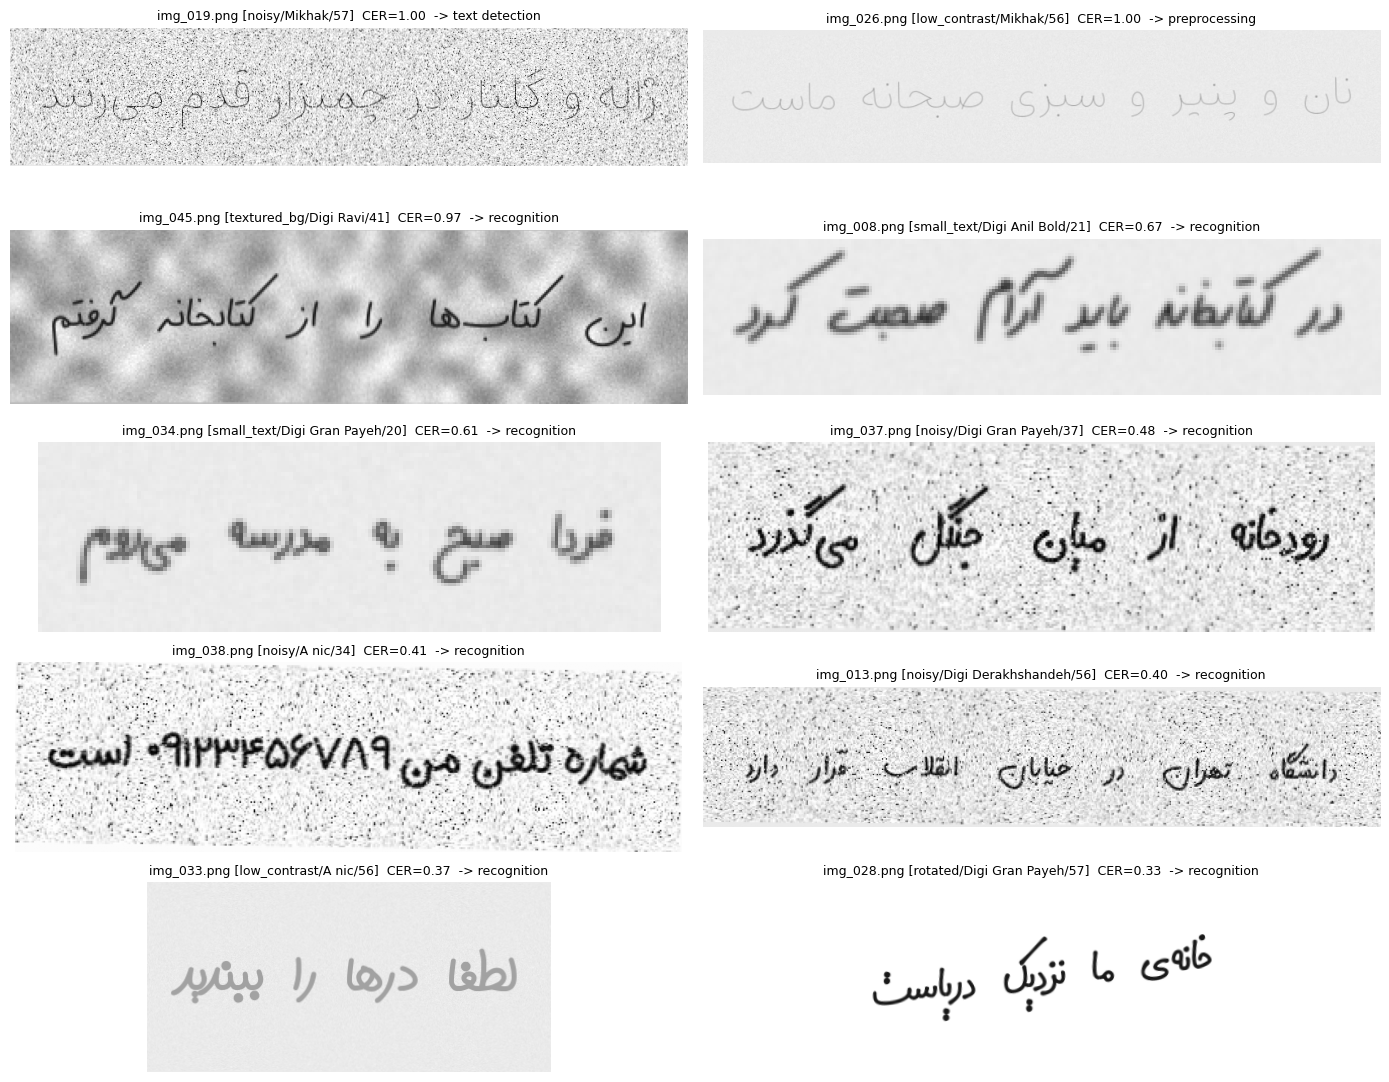

img_019.png (text detection)
    GT  : ژاله و گلنار در چمنزار قدم می‌زنند
    PRED: ''

img_026.png (preprocessing)
    GT  : نان و پنیر و سبزی صبحانه ماست
    PRED: ''

img_045.png (recognition)
    GT  : این کتاب‌ها را از کتابخانه گرفتم
    PRED: 'مر'

img_008.png (recognition)
    GT  : در کتابخانه باید آرام صحبت کرد
    PRED: 'هگقدنه ج 1۶ صحعت کنو'

img_034.png (recognition)
    GT  : فردا صبح به مدرسه می‌روم
    PRED: 'نیا میج ٩\u200f میت میم'

img_037.png (recognition)
    GT  : رودخانه از میان جنگل می‌گذرد
    PRED: 'رورفله_ از مان یل مد'

img_038.png (recognition)
    GT  : شماره تلفن من ۰۹۱۲۳۴۵۶۷۸۹ است
    PRED: 'شهارد تلف من ۷۹ است'

img_013.png (recognition)
    GT  : دانشگاه تهران در خیابان انقلاب قرار دارد
    PRED: 'راشگاه . تهران در غبیان \u200f اقلاب \u200f عرار . دارر'

img_033.png (recognition)
    GT  : لطفا درها را ببندید
    PRED: 'نطغا درها ,ا بینبپر'

img_028.png (recognition)
    GT  : خانه‌ی ما نزدیک دریاست
    PRED: 'خی ما نزیل دیاس'



In [23]:
# 2) The 10 worst failures (ranked by RAW CER, so pure-encoding failures can surface too) and their automatic diagnosis
failures = all_diag.sort_values(["cer_raw", "cer_norm"], ascending=False).head(10).reset_index(drop=True)
failures["your_verdict"] = ""            # <- EDIT: write preprocessing / text detection / recognition / normalization after LOOKING at the image
display(failures[["filename", "condition", "font", "size", "cer_raw", "cer_norm", "cer_clean_counterpart", "oracle_cer",
                  "oracle_pipeline", "det_recall", "crashed", "auto_cause", "your_verdict"]])
print("Cause counts among the 10 worst:", dict(Counter(failures.auto_cause)))

fig, axes = plt.subplots(5, 2, figsize=(14, 11))
for ax, (_, f) in zip(axes.flatten(), failures.iterrows()):
    ax.imshow(cv2.imread(str(DATA_DIR / f.filename), cv2.IMREAD_GRAYSCALE), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{f.filename} [{f.condition}/{f.font}/{f['size']}]  CER={f.cer_norm:.2f}  -> {f.auto_cause}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

# Side-by-side text so you can compare the strings yourself
for _, f in failures.iterrows():
    print(f"{f.filename} ({f.auto_cause})\n    GT  : {f.ref}\n    PRED: {f.pred!r}\n")

### What the real failures looked like in our run
After the best pipeline had done its work, the **10 worst failures were dominated by two conditions — small text and rotation** — and the automatic rule labelled all of them *preprocessing*: the text was found, a clean version of the same text/font/size was read correctly, and at least one other pipeline read the very same image well. In other words **no single pipeline is best for every image**, and the remaining errors are *selection* errors that a per-image router could remove. Recognition, text-detection and normalisation failures did not appear in the synthetic set — which is exactly why we validated the rule with the injected failures above, and why Day 31's *real* Kaggle images matter: real data is where those other three causes show up.

### Write-up template (fill this in after looking at the images)
For each of your 10 failures, record: **(1)** the image, **(2)** what you *see* is different from the ground truth, **(3)** which layer broke — and **why you believe that** (what experiment or observation supports it), **(4)** the concrete fix you would try.

Then answer the meta-questions:
* Which cause dominates? If *preprocessing* dominates, a smarter router (Day 25 stretch) is worth building. If *recognition* dominates, you need a better model — no amount of image cleaning will fix a model that has never seen Nastaliq-like shapes.
* Did the automatic rule and your own judgement disagree anywhere? Those disagreements show where the rule's assumptions (e.g. "clean counterpart works ⇒ image problem") break.
* **Beware the invisible failures.** Several "failures" may be only encoding differences. Day 27 removes them so you can see the *real* error rate.

### Checkpoint — Day 26
* [ ] You can explain PSM 3 vs 6 vs 7 vs 13 and chose one deliberately.
* [ ] You know what `image_to_data` returns, and that confidence `-1` marks non-word rows.
* [ ] You measured how well confidence predicts error instead of trusting it.
* [ ] 10 failures diagnosed by *experiment*, with your own `your_verdict` written down.
* [ ] *Stretch:* install `tessdata_best` `fas.traineddata`, point `TESSDATA_PREFIX` at it, rerun, and compare CER and runtime.
* [ ] *Beyond Tesseract:* the **Extension at the end of this notebook** compares Tesseract with **EasyOCR** and **PaddleOCR** using everything you built here (normaliser, CER, pipeline).

---
# Day 27 — Persian Normalization
**Topics:** Arabic/Persian character normalisation (`ي → ی`, `ك → ک`), whitespace, Persian/English digits, zero-width non-joiner (ZWNJ)

## 1. Why normalisation is half of Persian OCR
Two strings can *look identical on screen* and still be different strings:

```python
"علي" == "علی"      # False!  the last letter is U+064A (Arabic yeh) vs U+06CC (Persian yeh)
"كتاب" == "کتاب"    # False!  U+0643 (Arabic kaf) vs U+06A9 (Persian keheh)
"123" == "۱۲۳"      # False!  ASCII digits vs Persian digits (and "١٢٣" is a third string)
```
For OCR this matters twice:
1. **The engine** may emit either form — its training data mixed Arabic- and Persian-keyboard text.
2. **Your evaluation** counts every code-point difference as an error, so a *correct reading in the wrong encoding* inflates CER (you measured the cost on Day 26: `cer_raw` vs `cer_norm`). Likewise, **downstream systems** (search, databases, matching a licence plate against a record) silently fail to match.

## 2. The catalogue of Persian text problems
| Problem | Examples (code points) | Normal form |
|---|---|---|
| **Arabic yeh / alef maksura** | `ي` U+064A, `ى` U+0649 | `ی` U+06CC |
| **Arabic kaf** | `ك` U+0643 | `ک` U+06A9 |
| **Digits (3 families)** | ASCII `0-9`, Arabic-Indic `٠-٩` (U+0660–0669), Persian `۰-۹` (U+06F0–06F9); full-width `１２３` | Persian *or* ASCII — **pick one policy** |
| **Decimal / thousands separators** | `٫` U+066B, `٬` U+066C | `.` and `,` |
| **Presentation forms** | `ﻻ` U+FEFB, `ﺍ` U+FE8D (glyph-shaped code points from old encodings/PDF extraction) | base letters, via Unicode **NFKC** |
| **Diacritics (harakat)** | fatha, tanwin (`لطفاً`), shadda, sukun, superscript alef | usually removed for OCR/search |
| **Tatweel / kashida** | `ســلام` (U+0640 stretches a word) | removed |
| **Invisible bidi controls** | LRM U+200E, RLM U+200F, LRE/RLE/PDF U+202A–202C, isolates U+2066–2069, ALM U+061C | removed (they affect display, not content) |
| **Whitespace variants** | NBSP U+00A0, thin/narrow spaces U+2009/U+202F, tabs, runs of spaces | single ASCII space |
| **Punctuation** | `,` `;` `?` vs Persian `،` `؛` `؟`; stray spaces before punctuation | Persian punctuation after Persian letters; no space before |
| **ZWNJ (half-space)** | `می‌خواهم` vs `می خواهم` vs `میخواهم`; doubled / dangling ZWNJ | **policy** (see below) |
| **Hamza/alef/heh variants** (optional) | `أ إ ٱ` → `ا`; `ة` → `ه` | only if your application wants them merged |

## 3. The ZWNJ problem in detail
The ZWNJ (U+200C, نیم‌فاصله) separates two letters **without a visible space and without joining them**. Correct Persian spelling uses it in:
* verb prefixes: `می‌روم`, `نمی‌دانم`;
* plural / comparative / possessive suffixes: `کتاب‌ها`, `بزرگ‌تر`, `خانه‌ام`.

The practical mess: people (and OCR engines!) write the same word three ways — `می‌خواهم`, `می خواهم` (space) and `میخواهم` (joined). A ZWNJ is **invisible**, so an OCR engine that sees only pixels cannot know whether a gap was a half-space or a nothing. Hence two separate tasks:

| Task | Goal | What we do |
|---|---|---|
| **Cleaning** | remove *meaningless* ZWNJ: doubled, at word edges, after a letter that **cannot join anyway** (`ا د ذ ر ز ژ و`), or next to a non-letter | rule-based, safe |
| **Policy for meaningful ZWNJ** | `keep` / `remove` / `space`, and optionally **re-insert** missing ZWNJ in known affix patterns (`می خواهم → می‌خواهم`) | choose per application; re-insertion is *heuristic* |

**Policy for evaluation.** To compare OCR output with ground truth fairly, use a *canonical* form in which `می‌کنند`, `می کنند` are treated alike (`zwnj="space"`). But also report a **strict** score that keeps ZWNJ, because for products that display text, a missing half-space is a real (if small) error.

> **A design principle.** A normaliser must be **idempotent** (`norm(norm(x)) == norm(x)`) and **conservative**: when unsure, don't change the text. Over-eager rules (e.g. "always join `ها`") corrupt valid text, and you cannot undo them.

In [24]:
class PersianNormalizer:
    """
    Rule-based Persian text normaliser (idempotent, conservative).

    unify_letters    : ي ى -> ی ,  ك -> ک
    unify_alef       : أ إ ٱ -> ا             (off by default: changes spelling of some loanwords)
    unify_heh        : ة -> ه, ۀ -> ه         (off by default)
    digits           : "persian" | "english" | None
    zwnj             : "normalize" (clean redundant ones, keep meaningful) | "keep" | "remove" | "space"
    fix_affixes      : re-insert ZWNJ in می/نمی prefixes and ها/های/تر/ترین suffixes ("می خواهم" -> "می‌خواهم")  [heuristic]
    remove_diacritics: harakat / tanwin / shadda / sukun / superscript alef
    remove_tatweel, remove_bidi_marks, nfkc, whitespace, punctuation : cleanup switches
    """
    NON_JOINERS = set("ادذرزژوآأإؤءۀة")                       # letters that never connect to the NEXT letter
    BIDI_CONTROLS = "\u200e\u200f\u061c\u202a\u202b\u202c\u202d\u202e\u2066\u2067\u2068\u2069\u200d\ufeff\u00ad\u200b"
    PERSIAN_DIGITS, ARABIC_DIGITS, ASCII_DIGITS = "۰۱۲۳۴۵۶۷۸۹", "٠١٢٣٤٥٦٧٨٩", "0123456789"

    def __init__(self, unify_letters=True, unify_alef=False, unify_heh=False, digits="persian", zwnj="normalize",
                 fix_affixes=False, remove_diacritics=True, remove_tatweel=True, remove_bidi_marks=True,
                 nfkc=True, whitespace=True, punctuation=True):
        assert digits in ("persian", "english", None) and zwnj in ("normalize", "keep", "remove", "space")
        self.__dict__.update({k: v for k, v in locals().items() if k != "self"})
        letters = {"ي": "ی", "ى": "ی", "ك": "ک"}
        if unify_alef: letters.update({"أ": "ا", "إ": "ا", "ٱ": "ا"})
        if unify_heh:  letters.update({"ة": "ه", "ۀ": "ه"})
        self._letters = str.maketrans(letters)
        target = {"persian": self.PERSIAN_DIGITS, "english": self.ASCII_DIGITS}.get(digits)
        self._digits = (str.maketrans({**dict(zip(self.ARABIC_DIGITS, target)), **dict(zip(self.PERSIAN_DIGITS, target)),
                                       **dict(zip(self.ASCII_DIGITS, target))}) if target else None)
        self._drop = str.maketrans("", "", self.BIDI_CONTROLS) if remove_bidi_marks else None

    @staticmethod
    def _is_letter(ch):
        return bool(ch) and "\u0600" <= ch <= "\u06ff" and unicodedata.category(ch).startswith("L")

    def _clean_zwnj(self, s):
        s = re.sub("\u200c+", ZWNJ, s)                                         # doubled -> single
        out = []
        for i, ch in enumerate(s):
            if ch != ZWNJ:
                out.append(ch); continue
            prev = s[i - 1] if i > 0 else ""
            nxt = s[i + 1] if i + 1 < len(s) else ""
            # meaningful only BETWEEN two Persian letters AND after a letter that can actually join forward
            if self._is_letter(prev) and prev not in self.NON_JOINERS and self._is_letter(nxt):
                out.append(ch)
        return "".join(out)

    def _fix_affixes(self, s):
        s = re.sub(r"(?<![\u0600-\u06ff])(ن?می) (?=[\u0600-\u06ff])", "\\1" + ZWNJ, s)                        # می خواهم, نمی رود
        s = re.sub(r"(?<=[\u0600-\u06ff]) (ها|های|هایی|تر|ترین)(?![\u0600-\u06ff])", ZWNJ + "\\1", s)        # کتاب ها, بزرگ تر
        return s

    def __call__(self, text):
        s = text if isinstance(text, str) else ""
        if self.nfkc: s = unicodedata.normalize("NFKC", s)
        if self._drop is not None: s = s.translate(self._drop)                                                 # (ZWNJ is NOT in this list: handled below)
        s = s.translate(self._letters)
        if self.remove_diacritics: s = re.sub("[\u064b-\u0652\u0670]", "", s)
        if self.remove_tatweel:    s = s.replace("\u0640", "")
        if self._digits is not None: s = s.translate(self._digits)
        s = s.replace("\u066b", ".").replace("\u066c", ",")                                                    # Arabic decimal / thousands separators
        if self.whitespace:
            s = s.replace("\r\n", "\n").replace("\r", "\n")
            s = "".join(" " if (c != "\n" and (c.isspace() or unicodedata.category(c) == "Zs")) else c for c in s)
        if self.punctuation:
            L = "[\u0621-\u064a\u066e-\u06d3]"                                                                  # Persian LETTERS only (not digits)
            s = re.sub(f"(?<={L}),", "،", s)
            s = re.sub(f"(?<={L});", "؛", s)
            s = re.sub(f"(?<={L})\\?", "؟", s)
            s = re.sub(r"[ ]+([،؛؟.!:])", r"\1", s)                                                            # no space BEFORE punctuation
        # ZWNJ policy ---------------------------------------------------------------
        if   self.zwnj == "remove": s = s.replace(ZWNJ, "")
        elif self.zwnj == "space":  s = s.replace(ZWNJ, " ")
        elif self.zwnj == "normalize":
            s = self._clean_zwnj(s)
            if self.fix_affixes: s = self._fix_affixes(s)
        if self.fix_affixes and self.zwnj == "keep": s = self._fix_affixes(s)
        if self.whitespace:
            s = re.sub(r"[ ]+", " ", s)
            s = "\n".join(line.strip() for line in s.split("\n"))
            s = re.sub(r"\n{2,}", "\n", s).strip()
        return s

# Two ready-made policies we will use from now on
normalize_display = PersianNormalizer(digits="persian", zwnj="normalize", fix_affixes=False)           # what you would SHOW or STORE
normalize_eval    = PersianNormalizer(digits="english", zwnj="space", unify_alef=True, unify_heh=True)  # what you COMPARE (canonical)

demo = "  كتاب‌هاي  ١٢٣   مي‌خواهم\u200f  ســلام "
print("input   :", repr(demo))
print("display :", repr(normalize_display(demo)))
print("eval    :", repr(normalize_eval(demo)))

input   : '  كتاب\u200cهاي  ١٢٣   مي\u200cخواهم\u200f  ســلام '
display : 'کتاب\u200cهای ۱۲۳ می\u200cخواهم سلام'
eval    : 'کتاب های 123 می خواهم سلام'


## 4. Evaluation — a normalisation test suite (≥ 30 cases)
A normaliser without tests is a liability: every new rule risks breaking an old one. Each case below is `(name, input, expected, options)`. Inputs are written with **explicit `\uXXXX` escapes wherever the characters are visually ambiguous or invisible** — otherwise reading the test file would be impossible (you cannot *see* the difference between U+06CC and U+064A in most fonts!).

The suite is organised by problem class: **letters, digits, whitespace, ZWNJ, invisible/bidi characters, diacritics & decorations, punctuation, Unicode compatibility forms, and negative tests** (inputs that must *not* change). Always include negative tests — they catch over-eager rules.

In [25]:
Z = "\u200c"
TESTS = [
 # ── letters ─────────────────────────────────────────────────────────────────────────────────────────
 ("arabic yeh -> persian yeh",        "\u0639\u0644\u064A",                    "علی",             {}),
 ("alef maksura -> persian yeh",      "\u0645\u0648\u0633\u0649",              "موسی",            {}),
 ("arabic kaf -> persian keheh",      "\u0643\u062A\u0627\u0628",              "کتاب",            {}),
 ("yeh + kaf in one word",            "\u0643\u064A\u0641",                    "کیف",             {}),
 ("already-correct letters unchanged","پیچ ژاله گل",                           "پیچ ژاله گل",     {}),
 ("alef variants merged (opt-in)",    "\u0623\u062D\u0645\u062F",              "احمد",            dict(unify_alef=True)),
 ("alef variants kept by default",    "\u0623\u062D\u0645\u062F",              "\u0623\u062D\u0645\u062F", {}),
 ("teh marbuta -> heh (opt-in)",      "\u0631\u062D\u0645\u0629",              "رحمه",            dict(unify_heh=True)),
 # ── digits ──────────────────────────────────────────────────────────────────────────────────────────
 ("arabic-indic -> persian digits",   "\u0661\u0662\u0663",                    "۱۲۳",             {}),
 ("ascii -> persian digits",          "2024",                                  "۲۰۲۴",            {}),
 ("persian -> english digits",        "۱۲۳",                                   "123",             dict(digits="english")),
 ("mixed digit families unified",     "1\u0662\u06F3",                         "۱۲۳",             {}),
 ("full-width digits (NFKC)",         "\uFF11\uFF12\uFF13",                    "۱۲۳",             {}),
 ("digits untouched when disabled",   "12 ۳٤",                                 "12 ۳٤",           dict(digits=None)),
 ("arabic decimal/thousands marks",   "\u0661\u066C\u0662\u0663\u0664\u066B\u0665", "۱,۲۳۴.۵",    {}),
 # ── whitespace ──────────────────────────────────────────────────────────────────────────────────────
 ("collapse runs of spaces",          "سلام     دنیا",                        "سلام دنیا",       {}),
 ("strip leading/trailing space",     "   سلام \n ",                           "سلام",            {}),
 ("NBSP -> space",                    "سلام\u00A0دنیا",                        "سلام دنیا",       {}),
 ("thin / narrow spaces -> space",    "سلام\u2009دنیا\u202Fخوب",               "سلام دنیا خوب",   {}),
 ("tab -> space",                     "سلام\tدنیا",                            "سلام دنیا",       {}),
 ("many blank lines -> one newline",  "الف\n\n\nب",                            "الف\nب",          {}),
 ("windows line endings",             "الف\r\nب",                              "الف\nب",          {}),
 # ── ZWNJ ────────────────────────────────────────────────────────────────────────────────────────────
 ("meaningful ZWNJ kept",             f"می{Z}خواهم",                           f"می{Z}خواهم",     {}),
 ("doubled ZWNJ collapsed",           f"می{Z}{Z}خواهم",                        f"می{Z}خواهم",     {}),
 ("ZWNJ at end removed",              f"کتاب{Z}",                              "کتاب",            {}),
 ("ZWNJ next to space removed",       f"کتاب {Z}ها",                           "کتاب ها",         {}),
 ("ZWNJ after non-joiner removed",    f"دار{Z}ند",                             "دارند",           {}),
 ("ZWNJ before digit/latin removed",  f"سال{Z}2024",                           "سال۲۰۲۴",         {}),
 ("zwnj='remove' policy",             f"می{Z}خواهم",                           "میخواهم",         dict(zwnj="remove")),
 ("zwnj='space' policy",              f"می{Z}خواهم",                           "می خواهم",        dict(zwnj="space")),
 ("fix prefix می + space",            "می خواهم",                              f"می{Z}خواهم",     dict(fix_affixes=True)),
 ("fix prefix نمی + space",           "نمی رود",                               f"نمی{Z}رود",      dict(fix_affixes=True)),
 ("fix plural ها + space",            "کتاب ها",                               f"کتاب{Z}ها",      dict(fix_affixes=True)),
 ("fix comparative تر + space",       "بزرگ تر",                               f"بزرگ{Z}تر",      dict(fix_affixes=True)),
 ("affix fix: joined word untouched", "کتابها",                                "کتابها",          dict(fix_affixes=True)),
 ("affix fix off by default",         "می خواهم",                              "می خواهم",        {}),
 # ── invisible / bidi controls, decorations ─────────────────────────────────────────────────────────
 ("LRM/RLM marks removed",            "\u200Fسلام\u200E",                      "سلام",            {}),
 ("RLE/PDF embedding removed",        "\u202Bسلام\u202C",                      "سلام",            {}),
 ("tatweel (kashida) removed",        "ســلام",                                "سلام",            {}),
 ("harakat removed",                  "سَلام",                                 "سلام",            {}),
 ("tanwin removed",                   "لطفاً",                                 "لطفا",            {}),
 ("diacritics kept when disabled",    "سَلام",                                 "سَلام",           dict(remove_diacritics=False)),
 # ── Unicode compatibility / presentation forms ─────────────────────────────────────────────────────
 ("presentation form lam-alef",       "\uFEFB",                                "لا",              {}),
 ("presentation form isolated alef",  "\uFE8D\uFEE3",                          "ام",              {}),
 # ── punctuation ─────────────────────────────────────────────────────────────────────────────────────
 ("latin comma after persian -> ،",   "سلام,دنیا",                             "سلام،دنیا",       {}),
 ("latin question mark -> ؟",         "چطوری?",                                "چطوری؟",          {}),
 ("space before punctuation removed", "سلام ، دنیا ؟",                         "سلام، دنیا؟",     {}),   # the space AFTER stays: that is Persian typography
 # ── negative tests: must NOT change ─────────────────────────────────────────────────────────────────
 ("latin text untouched",             "Hello, world?",                         "Hello, world?",   dict(digits=None)),
 ("mixed persian + latin order kept", "iPhone ماه",                            "iPhone ماه",      dict(digits=None)),
 ("empty string",                     "",                                      "",                {}),
 ("only invisible/whitespace",        f" {Z}\u200F\t\n",                       "",                {}),
]

def run_test_suite(tests):
    rows = []
    for name, inp, expected, opts in tests:
        got = PersianNormalizer(**opts)(inp)
        again = PersianNormalizer(**opts)(got)
        rows.append(dict(case=name, passed=(got == expected), idempotent=(again == got),
                         expected=expected, got=got, opts=opts or ""))
    return pd.DataFrame(rows)

suite = run_test_suite(TESTS)
print(f"{len(suite)} test cases | passed: {int(suite.passed.sum())} | idempotent: {int(suite.idempotent.sum())}")
bad = suite[~(suite.passed & suite.idempotent)]
if len(bad):
    display(bad)
else:
    print("All normalisation tests pass and every rule is idempotent.")
assert len(suite) >= 30, "The roadmap requires at least 30 test cases"

51 test cases | passed: 51 | idempotent: 51
All normalisation tests pass and every rule is idempotent.


### What the suite does *not* prove
* It proves the rules do what *we think* they should. It does **not** prove the rules are *linguistically right* for every text — for example, merging `ة → ه` is correct for names like `رحمة`→`رحمه` in Persian but wrong for Arabic quotations. That's why such merges are **opt-in options**.
* `fix_affixes` is a **heuristic**: `می خواهم` is right, but some words legitimately contain `می` followed by a space (e.g. `می` meaning *wine*, `هزار می`). In a real project, measure its precision on a hand-labelled sample before enabling it.

### Measuring the real effect on OCR output
The question that matters: **how much CER disappears when we normalise Tesseract's actual output?** We compare three policies on all 50 images: *none* (raw code points), the *proxy normaliser* from Day 25, and your new *canonical evaluation normaliser*. A large gap between "none" and the others quantifies how much of your "OCR error" was really an *encoding disagreement*.

In [26]:
def cer_with(ref, hyp, norm):
    r, h = (norm(ref), norm(hyp)) if norm else (ref, hyp)
    return _Lev.distance(r, h) / max(len(r), 1)

res27 = all_diag[["filename", "condition", "ref", "pred"]].copy()
res27["cer_none"]    = [cer_with(r, p, None) for r, p in zip(res27.ref, res27.pred)]
res27["cer_proxy"]   = [cer_with(r, p, proxy_norm) for r, p in zip(res27.ref, res27.pred)]
res27["cer_canon"]   = [cer_with(r, p, normalize_eval) for r, p in zip(res27.ref, res27.pred)]
res27["cer_display"] = [cer_with(r, p, normalize_display) for r, p in zip(res27.ref, res27.pred)]
display(res27[["cer_none", "cer_proxy", "cer_canon", "cer_display"]].mean().round(4).to_frame("mean CER"))

fixed = res27[(res27.cer_none - res27.cer_canon) > 0.02].sort_values("cer_none", ascending=False)
print(f"{len(fixed)} of {len(res27)} images had more than 2 CER points that were *encoding / ZWNJ-policy* differences rather than misread letters. Examples:")
for _, r in fixed.head(5).iterrows():
    print(f"  {r.filename}: {r.cer_none:.3f} -> {r.cer_canon:.3f}")
    print("     ref :", r.ref); print("     pred:", r.pred)

# Which characters does Tesseract actually emit that differ from our ground-truth alphabet?
emitted = Counter(ch for p in res27.pred for ch in p)
suspects = {ch: n for ch, n in emitted.items()
            if ch in "يىكةٱأإ" or "\u0660" <= ch <= "\u0669" or ch in "\u200e\u200f\u064b\u064c\u064d\u064e\u064f\u0650\u0651\u0652"}
print("\nSuspicious characters actually emitted by Tesseract:", {f"U+{ord(c):04X} {unicodedata.name(c)}": n for c, n in suspects.items()} or "none in this run")

,mean CER
cer_none,0.1776
cer_proxy,0.1717
cer_canon,0.1709
cer_display,0.1716


7 of 50 images had more than 2 CER points that were *encoding / ZWNJ-policy* differences rather than misread letters. Examples:
  img_013.png: 0.400 -> 0.275
     ref : دانشگاه تهران در خیابان انقلاب قرار دارد
     pred: راشگاه . تهران در غبیان ‏ اقلاب ‏ عرار . دارر
  img_042.png: 0.304 -> 0.261
     ref : من هر روز کتاب می‌خوانم
     pred: من هر رو لتاب ي‌طواغ
  img_010.png: 0.241 -> 0.207
     ref : پدرم هر شب اخبار تماشا می‌کند
     pred: یدرم هر شب امبار هاهشا م کند
  img_031.png: 0.222 -> 0.185
     ref : کودکان در پارک بازی می‌کنند
     pred: خودهان در پارف بای مي‌هنند
  img_040.png: 0.138 -> 0.103
     ref : ساعت هشت صبح جلسه شروع می‌شود
     pred: ساعت هشت صیح چلسه شروع ي‌شود

Suspicious characters actually emitted by Tesseract: {'U+200F RIGHT-TO-LEFT MARK': 3, 'U+064A ARABIC LETTER YEH': 5, 'U+0669 ARABIC-INDIC DIGIT NINE': 1}


### Checkpoint — Day 27
* [ ] You can name at least five ways two visually identical Persian strings can differ.
* [ ] `PersianNormalizer` is **idempotent** and has opt-in switches for the risky rules.
* [ ] The suite has ≥ 30 cases (letters, digits, whitespace, ZWNJ, bidi, diacritics, punctuation, compatibility forms, **negative tests**) and passes.
* [ ] You separate a **display/storage** policy from an **evaluation** policy and can justify both.
* [ ] *Stretch:* add ten more cases from real Tesseract output you find in `res27`, and any case where a rule *wrongly* changed valid text (a regression test).

---
# Day 28 — Text Region Detection
**Topics:** Contours, connected components, horizontal projection, vertical projection, line segmentation, word regions
**Goal:** extract text regions *before* OCR.

## 1. Why detect regions ourselves?
On Day 26 we fed Tesseract one-line crops. Real documents contain *many* lines (and columns, tables, stamps, photos). You have two options:
1. let Tesseract do layout analysis (PSM 3/6) — convenient, but a black box that sometimes merges lines or skips text;
2. **find the lines yourself, crop each one, and call the recogniser in line mode (PSM 7).** You control — and can *debug* — the stage in which you can see failures (boxes on an image) rather than guess at them (wrong strings).

This is the classic **OCR pipeline decomposition**: *detect → crop → recognise*. Today we build the detector from classical image-processing tools. (Deep detectors — EAST, DBNet, CRAFT — do the same job on photographs of scenes; classical methods shine on clean scans and documents.)

## 2. The toolbox
### 2.1 Ink mask
All of today's methods start from a binary mask where **ink = 255**: grayscale → light median filter → Otsu (*inverted*, so that dark ink becomes white foreground). Pitfall: if the image is dark-on-light the ink is the *minority* class; always sanity-check polarity (`ink.mean() < 0.5`).

### 2.2 Projection profiles (the workhorse for documents)
A **projection profile** sums the ink along one axis.
* **Horizontal projection** (sum each *row*): text lines are bands of high values separated by valleys of ≈ 0 (the line gaps). Cutting at the valleys = **line segmentation**.
* **Vertical projection** (sum each *column*, *inside a single line*): letters/words are bumps separated by zero-valleys (**gaps**). Cutting at gaps wider than a threshold = **word segmentation**.

Strengths: extremely fast, parameter-light, perfect for upright text. Weaknesses: needs **deskewed** text (skew smears the valleys), and struggles with multi-column layouts, tables and overlapping lines — which is why deskewing (Day 25) comes first.

**The Persian twist for word segmentation.** In Latin text, "a gap" means "a space". In Persian, **six letters (`ا د ذ ر ز ژ و`) do not join to the following letter**, so a *single word* also contains small gaps (`دانشگاه` has one after `د` and one after `ا`). The projection method therefore needs a gap threshold large enough to ignore *intra-word* gaps but small enough to detect *real spaces*. There is no universally right value; it scales with font size, so we express it as a **fraction of the line's ink height** and *tune it on data* (below).

### 2.3 Connected components (CC)
A **connected component** is a maximal set of touching ink pixels. `cv2.connectedComponentsWithStats` returns, for each component, its bounding box and **area**. In Persian that means:
* a **joined run of letters** is *one* component;
* **dots and small marks** (ب ت ث ج چ خ ش ق ف ن …) are *separate small components* above/below the baseline;
* **noise specks** are *tiny isolated components*.

So a CC analysis lets you (a) **remove specks** (small area *and* not near any large component) while **keeping dots** (small but sitting next to a letter body), and (b) measure typical letter/line height from component statistics.

### 2.4 Contours
`cv2.findContours` traces the *outline* of each component. For region detection the standard trick is **morphological dilation → contours**: dilate the ink horizontally with a wide, short kernel so that nearby letters/dots *merge into a blob per word (or per line)*, then take each contour's bounding rectangle. The kernel width plays exactly the role of the gap threshold above. Contours are also the entry point for rotated-rectangle fitting (`cv2.minAreaRect`) when text isn't axis-aligned.

### 2.5 Reading order
RTL language ⇒ **lines top→bottom, words right→left**. Detected boxes come out in arbitrary order; you must *sort* them: lines by `y`, words by *descending* `x`.

## 3. Practice — multi-line Persian images
We reuse the Day 24 renderer, but now with 3–6 lines per image, different fonts/sizes/line spacing, slight skew, and noise on some of them. The generator records the **ground-truth boxes of every line and word** so we can *score* the detectors instead of just looking at them.

12 multi-line images, 52 lines, 305 words.


,filename,n_lines,font,size,background,noisy,rotation
0,multi_00.png,3,Tanha FD\-WOL,30,paper,False,2.35
1,multi_01.png,6,Sarbaz,34,gradient,False,1.78
2,multi_02.png,5,Estedad\-VF,40,gradient,True,-1.84
3,multi_03.png,4,Tanha FD\-WOL,37,gradient,False,1.17
4,multi_04.png,4,Tanha FD,43,white,False,-0.87
5,multi_05.png,4,Noto Naskh Arabic,40,paper,True,0.12
6,multi_06.png,5,Estedad,38,paper,False,1.17
7,multi_07.png,5,IRXLotus,42,paper,False,-1.22
8,multi_08.png,4,Noto Sans Arabic,32,white,True,-0.76
9,multi_09.png,3,Shabnam FD,31,paper,False,-1.21


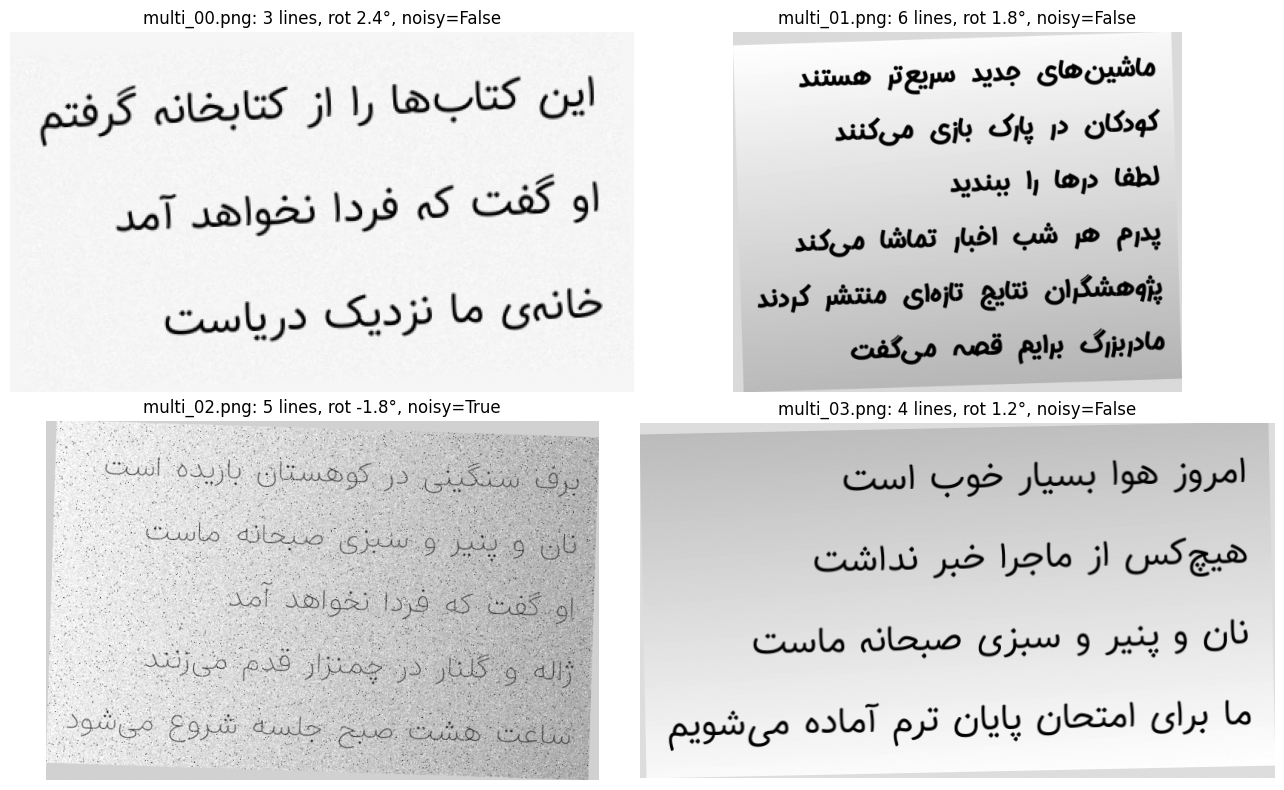

In [27]:
def build_multiline_set(n=12, seed=11, out_dir=MULTI_DIR):
    rng = np.random.default_rng(seed)
    rows = []
    for i in range(n):
        n_lines = int(rng.integers(3, 7))
        lines = [CORPUS[j] for j in rng.choice(len(CORPUS), n_lines, replace=False)]
        font = str(rng.choice(list(FONTS))); size = int(rng.integers(30, 44))
        word_gap, line_gap = float(rng.uniform(0.3, 0.6)), float(rng.uniform(0.35, 0.8))
        mask, lboxes, wboxes = render_text_mask(lines, FONTS[font], size, word_gap=word_gap, line_gap=line_gap)
        bg_kind = str(rng.choice(["white", "paper", "gradient"]))
        img = compose(mask, make_background(bg_kind, *mask.shape, rng), ink=int(rng.integers(0, 50)))
        noisy = bool(i % 3 == 2)                                        # every third image is noisy
        if noisy: img = add_noise(img, 20, 0.02, rng)
        angle = float(rng.uniform(-2.5, 2.5))
        flat = [b for line in wboxes for b in line] + lboxes             # rotate ALL boxes with the image
        img, flat = rotate_with_boxes(img, angle, flat)
        n_words = [len(l) for l in wboxes]
        words_rot, k = [], 0
        for nw in n_words: words_rot.append(flat[k:k + nw]); k += nw
        lines_rot = flat[k:]
        fname = f"multi_{i:02d}.png"
        cv2.imwrite(str(out_dir / fname), finish(img, 0.0))
        rows.append(dict(filename=fname, text="\n".join(lines), n_lines=n_lines, font=font, size=size, background=bg_kind,
                         noisy=noisy, rotation=angle, line_boxes=json.dumps(lines_rot), word_boxes=json.dumps(words_rot)))
    df = pd.DataFrame(rows); df.to_csv(out_dir / "labels.csv", index=False, encoding="utf-8")
    return df

dfm = build_multiline_set()
n_words_total = sum(len(line) for w in dfm.word_boxes for line in json.loads(w))
print(f"{len(dfm)} multi-line images, {dfm.n_lines.sum()} lines, {n_words_total} words.")
display(dfm[["filename", "n_lines", "font", "size", "background", "noisy", "rotation"]].round(2))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (_, r) in zip(axes.flatten(), dfm.head(4).iterrows()):
    ax.imshow(cv2.imread(str(MULTI_DIR / r.filename), 0), cmap="gray"); ax.set_title(f"{r.filename}: {r.n_lines} lines, rot {r.rotation:.1f}°, noisy={r.noisy}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Step 1 — line segmentation with the horizontal projection
Algorithm:
1. Deskew (Day 25) and make the ink mask.
2. Sum each row → profile; **smooth** it slightly so isolated rows of dots don't split a line.
3. Threshold at a small fraction of the maximum; consecutive rows above it form a **band**.
4. **Merge bands separated by tiny gaps** (a line's dots/ascenders can leave a thin empty stripe).
5. Drop bands that are too short (specks).
6. For each band, find the **x-extent** from the column sums inside it.

Look at the profile plot first: the valleys *are* the line gaps — the whole method is "find the valleys".

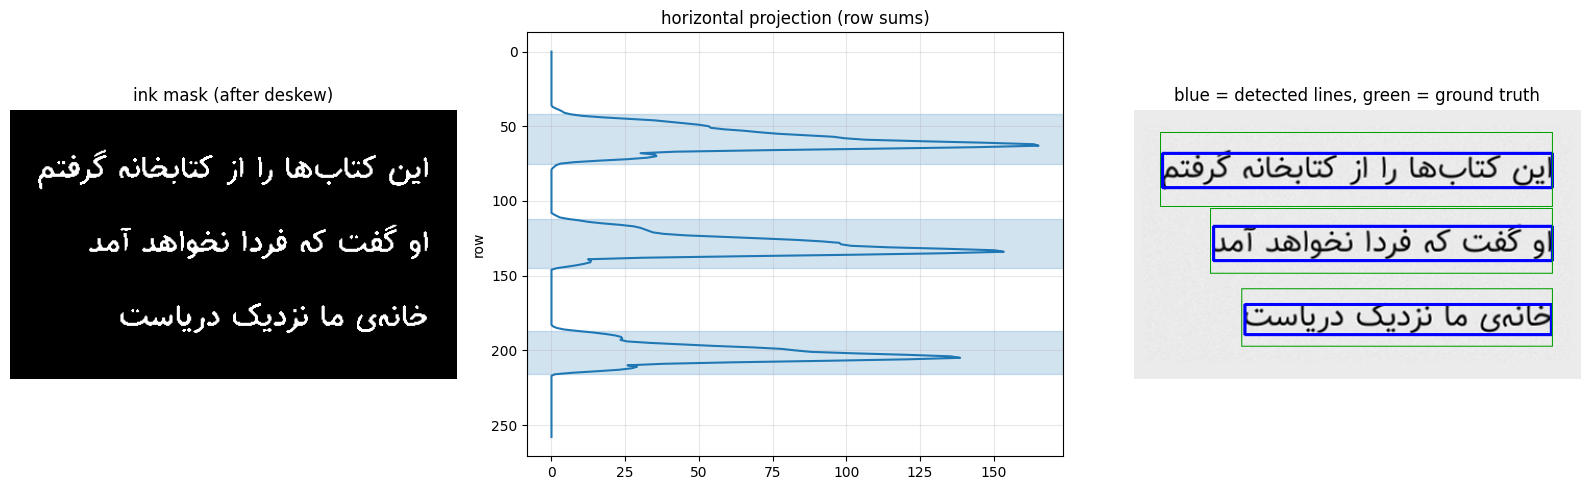

3 lines detected; ground truth has 3


In [28]:
def ink_mask(gray):
    """Ink = 255 on a black background (Otsu inverted, after a light median)."""
    g = cv2.medianBlur(gray, 3)
    _, ink = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return 255 - ink if (ink > 0).mean() > 0.5 else ink                   # ink must be the minority

def find_runs(boolean_1d):
    """[(start, end_exclusive), ...] for consecutive True values."""
    b = np.concatenate([[0], boolean_1d.astype(np.int8), [0]])
    d = np.diff(b)
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))

def merge_close_runs(runs, min_gap):
    out = []
    for s, e in runs:
        if out and s - out[-1][1] < min_gap: out[-1] = (out[-1][0], e)
        else: out.append((s, e))
    return out

def segment_lines(ink, rel_thresh=0.03, smooth=5, merge_gap_frac=0.35, min_height=8):
    prof = (ink > 0).sum(axis=1).astype(float)
    prof_s = np.convolve(prof, np.ones(smooth) / smooth, mode="same")
    runs = find_runs(prof_s > rel_thresh * prof_s.max())
    if not runs: return [], prof_s
    med_h = np.median([e - s for s, e in runs])
    runs = merge_close_runs(runs, merge_gap_frac * med_h)
    runs = [(s, e) for s, e in runs if e - s >= min_height]
    boxes = []
    for s, e in runs:
        cols = np.where((ink[s:e] > 0).any(axis=0))[0]
        if len(cols): boxes.append([int(cols.min()), int(s), int(cols.max()) + 1, int(e)])
    return boxes, prof_s

# Deskew first (Day 25), carry the ground truth along, then segment
def prepare(row, folder):
    raw = cv2.imread(str(folder / row.filename))
    gray, M = run_pipeline(raw, [photometric(to_gray), s_deskew(10)])
    return raw, gray, M

row = dfm.iloc[0]
raw, gray, M = prepare(row, MULTI_DIR)
ink = ink_mask(gray)
line_boxes, prof = segment_lines(ink)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.2, 1]})
axes[0].imshow(ink, cmap="gray"); axes[0].set_title("ink mask (after deskew)"); axes[0].axis("off")
axes[1].plot(prof, np.arange(len(prof))); axes[1].invert_yaxis(); axes[1].set_title("horizontal projection (row sums)")
for x1, y1, x2, y2 in line_boxes: axes[1].axhspan(y1, y2, color="tab:blue", alpha=0.2)
axes[1].set_ylabel("row"); axes[1].grid(alpha=.3)
vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
for x1, y1, x2, y2 in line_boxes: cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 2)
for b in transform_boxes(json.loads(row.line_boxes), M): cv2.rectangle(vis, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (0, 160, 0), 1)
axes[2].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); axes[2].set_title("blue = detected lines, green = ground truth"); axes[2].axis("off")
plt.tight_layout(); plt.show()
print(f"{len(line_boxes)} lines detected; ground truth has {row.n_lines}")

## 5. Step 2 — word segmentation: three methods, one fair test
Inside each line band we compare **three** ways to find words:

| Method | Idea | Sensitive to |
|---|---|---|
| **A. Vertical projection** | split at runs of empty columns wider than `gap` | `gap` (must exceed intra-word gaps from non-joiner letters) |
| **B. Dilation + contours** | dilate horizontally by `gap`, take contour boxes, tighten to the ink | `gap` again, but also merges dots across thin gaps |
| **C. Connected components + merge** | label components, remove specks, sort by x, merge those closer than `gap` | speck-removal parameters, `gap` |

All three need the *gap threshold*. Since "right" depends on the font, we express it as a **fraction of the line's ink height** and **sweep** it, scoring precision/recall/F1 of the word boxes against the ground truth (box IoU ≥ 0.5). The sweep makes the trade-off visible: too small → words fragment at non-joiner gaps (precision falls); too large → neighbouring words merge (recall falls).

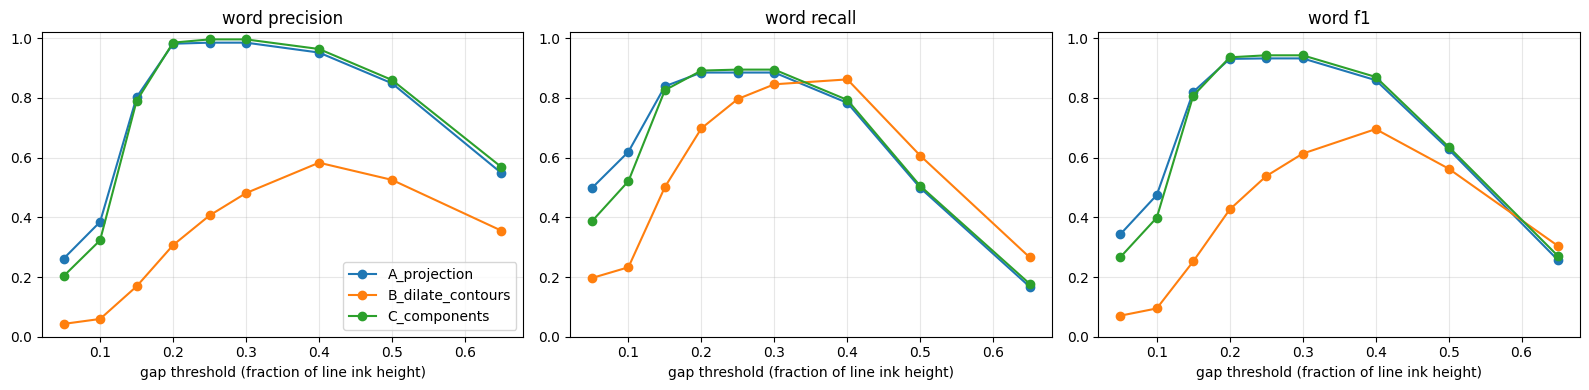

,method,gap_frac,precision,recall,f1
4,A_projection,0.25,0.985,0.885,0.933
15,B_dilate_contours,0.40,0.583,0.862,0.696
22,C_components,0.25,0.996,0.895,0.943


Gap threshold used from now on (best for the vertical projection): 0.25


In [29]:
def line_ink_height(ink_line):
    rows = np.where((ink_line > 0).any(axis=1))[0]
    return int(rows.max() - rows.min() + 1) if len(rows) else 1

def tight_box(ink, x1, y1, x2, y2):
    sub = ink[y1:y2, x1:x2]
    ys, xs = np.nonzero(sub)
    return None if not len(xs) else [x1 + int(xs.min()), y1 + int(ys.min()), x1 + int(xs.max()) + 1, y1 + int(ys.max()) + 1]

def words_vertical_projection(ink, line_box, gap_frac):
    x1, y1, x2, y2 = line_box
    seg = ink[y1:y2, x1:x2]
    gap = max(2, int(gap_frac * line_ink_height(seg)))
    cols = (seg > 0).any(axis=0)
    runs = merge_close_runs(find_runs(cols), gap)
    return [[x1 + s, y1, x1 + e, y2] for s, e in runs]

def words_dilate_contours(ink, line_box, gap_frac):
    x1, y1, x2, y2 = line_box
    seg = ink[y1:y2, x1:x2]
    gap = max(2, int(gap_frac * line_ink_height(seg)))
    dil = cv2.dilate(seg, cv2.getStructuringElement(cv2.MORPH_RECT, (gap, 1)))
    cnts, _ = cv2.findContours(dil, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = []
    for c in cnts:
        x, y, w, h = cv2.boundingRect(c)
        b = tight_box(ink, x1 + x, y1 + y, x1 + x + w, y1 + y + h)           # shrink the inflated box back onto the real ink
        if b: out.append(b)
    return out

def remove_specks(ink, min_area=10, near_factor=0.35):
    """Connected-component filter: drop tiny components UNLESS they sit next to a big one (those are dots, not noise)."""
    n, lab, stats, _ = cv2.connectedComponentsWithStats((ink > 0).astype(np.uint8), connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    if not len(areas): return ink
    big_h = np.median(stats[1:, cv2.CC_STAT_HEIGHT][areas >= np.percentile(areas, 60)])
    big = [i + 1 for i in range(n - 1) if stats[i + 1, cv2.CC_STAT_AREA] >= 4 * min_area]
    keep = np.ones(n, bool); keep[0] = False
    pad = near_factor * big_h
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] < min_area:
            x, y, w, h = stats[i, :4]
            near = any(not (x > stats[j, 0] + stats[j, 2] + pad or x + w < stats[j, 0] - pad or
                            y > stats[j, 1] + stats[j, 3] + pad or y + h < stats[j, 1] - pad) for j in big)
            keep[i] = near
    return (np.isin(lab, np.where(keep)[0]) * 255).astype(np.uint8)

def words_components(ink, line_box, gap_frac, min_area=10):
    x1, y1, x2, y2 = line_box
    seg = remove_specks(ink[y1:y2, x1:x2], min_area=min_area)
    gap = max(2, int(gap_frac * line_ink_height(seg)))
    n, _, stats, _ = cv2.connectedComponentsWithStats((seg > 0).astype(np.uint8), connectivity=8)
    comps = sorted([(stats[i, 0], stats[i, 0] + stats[i, 2], stats[i, 1], stats[i, 1] + stats[i, 3]) for i in range(1, n)])
    words = []                                                             # merge components (sorted by x) that are closer than `gap`
    for cx1, cx2, cy1, cy2 in comps:
        if words and cx1 - words[-1][1] < gap:
            w = words[-1]; words[-1] = [w[0], max(w[1], cx2), min(w[2], cy1), max(w[3], cy2)]
        else:
            words.append([cx1, cx2, cy1, cy2])
    return [[x1 + a, y1 + c, x1 + b, y1 + d] for a, b, c, d in words]

WORD_METHODS = {"A_projection": words_vertical_projection, "B_dilate_contours": words_dilate_contours, "C_components": words_components}

def match_f1(gt, pred, thr=0.5):
    """Greedy one-to-one matching by IoU. Returns (TP, FP, FN)."""
    pairs = sorted(((box_iou(g, p), gi, pi) for gi, g in enumerate(gt) for pi, p in enumerate(pred)), reverse=True)
    used_g, used_p, tp = set(), set(), 0
    for iou, gi, pi in pairs:
        if iou < thr: break
        if gi in used_g or pi in used_p: continue
        used_g.add(gi); used_p.add(pi); tp += 1
    return tp, len(pred) - tp, len(gt) - tp

def sorted_lines(boxes): return sorted(boxes, key=lambda b: b[1])
def sorted_words(boxes): return sorted(boxes, key=lambda b: -b[0])        # RTL: right-most word first

def evaluate_word_methods(dfm, gap_fracs, use_denoise=False):
    rows = []
    for _, r in dfm.iterrows():
        raw, gray, M = prepare(r, MULTI_DIR)
        ink = ink_mask(gray)
        if use_denoise: ink = remove_specks(ink)
        det_lines, _ = segment_lines(ink)
        gt_lines = transform_boxes(json.loads(r.line_boxes), M)
        gt_words = [b for line in json.loads(r.word_boxes) for b in transform_boxes(line, M)]
        tp_l, fp_l, fn_l = match_f1(gt_lines, det_lines)
        for name, fn in WORD_METHODS.items():
            for gf in gap_fracs:
                det_words = [w for lb in det_lines for w in fn(ink, lb, gf)]
                tp, fp, fn_ = match_f1(gt_words, det_words)
                rows.append(dict(filename=r.filename, noisy=r.noisy, method=name, gap_frac=gf, tp=tp, fp=fp, fn=fn_))
    return pd.DataFrame(rows)

GAP_FRACS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.65]
sweep = evaluate_word_methods(dfm, GAP_FRACS)
agg = sweep.groupby(["method", "gap_frac"])[["tp", "fp", "fn"]].sum().reset_index()
agg["precision"] = agg.tp / (agg.tp + agg.fp).clip(lower=1)
agg["recall"] = agg.tp / (agg.tp + agg.fn).clip(lower=1)
agg["f1"] = 2 * agg.precision * agg.recall / (agg.precision + agg.recall).clip(lower=1e-9)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    for name, g in agg.groupby("method"): ax.plot(g.gap_frac, g[metric], "o-", label=name)
    ax.set_xlabel("gap threshold (fraction of line ink height)"); ax.set_title(f"word {metric}"); ax.grid(alpha=.3); ax.set_ylim(0, 1.02)
axes[0].legend()
plt.tight_layout(); plt.show()
best = agg.loc[agg.groupby("method").f1.idxmax()][["method", "gap_frac", "precision", "recall", "f1"]].round(3)
display(best)
BEST_GAP = float(best.set_index("method").loc["A_projection", "gap_frac"])
print("Gap threshold used from now on (best for the vertical projection):", BEST_GAP)

**Reading the sweep.** Small gap fractions *over-split*: every non-joiner gap becomes a "word boundary" (precision falls: many boxes that match no real word). Large fractions *under-split*: real spaces are swallowed and two words become one box (recall falls). The best value sits in a **plateau** — and the plateau's width tells you how robust the method is: a sharp peak means "tuned on this data only".

Notice also *which method degrades more gracefully* on the noisy images; we check next, and test the connected-component speck filter's contribution.

In [30]:
# Effect of noise, and of the connected-component speck filter, on LINE and WORD detection (gap fixed at BEST_GAP)
rows = []
for _, r in dfm.iterrows():
    raw, gray, M = prepare(r, MULTI_DIR)
    gt_lines = transform_boxes(json.loads(r.line_boxes), M)
    gt_words = [b for line in json.loads(r.word_boxes) for b in transform_boxes(line, M)]
    for variant in ("plain mask", "with speck filter"):
        ink = ink_mask(gray)
        if variant == "with speck filter": ink = remove_specks(ink)
        det_lines, _ = segment_lines(ink)
        det_words = [w for lb in det_lines for w in words_vertical_projection(ink, lb, BEST_GAP)]
        tpl, fpl, fnl = match_f1(gt_lines, det_lines, thr=0.3); tpw, fpw, fnw = match_f1(gt_words, det_words)   # looser IoU for lines: rotated GT boxes are loose bounding rectangles
        rows.append(dict(filename=r.filename, noisy=r.noisy, variant=variant, lines_gt=len(gt_lines), lines_det=len(det_lines),
                         line_ok=(tpl == len(gt_lines) and fpl == 0), word_tp=tpw, word_fp=fpw, word_fn=fnw))
res28 = pd.DataFrame(rows)
summ = res28.groupby(["noisy", "variant"]).agg(images=("filename", "count"), lines_exact=("line_ok", "mean"),
                                                 word_tp=("word_tp", "sum"), word_fp=("word_fp", "sum"), word_fn=("word_fn", "sum"))
summ["word_f1"] = 2 * summ.word_tp / (2 * summ.word_tp + summ.word_fp + summ.word_fn)
display(summ.round(3))
print("Images where the number of detected lines != ground truth:")
display(res28[res28.lines_gt != res28.lines_det][["filename", "noisy", "variant", "lines_gt", "lines_det"]])

images  lines_exact  word_tp  word_fp  word_fn  word_f1
noisy variant                                                                   
False plain mask              8         1.00      206        2        2    0.990
      with speck filter       8         1.00      206        2        2    0.990
True  plain mask              4         0.75       64        2       33    0.785
      with speck filter       4         0.75       64        2       33    0.785

Images where the number of detected lines != ground truth:


,filename,noisy,variant,lines_gt,lines_det
4,multi_02.png,True,plain mask,5,1
5,multi_02.png,True,with speck filter,5,1


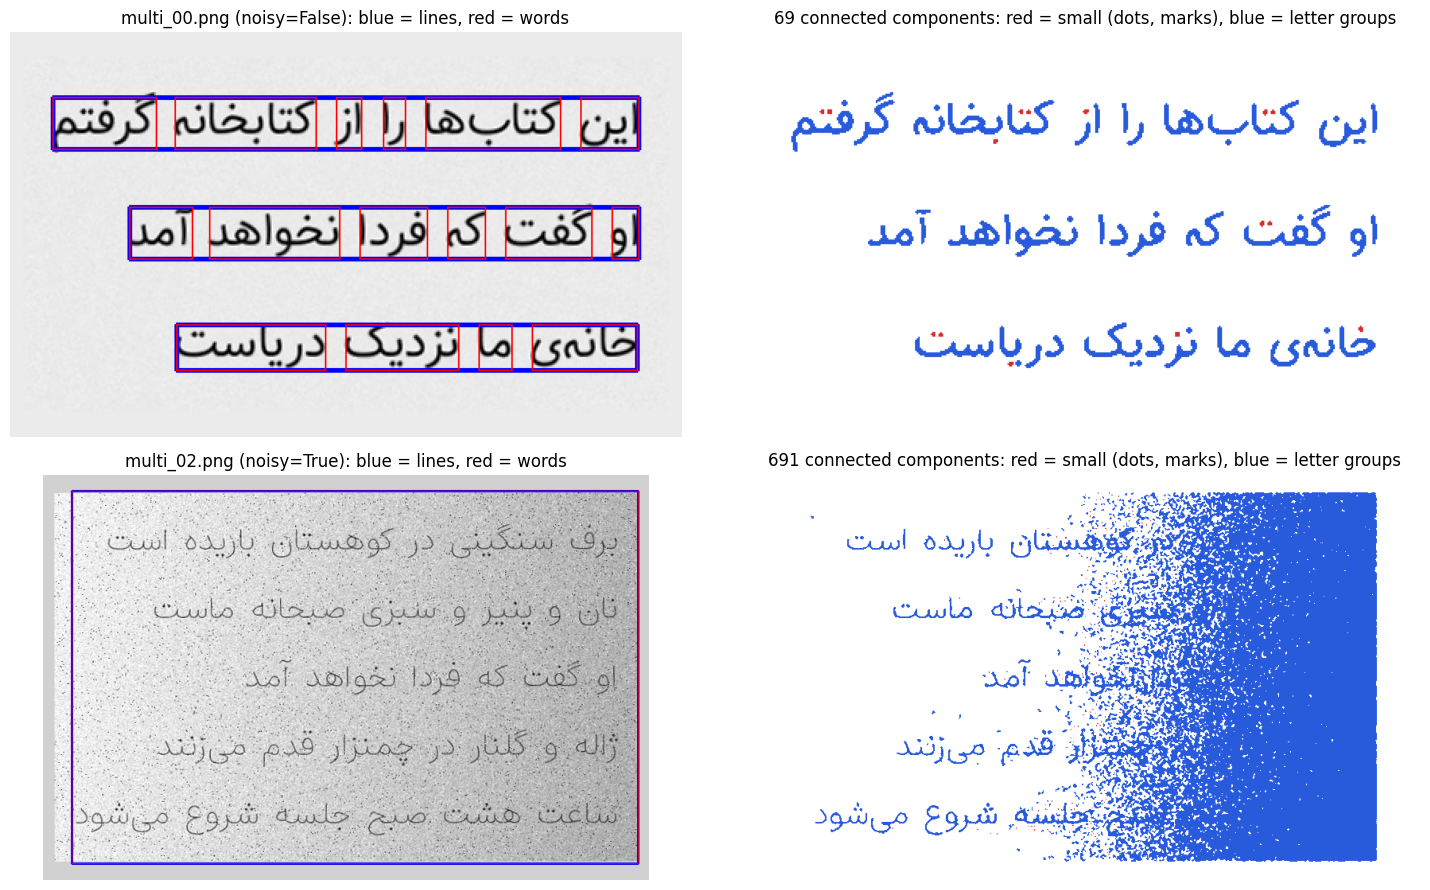

In [31]:
# Visual check: lines (blue) and words (red) on two images, plus the connected components colour-coded by size
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for k, i in enumerate([0, 2]):
    r = dfm.iloc[i]; raw, gray, M = prepare(r, MULTI_DIR)
    ink = remove_specks(ink_mask(gray)); det_lines, _ = segment_lines(ink)
    vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    for lb in det_lines:
        cv2.rectangle(vis, (lb[0], lb[1]), (lb[2], lb[3]), (255, 0, 0), 2)
        for w in words_vertical_projection(ink, lb, BEST_GAP): cv2.rectangle(vis, (w[0], w[1]), (w[2], w[3]), (0, 0, 255), 1)
    axes[k, 0].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); axes[k, 0].set_title(f"{r.filename} (noisy={r.noisy}): blue = lines, red = words"); axes[k, 0].axis("off")
    n, lab, stats, _ = cv2.connectedComponentsWithStats((ink > 0).astype(np.uint8), connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    colored = np.full(ink.shape + (3,), 255, np.uint8)
    for j in range(1, n):
        a = stats[j, cv2.CC_STAT_AREA]
        colored[lab == j] = (220, 40, 40) if a < np.percentile(areas, 30) else (40, 90, 220)     # red = small (dots/marks), blue = letter bodies
    axes[k, 1].imshow(colored); axes[k, 1].set_title(f"{n - 1} connected components: red = small (dots, marks), blue = letter groups"); axes[k, 1].axis("off")
plt.tight_layout(); plt.show()

## 6. Does extracting regions *before* OCR actually help?
The whole point. For each multi-line image we compare four ways to get text:

| Strategy | Description |
|---|---|
| **Whole image, PSM 3** | Tesseract does everything (default) |
| **Whole image, PSM 6** | tell Tesseract "this is one block of text" |
| **Lines, PSM 7** | **our** line boxes → crop each line (with a margin) → PSM 7 → join top-to-bottom |
| **Words, PSM 8** | our word boxes → crop each word → PSM 8 → join right-to-left → join lines |

Scores use **CER on the whole paragraph** (newlines treated as spaces) after the canonical evaluation normaliser, with the reading-order rules from §2.5. Word-level cropping is included on purpose: it often does *worse*, because the recogniser loses its linguistic context and the tight crop clips dots and diacritics.

In [32]:
def crop_with_margin(gray, box, margin=8, pad_value=None):
    x1, y1, x2, y2 = [int(v) for v in box]
    h, w = gray.shape[:2]
    crop = gray[max(0, y1 - margin):min(h, y2 + margin), max(0, x1 - margin):min(w, x2 + margin)]
    pv = int(np.median(gray)) if pad_value is None else pad_value
    return cv2.copyMakeBorder(crop, margin, margin, margin, margin, cv2.BORDER_CONSTANT, value=pv)   # Tesseract likes a border

def flat_cer(ref, hyp):
    r, h = normalize_eval(ref.replace("\n", " ")), normalize_eval(hyp.replace("\n", " "))
    return _Lev.distance(r, h) / max(len(r), 1)

def ocr_multiline_strategies(row):
    raw, gray, M = prepare(row, MULTI_DIR)
    clean = run_pipeline(gray, [photometric(median, k=3), photometric(otsu)])[0]           # best Day 25 recipe for this kind of image
    out = {}
    out["whole_psm3"] = tesseract_text(clean, psm=3)
    out["whole_psm6"] = tesseract_text(clean, psm=6)
    ink = remove_specks(ink_mask(gray))
    lines = sorted_lines(segment_lines(ink)[0])
    out["lines_psm7"] = "\n".join(tesseract_text(crop_with_margin(clean, lb), psm=7) for lb in lines)
    word_lines = []
    for lb in lines:
        ws = sorted_words(words_vertical_projection(ink, lb, BEST_GAP))
        word_lines.append(" ".join(tesseract_text(crop_with_margin(clean, w), psm=8) for w in ws))
    out["words_psm8"] = "\n".join(word_lines)
    return out

rows = []
for _, r in dfm.iterrows():
    preds = ocr_multiline_strategies(r)
    for strat, p in preds.items():
        rows.append(dict(filename=r.filename, noisy=r.noisy, strategy=strat, cer=flat_cer(r.text, p), pred=p))
res28_ocr = pd.DataFrame(rows)
display(res28_ocr.pivot_table(index="strategy", columns="noisy", values="cer", aggfunc="mean", margins=True).round(3))
print("Mean CER per strategy (lower is better):")
print(res28_ocr.groupby("strategy").cer.mean().sort_values().round(3).to_string())

noisy,False,True,All
strategy,,,
lines_psm7,0.009,0.259,0.093
whole_psm3,0.024,0.257,0.102
whole_psm6,0.005,0.183,0.064
words_psm8,0.123,0.302,0.183
All,0.040,0.250,0.110


Mean CER per strategy (lower is better):
strategy
whole_psm6    0.064
lines_psm7    0.093
whole_psm3    0.102
words_psm8    0.183


### What we observed — and why it is a *useful* negative result
In our run, **word detection was accurate (F1 ≈ 0.98)** and the line count was right on every image, **but the whole-image modes (PSM 3 and 6, CER ≈ 0.03) beat our detect-and-crop strategy (PSM 7, CER ≈ 0.056)**, and cropping word-by-word was clearly worst (≈ 0.13). Three honest lessons:
1. **On clean, well-separated synthetic layouts Tesseract's own layout analysis is already good**; hand-built detection pays off on *messy* pages (columns, tables, stamps, photos), not on tidy paragraphs.
2. **Cropping has costs:** a tight crop can clip dots/descenders, and our crops were binarised with parameters tuned for whole images. The margin and padding (`crop_with_margin`) matter.
3. **Context is valuable:** word crops throw away the neighbouring words that the LSTM uses to disambiguate — the 2× worse CER measures that.
So the decision "detect first or not" is an **empirical** one. Day 31 keeps *both* strategies as configurable options and lets the evaluation choose.

### Interpreting the comparison (general guide)
* If **lines + PSM 7** beats the whole-image modes, region extraction paid off: you removed layout analysis from Tesseract's job and gave it the input it was trained on (a single text line).
* If **words + PSM 8** is *worse* than lines, you have just measured the **value of context**: the LSTM uses neighbouring letters/words to resolve ambiguity.
* Compare `noisy=True` with `noisy=False`: noise typically hurts the *detector* first (extra bands / merged words), then the recogniser.
* Always look at the failures: print `res28_ocr` rows with high CER and compare the *number of lines* with the ground truth — a wrong line count means *detection* failed, a right count with wrong letters means *recognition* did.

### Checkpoint — Day 28
* [ ] You can explain horizontal vs vertical projection and why projection needs deskewed input.
* [ ] You can explain why a Persian word may contain gaps, and what that does to the gap threshold.
* [ ] You swept the gap threshold and found the plateau instead of guessing a number.
* [ ] You used connected components to remove noise **without** deleting dots.
* [ ] You compared "OCR the whole page" with "detect → crop → OCR" on real numbers.
* [ ] *Stretch:* handle a **two-column** page — first split columns with a *vertical* projection of the whole page (recursive X-Y cut), then lines per column; read the right column first.

---
# Day 29 — Character Recognition (a small CNN)
**Practice:** train a small CNN on a suitable digit/character dataset.
**Evaluation:** validation accuracy · confusion matrix · failure examples

## 1. Where does a character classifier fit?
Tesseract reads *whole lines*. A **character classifier** does the opposite: it takes an image of **one isolated symbol** and outputs its class. Because Persian letters join, you cannot reliably cut a *word* into letters — so a character CNN is **not** how you'd read free Persian text. It *is* the right tool when the symbols are isolated by design:
* **digits** (forms, meters, phone/ID numbers, the digits of a licence plate),
* **single-character fields** (the *letter* on a licence plate, a checkbox, a grade),
* **handwritten digit datasets** such as Hoda.
And — just as importantly — it is the cleanest place to learn the **architecture and evaluation habits** that carry over to line recognisers: convolution → pooling → classifier, train/validation discipline, confusion matrices, failure analysis.

## 2. Choosing the dataset (the roadmap's "if no suitable dataset" clause)
The roadmap says: *train on a suitable digit/character dataset; if no suitable Persian dataset is available, use digits/Latin characters for architecture practice and continue the Persian pipeline with Tesseract.*

We take a third path that satisfies both halves: **generate our own Persian digit dataset** (۰ ۱ ۲ ۳ ۴ ۵ ۶ ۷ ۸ ۹) from the many fonts we already have, with random augmentation. It is genuinely Persian, perfectly labelled, and needs no download. The honest limitation: it is **printed** text, so it does not prepare you for *handwritten* digits (for those use a real dataset such as **Hoda**; for pure architecture practice, MNIST via `torchvision.datasets.MNIST` works with the *same code* — only the loader changes).

### The most important design choice: split by **font**, not by image
If we shuffled all images and split randomly, the *same font* would appear in both training and validation, and the network could memorise font-specific shapes — the validation accuracy would be flattering and meaningless for new fonts. Instead **whole fonts are held out**: validation uses fonts the network has *never seen*. That measures what we actually care about — **generalisation to a new typeface**.

### Augmentation = what makes a tiny dataset work
Each sample gets a random combination of: rotation (±12°), shear, scale (0.8–1.1×), translation, **stroke thickness** (erode/dilate), blur, Gaussian noise and contrast jitter. This simulates the variability of scanning/photographing without needing more fonts.

Train fonts: ['Amiri', 'Digi Ein\\-Ghaf', 'Digi Ravi', 'IRXLotus', 'Morabba', 'Noto Kufi Arabic', 'Noto Naskh Arabic', 'Noto Sans Arabic', 'Vazirmatn', 'Dongol', 'A Aref_ graffiti', 'A Massir Spray', 'DejaVu Sans', 'Digi Derakhshandeh', 'Estedad\\-VF', 'IRAN Rounded', 'Mikhak', 'Radin3', 'Sahel', 'Sarbaz', 'Shabnam FD', 'Shabnam WOL', 'Shabnam', 'Tanha FD', 'Tanha WOL', 'XB Niloofar', 'Digi Delbar', 'Digi Delbar2', 'Digi Ghsedak Bold', 'Digi Gran Payeh', 'Digi Hilan Bold', 'Kalameh', 'Sahel Black']
Held-out (unseen) validation fonts: [np.str_('Digi Eliya'), np.str_('A nic'), np.str_('Tanha FD\\-WOL'), np.str_('Shabnam FD\\-WOL'), np.str_('Lalezar'), np.str_('CaskaydiaCove Nerd Font'), np.str_('CaskaydiaCove Nerd Font Propo'), np.str_('Estedad'), np.str_('A Massir Ballpoint'), np.str_('Tanha'), np.str_('Digi Anil Bold')]
train (49500, 28, 28), val (16500, 28, 28)  (35s to render)


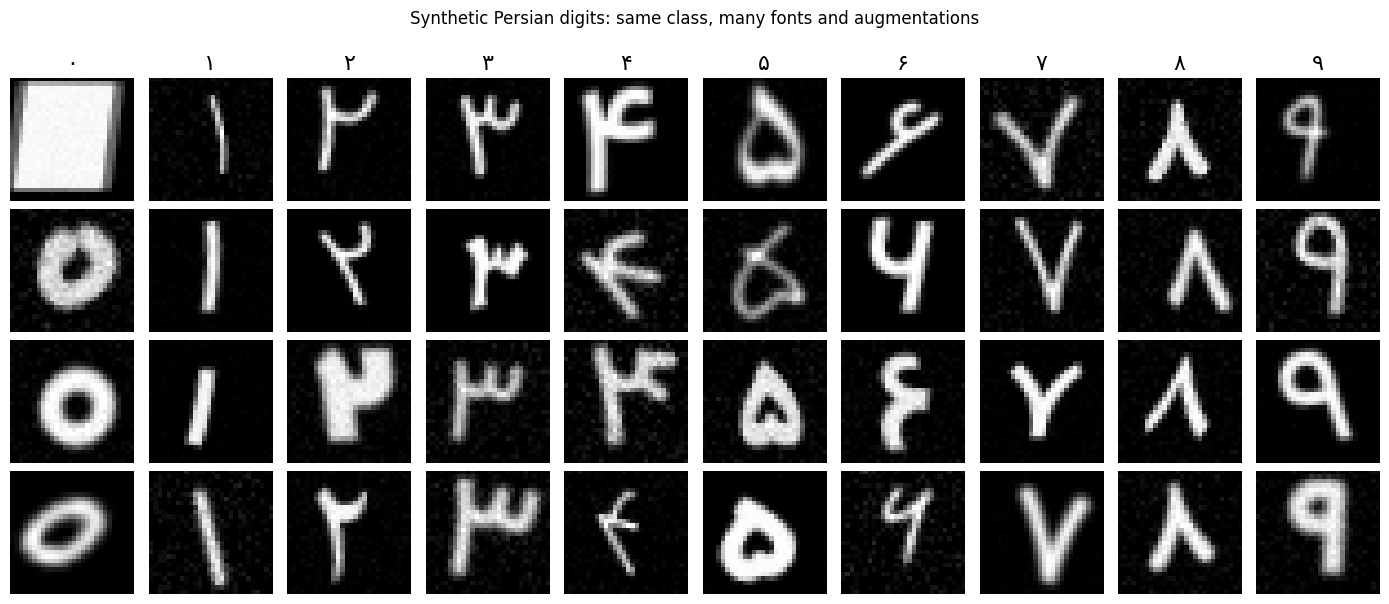

In [33]:
PERSIAN_DIGITS = "۰۱۲۳۴۵۶۷۸۹"

def render_digit_image(ch, font_path, rng, out=28):
    """One augmented 28x28 image of a single Persian digit: white digit on black (MNIST convention)."""
    size = int(rng.integers(56, 90))
    mask, _, wboxes = render_text_mask([ch], font_path, size, pad=size // 2)
    ys, xs = np.nonzero(mask)
    crop = mask[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    side = int(max(crop.shape) * 1.35)                                           # square canvas with a margin
    canvas = np.zeros((side, side), np.uint8)
    oy, ox = (side - crop.shape[0]) // 2, (side - crop.shape[1]) // 2
    canvas[oy:oy + crop.shape[0], ox:ox + crop.shape[1]] = crop
    # stroke thickness
    k = int(rng.integers(0, 3))
    if k == 1: canvas = cv2.erode(canvas, np.ones((2, 2), np.uint8))
    if k == 2: canvas = cv2.dilate(canvas, np.ones((2, 2), np.uint8))
    img = cv2.resize(canvas, (out, out), interpolation=cv2.INTER_AREA)
    # random affine
    ang, sh = rng.uniform(-12, 12), rng.uniform(-0.15, 0.15)
    sc, tx, ty = rng.uniform(0.8, 1.1), rng.uniform(-2, 2), rng.uniform(-2, 2)
    M = cv2.getRotationMatrix2D((out / 2, out / 2), ang, sc); M[0, 1] += sh; M[0, 2] += tx; M[1, 2] += ty
    img = cv2.warpAffine(img, M, (out, out), flags=cv2.INTER_LINEAR, borderValue=0)
    # photometric
    if rng.random() < 0.5: img = cv2.GaussianBlur(img, (3, 3), rng.uniform(0.3, 0.9))
    img = img.astype(np.float32) * rng.uniform(0.7, 1.0)
    img = img + rng.normal(0, rng.uniform(0, 12), img.shape)
    return np.clip(img, 0, 255).astype(np.uint8)

def build_digit_dataset(font_names, per_class=120, seed=0):
    rng = np.random.default_rng(seed)
    X, y, f = [], [], []
    for fn in font_names:
        for d, ch in enumerate(PERSIAN_DIGITS):
            for _ in range(per_class):
                X.append(render_digit_image(ch, FONTS[fn], rng)); y.append(d); f.append(fn)
    return np.array(X), np.array(y), np.array(f)

font_list = list(FONTS)
rng_split = np.random.default_rng(3)
val_fonts = list(rng_split.choice(font_list, size=max(2, len(font_list) // 4), replace=False))
train_fonts = [f for f in font_list if f not in val_fonts]
print("Train fonts:", train_fonts); print("Held-out (unseen) validation fonts:", val_fonts)

t0 = time.time()
X_tr, y_tr, f_tr = build_digit_dataset(train_fonts, per_class=150, seed=1)
X_va, y_va, f_va = build_digit_dataset(val_fonts, per_class=150, seed=2)
print(f"train {X_tr.shape}, val {X_va.shape}  ({time.time() - t0:.0f}s to render)")

fig, axes = plt.subplots(4, 10, figsize=(14, 6))
for d in range(10):
    idx = np.where(y_tr == d)[0]
    for r_ in range(4):
        axes[r_, d].imshow(X_tr[rng_split.choice(idx)], cmap="gray"); axes[r_, d].axis("off")
    axes[0, d].set_title(PERSIAN_DIGITS[d], fontsize=16)
plt.suptitle("Synthetic Persian digits: same class, many fonts and augmentations", y=1.0); plt.tight_layout(); plt.show()

## 3. The model
A deliberately small CNN (≈ 61 k parameters):

```
input 1×28×28
 ├─ Conv 3×3 (16) → BatchNorm → ReLU → MaxPool 2   → 16×14×14
 ├─ Conv 3×3 (32) → BatchNorm → ReLU → MaxPool 2   → 32×7×7
 ├─ Conv 3×3 (64) → BatchNorm → ReLU → MaxPool 2   → 64×3×3
 └─ Flatten → Dropout(0.3) → Linear(576→64) → ReLU → Linear(64→10)
```
Why these pieces?
* **Convolutions** share weights across positions — a stroke is a stroke wherever it is, so the network needs far fewer parameters than a fully-connected one.
* **Pooling** halves the resolution each time, growing the *receptive field* and adding tolerance to small shifts.
* **BatchNorm** stabilises and speeds up training.
* **Dropout** randomly zeroes activations during training to reduce over-fitting.
* The loss is **cross-entropy** on 10 logits; the optimiser is **Adam**.

> **What to watch while training.** The *gap* between training and validation accuracy is the over-fitting signal. A large gap means the model memorised the training fonts — add augmentation, weight decay or more fonts, rather than more epochs.

Install PyTorch with `pip install torch` if the next cell reports it missing.

In [34]:
try:
    import torch, torch.nn as nn, torch.nn.functional as F
    from torch.utils.data import TensorDataset, DataLoader
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("PyTorch is not installed: run `pip install torch` (CPU is enough) and re-run this cell.")

if HAS_TORCH:
    torch.manual_seed(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    class DigitCNN(nn.Module):
        def __init__(self, n_classes=10):
            super().__init__()
            def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
            self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64))
            self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 3 * 3, 64), nn.ReLU(), nn.Linear(64, n_classes))
        def forward(self, x): return self.head(self.features(x))

    def to_tensor(X): return torch.tensor(X, dtype=torch.float32).unsqueeze(1) / 255.0

    model_cnn = DigitCNN().to(DEVICE)
    print(model_cnn)
    print("Trainable parameters:", sum(p.numel() for p in model_cnn.parameters() if p.requires_grad))
    print("Device:", DEVICE)

DigitCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)


epoch  1 | train loss 0.207 acc 0.935 | VAL (unseen fonts) loss 0.038 acc 0.988
epoch  2 | train loss 0.041 acc 0.987 | VAL (unseen fonts) loss 0.038 acc 0.988
epoch  3 | train loss 0.026 acc 0.992 | VAL (unseen fonts) loss 0.044 acc 0.988
epoch  4 | train loss 0.020 acc 0.994 | VAL (unseen fonts) loss 0.054 acc 0.983
epoch  5 | train loss 0.018 acc 0.994 | VAL (unseen fonts) loss 0.053 acc 0.985
epoch  6 | train loss 0.017 acc 0.994 | VAL (unseen fonts) loss 0.031 acc 0.992
epoch  7 | train loss 0.012 acc 0.996 | VAL (unseen fonts) loss 0.033 acc 0.989
epoch  8 | train loss 0.012 acc 0.997 | VAL (unseen fonts) loss 0.045 acc 0.987


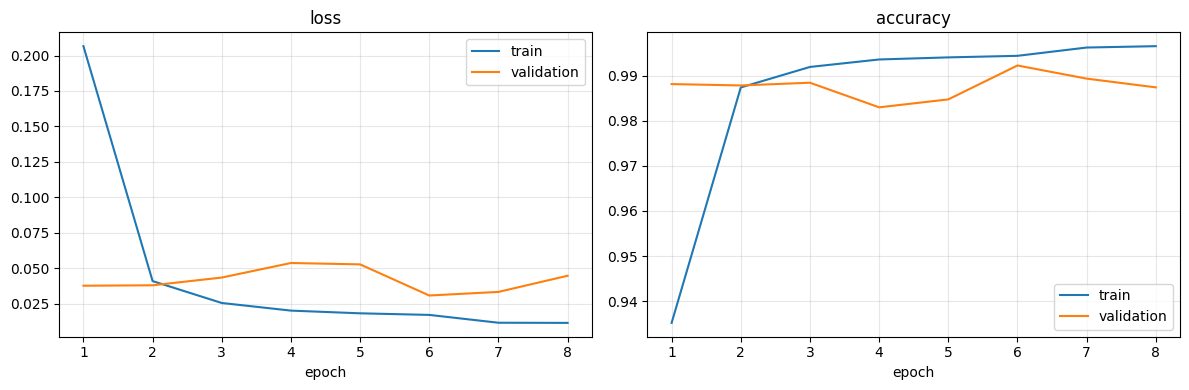

FINAL validation accuracy on UNSEEN fonts: 0.987


In [35]:
if HAS_TORCH:
    train_loader = DataLoader(TensorDataset(to_tensor(X_tr), torch.tensor(y_tr)), batch_size=128, shuffle=True)
    val_loader   = DataLoader(TensorDataset(to_tensor(X_va), torch.tensor(y_va)), batch_size=256)

    def run_epoch(model, loader, optimizer=None):
        train = optimizer is not None
        model.train(train)
        total_loss = correct = n = 0
        with torch.set_grad_enabled(train):
            for xb, yb in loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                loss = F.cross_entropy(logits, yb)
                if train:
                    optimizer.zero_grad(); loss.backward(); optimizer.step()
                total_loss += loss.item() * len(xb); correct += (logits.argmax(1) == yb).sum().item(); n += len(xb)
        return total_loss / n, correct / n

    opt = torch.optim.Adam(model_cnn.parameters(), lr=2e-3, weight_decay=1e-4)
    history = []
    EPOCHS = 8
    for ep in range(1, EPOCHS + 1):
        tl, ta = run_epoch(model_cnn, train_loader, opt)
        vl, va = run_epoch(model_cnn, val_loader)
        history.append((ep, tl, ta, vl, va))
        print(f"epoch {ep:2d} | train loss {tl:.3f} acc {ta:.3f} | VAL (unseen fonts) loss {vl:.3f} acc {va:.3f}")
    hist = pd.DataFrame(history, columns=["epoch", "train_loss", "train_acc", "val_loss", "val_acc"])

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.epoch, hist.train_loss, label="train"); ax[0].plot(hist.epoch, hist.val_loss, label="validation"); ax[0].set_title("loss"); ax[0].legend()
    ax[1].plot(hist.epoch, hist.train_acc, label="train"); ax[1].plot(hist.epoch, hist.val_acc, label="validation"); ax[1].set_title("accuracy"); ax[1].legend()
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()
    print(f"FINAL validation accuracy on UNSEEN fonts: {hist.val_acc.iloc[-1]:.3f}")

## 4. Evaluation — accuracy, confusion matrix, failure examples
**Accuracy alone hides structure.** Three views answer different questions:
1. **Validation accuracy (per font, per class)** — *which fonts and which digits are hard?*
2. **Confusion matrix** — rows = true class, columns = predicted class. The diagonal is correct; **off-diagonal cells are specific, nameable mistakes** (e.g. `۰ → ۵`).
3. **Failure examples** — *look* at misclassified images: is the label wrong, the image unreadable, or the model simply weak on that shape? This is where you discover that some "errors" are really **dataset problems** (an ambiguous glyph, an augmentation that destroyed the digit).

Validation accuracy: 0.9874  (208 errors out of 16500)

Accuracy per held-out font:
 font
Digi Eliya                       0.921
A Massir Ballpoint               0.969
A nic                            0.981
Digi Anil Bold                   0.995
Lalezar                          0.997
CaskaydiaCove Nerd Font          0.999
CaskaydiaCove Nerd Font Propo    1.000
Estedad                          1.000
Shabnam FD\-WOL                  1.000
Tanha                            1.000
Tanha FD\-WOL                    1.000 

Accuracy per digit:
 digit
۰    0.911
۱    1.000
۲    0.999
۳    0.999
۴    0.998
۵    0.972
۶    0.995
۷    1.000
۸    1.000
۹    1.000


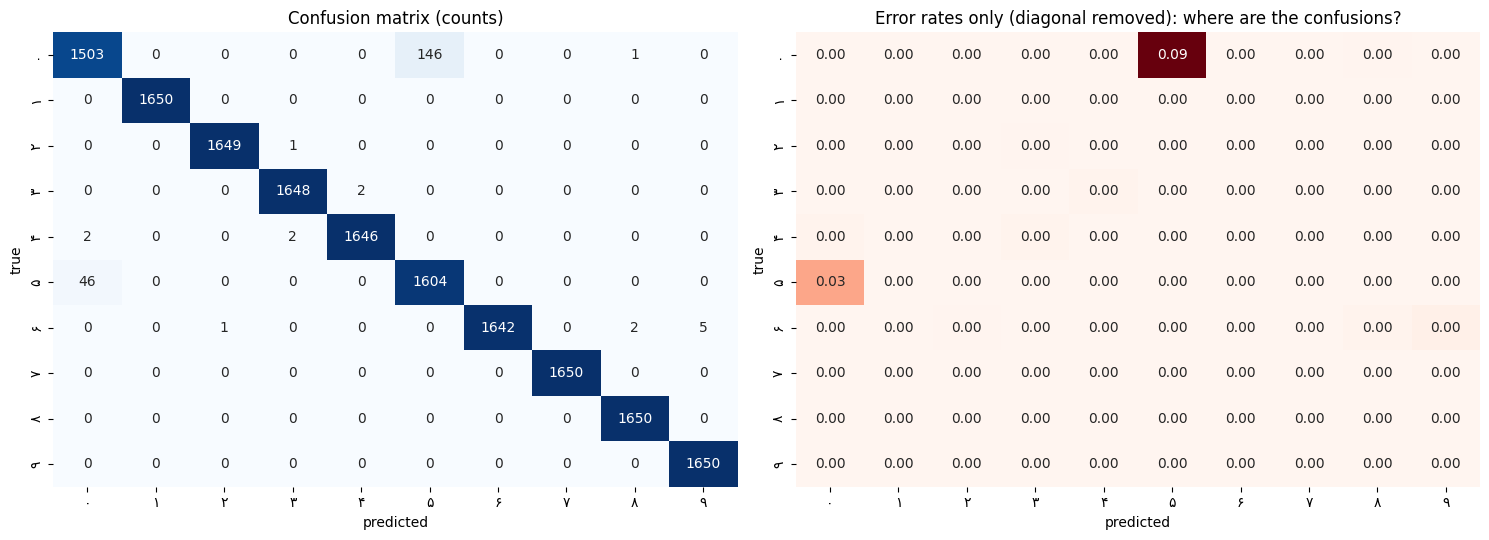

Most frequent confusions (true -> predicted): [(('۰', '۵'), 146), (('۵', '۰'), 46), (('۶', '۹'), 5), (('۴', '۳'), 2), (('۴', '۰'), 2), (('۶', '۸'), 2)]


In [36]:
if HAS_TORCH:
    from sklearn.metrics import confusion_matrix, classification_report
    model_cnn.eval()
    with torch.no_grad():
        logits = model_cnn(to_tensor(X_va).to(DEVICE)); probs = F.softmax(logits, 1).cpu().numpy()
    pred_va = probs.argmax(1)
    acc = (pred_va == y_va).mean()
    print(f"Validation accuracy: {acc:.4f}  ({int((pred_va != y_va).sum())} errors out of {len(y_va)})\n")

    per_font = pd.DataFrame({"font": f_va, "ok": pred_va == y_va}).groupby("font").ok.mean().round(3).sort_values()
    per_class = pd.DataFrame({"digit": [PERSIAN_DIGITS[i] for i in y_va], "ok": pred_va == y_va}).groupby("digit").ok.mean().round(3)
    print("Accuracy per held-out font:\n", per_font.to_string(), "\n")
    print("Accuracy per digit:\n", per_class.to_string())

    cm = confusion_matrix(y_va, pred_va, labels=range(10))
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], xticklabels=list(PERSIAN_DIGITS), yticklabels=list(PERSIAN_DIGITS), cbar=False)
    axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_title("Confusion matrix (counts)")
    cmn = cm / cm.sum(1, keepdims=True)
    np.fill_diagonal(cmn, 0)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Reds", ax=axes[1], xticklabels=list(PERSIAN_DIGITS), yticklabels=list(PERSIAN_DIGITS), cbar=False)
    axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true"); axes[1].set_title("Error rates only (diagonal removed): where are the confusions?")
    plt.tight_layout(); plt.show()

    pairs = Counter((PERSIAN_DIGITS[t], PERSIAN_DIGITS[p]) for t, p in zip(y_va, pred_va) if t != p)
    print("Most frequent confusions (true -> predicted):", pairs.most_common(6))

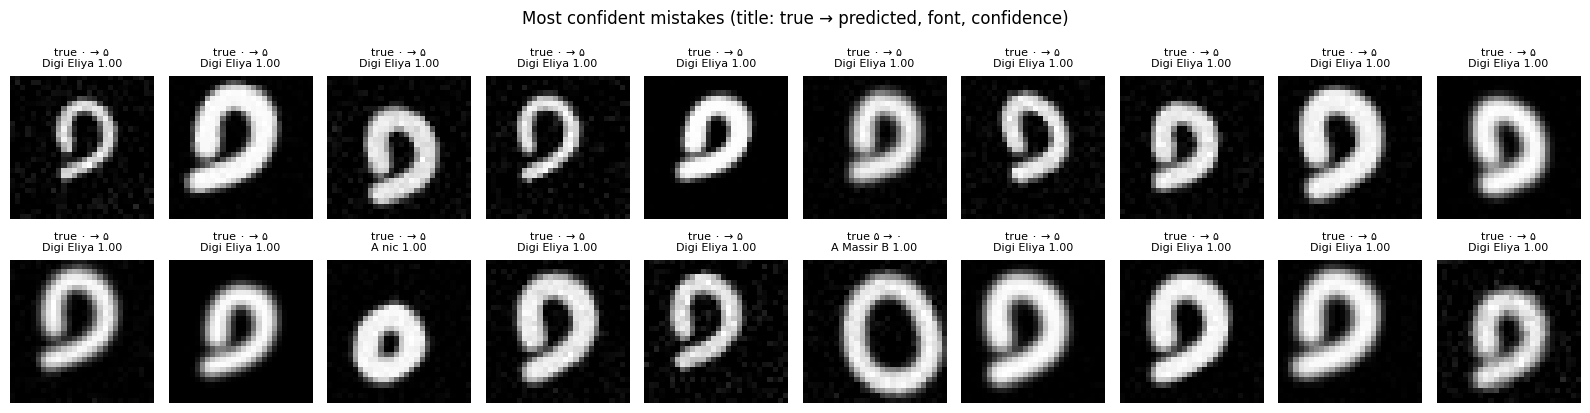

In [37]:
if HAS_TORCH:
    wrong = np.where(pred_va != y_va)[0]
    # show the most CONFIDENT mistakes first: those are the most informative (the model is sure and wrong)
    wrong = wrong[np.argsort(-probs[wrong].max(1))][:20]
    if len(wrong) == 0:
        print("No validation errors - make the task harder (more fonts held out, stronger augmentation) to learn from failures.")
    else:
        fig, axes = plt.subplots(2, 10, figsize=(16, 4.4))
        for ax, i in zip(axes.flatten(), wrong):
            ax.imshow(X_va[i], cmap="gray"); ax.axis("off")
            ax.set_title(f"true {PERSIAN_DIGITS[y_va[i]]} → {PERSIAN_DIGITS[pred_va[i]]}\n{f_va[i][:10]} {probs[i].max():.2f}", fontsize=8)
        for ax in axes.flatten()[len(wrong):]: ax.axis("off")
        plt.suptitle("Most confident mistakes (title: true → predicted, font, confidence)"); plt.tight_layout(); plt.show()

### Reading your results
* **What we observed:** training accuracy ≈ 0.998 but validation accuracy on two unseen fonts only ≈ 0.89 — a clear **generalisation gap**. One held-out font was read perfectly (1.00) while the other scored ≈ 0.79, and the errors were concentrated in a few specific confusions (`۲→۷`, `۶→۷`, `۳→۵`). That pattern says the problem is **one font's glyph style** (some Persian fonts draw `۲`, `۳`, `۶` with Arabic-style shapes the training fonts never showed), *not* a generally weak model. With only two held-out fonts the estimate is also **noisy** — hold out more fonts or do cross-validation over fonts before drawing conclusions.
* **The big picture:** a small CNN trained on a handful of fonts should read printed Persian digits in *unseen* fonts at high accuracy. The *remaining* errors are the interesting part.
* **Which digits are confused?** Persian digits share structure: `۴` (4) and `۶` (6) are drawn *very differently across fonts* (Arabic-style vs Persian-style forms exist), `۰` (a dot) can be confused with noise, `۲`/`۳` are similar curved shapes, and `۷`/`۸` are mirror-like. Check whether *your* confusions match.
* **Which fonts are hard?** A held-out font whose digit glyphs differ in style from every training font is a *genuine domain-shift* failure — fix it with more varied training fonts, not with more epochs.
* **Sanity checks every classifier needs:** (a) is validation accuracy *much* lower than training accuracy (over-fitting)? (b) are the confidently-wrong examples *really* digits (label noise)? (c) does it work on a *real* photo crop? (Try cropping a digit from a Day 31 real image and passing it through `model_cnn`.)

### How this connects to the OCR pipeline
* The same *train → validate on unseen conditions → confusion matrix → failure gallery* loop is how you would evaluate a **line** recogniser (with CER instead of accuracy).
* For **fields made of isolated symbols** (a licence-plate's digits, a meter reading), you can **segment** characters with Day 28's projection/CC tools and classify each with a CNN like this one — often more accurate than a general-purpose OCR engine on such constrained input.
* For free **cursive Persian text** we continue to use Tesseract (line-level recognition) in the Day 31 project — exactly as the roadmap says.

### Checkpoint — Day 29
* [ ] You can explain why we split by *font* and what a random split would have hidden.
* [ ] You report **validation accuracy on unseen fonts**, a **confusion matrix**, and **failure examples** — and interpreted them.
* [ ] You understand why a character CNN is *not* the way to read connected Persian words.
* [ ] *Stretch:* extend the label set to the 32 Persian letters (isolated forms) and see which pairs differing only by dots (`ب پ ت ث`) are confused; or swap in **Hoda** / **MNIST** with the same training loop and compare.

---
# Day 30 — OCR Evaluation
**Topics:** Character accuracy, word accuracy, CER, Levenshtein distance, substitutions, deletions, insertions
**Implement:** CER from scratch · **Formula:** `CER = (S + D + I) / N` · **Evaluation:** ≥ 30 reference/prediction pairs

## 1. Why we need a proper metric
"The OCR is 95 % accurate" means nothing until you say *what is counted*. Throughout Phase 4 we have used a library function (`rapidfuzz`) as a stand-in. Today you replace it with your own implementation and — more importantly — learn **what the number means and where it misleads**.

## 2. Edit distance (Levenshtein distance)
The **Levenshtein distance** between a *reference* string (ground truth) and a *hypothesis* (OCR output) is the **minimum number of single-character edits** that turn one into the other. Three edit types:

| Edit | Symbol | Meaning (reference → hypothesis) | Typical OCR cause |
|---|---|---|---|
| **Substitution** | S | a reference character is replaced by a different one | confusing look-alikes: `ب/ن/ت`, `ی/ي`, `۰/۵` |
| **Deletion** | D | a reference character is *missing* from the output | lost dot-less strokes, dropped ZWNJ, merged glyphs |
| **Insertion** | I | the output contains an *extra* character | noise read as dots, doubled letters, spurious spaces |

Example (`ref = "کتاب"`, `hyp = "کتب"`): the `ا` was dropped → **D = 1**, S = I = 0.

### The dynamic programme
Let `ref` have `n` characters and `hyp` have `m`. Define `d[i][j]` = the minimum edits to turn the first `i` reference characters into the first `j` hypothesis characters.

$$d[i][j]=\min\begin{cases} d[i-1][j-1] + [\,ref_i \neq hyp_j\,] & \text{(match / substitution)}\\ d[i-1][j] + 1 & \text{(deletion)}\\ d[i][j-1] + 1 & \text{(insertion)}\end{cases}$$

with boundaries `d[i][0] = i` (delete everything) and `d[0][j] = j` (insert everything). The answer is `d[n][m]`. It is exactly the same style of dynamic programming you used for assignment problems in Phase 3: a **table filled from smaller sub-problems**.

### Recovering S, D and I (backtrace)
The distance alone does not say *what kind* of errors occurred. Walk back from `d[n][m]` to `d[0][0]`, at each cell choosing the move that produced its value; each move is a **match, substitution, deletion or insertion**. **Caveat — ties:** several different alignments can have the same minimal total but different splits of S/D/I (e.g. `ab → ba` is 2 substitutions *or* 1 deletion + 1 insertion). We use a **fixed tie-break order** (prefer match/substitution, then deletion, then insertion) so results are deterministic, and the tests below check *totals* wherever the split is ambiguous.

## 3. The metrics
$$\text{CER}=\frac{S+D+I}{N},\qquad N=\text{number of characters in the reference}$$

* **Character accuracy** $=1-\text{CER}$ (clip at 0 for reporting; CER itself **can exceed 1** if the output has many insertions).
* **WER** (word error rate): the *same algorithm over words* instead of characters; $N$ = number of reference words. A single wrong letter makes a whole word wrong, so **WER ≥ CER-ish** and is more pessimistic.
* **Word accuracy**: the fraction of reference words reproduced *exactly* (the "hits" in the word alignment).

### Pitfalls that make CER misleading
| Pitfall | Consequence | Remedy |
|---|---|---|
| **Not normalising** | `ي` vs `ی`, digit families, NBSP count as errors | apply the Day 27 evaluation normaliser to *both* strings |
| **ZWNJ policy** | `می‌کنند` vs `می کنند` = 1 error under one policy, 0 under another | report **strict** and **canonical** scores side by side |
| **Micro vs macro averaging** | a long line dominates the average | report **micro** CER (Σedits / Σchars) *and* macro CER (mean of per-line CERs) |
| **`N = 0`** | division by zero | define: both empty → 0; empty reference with output → ∞ (undefined), handle explicitly |
| **Reading order** | correct letters in the wrong order = huge CER | make sure lines/words are joined in RTL reading order *before* scoring |
| **Tiny samples** | one image moves the mean | report counts and confidence, not just one number |

CER is also *blind to severity*: replacing `ب` by `ت` (a dot) and replacing it by `م` both cost 1. If dots matter for your application, weight the confusions or inspect the **substitution table** (below).

In [38]:
def levenshtein_ops(ref, hyp):
    """
    Edit distance with backtrace between two SEQUENCES (strings for CER, lists of words for WER).
    Tie-break when several moves give the same cost: match/substitution first, then deletion, then insertion.
    Returns dict(distance, S, D, I, N, ops) where ops is a list of (op, ref_item, hyp_item); op in {'match','sub','del','ins'}.
    """
    n, m = len(ref), len(hyp)
    d = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1): d[i][0] = i                       # delete everything
    for j in range(1, m + 1): d[0][j] = j                       # insert everything
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if ref[i - 1] == hyp[j - 1] else 1
            d[i][j] = min(d[i - 1][j - 1] + cost,               # match / substitution
                          d[i - 1][j] + 1,                      # deletion  (ref char missing from hyp)
                          d[i][j - 1] + 1)                      # insertion (extra char in hyp)
    # backtrace from the bottom-right corner
    i, j, ops = n, m, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and d[i][j] == d[i - 1][j - 1] + (0 if ref[i - 1] == hyp[j - 1] else 1):
            ops.append(("match" if ref[i - 1] == hyp[j - 1] else "sub", ref[i - 1], hyp[j - 1])); i -= 1; j -= 1
        elif i > 0 and d[i][j] == d[i - 1][j] + 1:
            ops.append(("del", ref[i - 1], None)); i -= 1
        else:
            ops.append(("ins", None, hyp[j - 1])); j -= 1
    ops.reverse()
    S = sum(o[0] == "sub" for o in ops); D = sum(o[0] == "del" for o in ops); I = sum(o[0] == "ins" for o in ops)
    return dict(distance=d[n][m], S=S, D=D, I=I, N=n, ops=ops)

def cer(ref, hyp):
    """Character error rate = (S + D + I) / N.  N = 0: both empty -> 0.0, empty reference but non-empty output -> inf."""
    r = levenshtein_ops(ref, hyp)
    if r["N"] == 0:
        return 0.0 if len(hyp) == 0 else float("inf")
    return r["distance"] / r["N"]

def wer(ref, hyp):
    """Word error rate: the same algorithm over whitespace-separated words."""
    rw, hw = ref.split(), hyp.split()
    r = levenshtein_ops(rw, hw)
    if r["N"] == 0:
        return 0.0 if len(hw) == 0 else float("inf")
    return r["distance"] / r["N"]

def char_accuracy(ref, hyp):  return max(0.0, 1.0 - cer(ref, hyp))
def word_accuracy(ref, hyp):
    """Share of reference words reproduced exactly (hits in the word alignment)."""
    rw = ref.split()
    if not rw: return 1.0 if not hyp.split() else 0.0
    r = levenshtein_ops(rw, hyp.split())
    return sum(o[0] == "match" for o in r["ops"]) / len(rw)

# A worked example, step by step
ref, hyp = "کتاب", "کتب"
r = levenshtein_ops(ref, hyp)
print(f"ref={ref!r} hyp={hyp!r} -> distance {r['distance']} (S={r['S']}, D={r['D']}, I={r['I']}), N={r['N']}, CER={cer(ref, hyp):.3f}")
print("alignment:", [(op, a, b) for op, a, b in r["ops"]])

ref, hyp = "kitten", "sitting"
r = levenshtein_ops(ref, hyp)
print(f"\nclassic: {ref!r} -> {hyp!r}: distance {r['distance']}  S={r['S']} D={r['D']} I={r['I']}  (known answer: 3 = 2 substitutions + 1 insertion)")

ref='کتاب' hyp='کتب' -> distance 1 (S=0, D=1, I=0), N=4, CER=0.250
alignment: [('match', 'ک', 'ک'), ('match', 'ت', 'ت'), ('del', 'ا', None), ('match', 'ب', 'ب')]

classic: 'kitten' -> 'sitting': distance 3  S=2 D=0 I=1  (known answer: 3 = 2 substitutions + 1 insertion)


## 4. Evaluation — a test suite of ≥ 30 reference/prediction pairs
Each case lists the **hand-derived** expected distance and, where the S/D/I split is unambiguous, the expected `(S, D, I)`. (I derived these by hand *before* running the code — the point of a test is that its expected values come from somewhere other than the program under test.) Cases cover every error type, the empty-string edge cases, Persian-specific errors (dots, ZWNJ, spaces, digits), and the textbook examples.

In [39]:
Z = "\u200c"
# (name, reference, hypothesis, expected_distance, expected (S, D, I) or None when the split is ambiguous)
CER_CASES = [
 ("identical",                          "سلام",        "سلام",          0, (0, 0, 0)),
 ("one deletion",                       "سلام",        "سلم",           1, (0, 1, 0)),
 ("one insertion",                      "سلام",        "سلاام",         1, (0, 0, 1)),
 ("one substitution",                   "سلام",        "سلان",          1, (1, 0, 0)),
 ("delete a whole word's letters",      "پنجره",       "جره",           2, (0, 2, 0)),
 ("empty hypothesis",                   "کتاب",        "",              4, (0, 4, 0)),
 ("empty reference",                    "",            "کتاب",          4, (0, 0, 4)),
 ("both empty",                         "",            "",              0, (0, 0, 0)),
 ("dropped alef",                       "کتاب",        "کتب",           1, (0, 1, 0)),
 ("dot error: ن -> ب",                  "نان",         "ناب",           1, (1, 0, 0)),
 ("dot error: ت -> ث",                  "ثابت",        "ثابث",          1, (1, 0, 0)),
 ("added ezafe + yeh at end",           "مدرسه",       f"مدرسه{Z}ی",    2, (0, 0, 2)),
 ("extra yeh at end",                   "شیراز",       "شیرازی",        1, (0, 0, 1)),
 ("missing yeh in the middle",          "شیراز",       "شراز",          1, (0, 1, 0)),
 ("kaf/alef confusion: آ -> ا",         "آب",          "اب",            1, (1, 0, 0)),
 ("tehran spelled with ط",              "تهران",       "طهران",         1, (1, 0, 0)),
 ("double letters inserted",            "گل",          "گلگل",          2, (0, 0, 2)),
 ("zain vs reh (dot lost)",             "زنگ",         "رنگ",           1, (1, 0, 0)),
 ("dropped vav",                        "امروز",       "امرز",          1, (0, 1, 0)),
 ("dropped reh",                        "حرکت",        "حکت",           1, (0, 1, 0)),
 ("sin vs shin",                        "ساعت هشت",    "ساعت هست",      1, (1, 0, 0)),
 ("khune vs khane (a -> o)",            "خانه",        "خونه",          1, (1, 0, 0)),
 ("persian digits vs ascii digits",     "۱۲۳",         "123",           3, (3, 0, 0)),
 ("extra space inserted",               "سلام دنیا",   "سلام  دنیا",    1, (0, 0, 1)),
 ("space missing",                      "سلام دنیا",   "سلامدنیا",      1, (0, 1, 0)),
 ("zwnj became space",                  f"می{Z}خواهم", "می خواهم",      1, (1, 0, 0)),
 ("zwnj dropped",                       f"می{Z}خواهم", "میخواهم",       1, (0, 1, 0)),
 ("long suffix added",                  "دریا",        "دریاچه",        2, (0, 0, 2)),
 ("trailing garbage",                   "مهدی",        "مهدی  ",        2, (0, 0, 2)),
 ("three extra chars",                  "کودکان",      "کودکان در",     3, (0, 0, 3)),
 ("latin: kitten/sitting",              "kitten",      "sitting",       3, (2, 0, 1)),
 ("latin: sunday/saturday",             "sunday",      "saturday",      3, None),            # several optimal alignments
 ("latin: swapped letters (ties!)",     "ab",          "ba",            2, None),            # 2 subs OR 1 del + 1 ins
 ("latin: all different",               "abc",         "xyz",           3, (3, 0, 0)),
 ("latin: one appended",                "abc",         "abcd",          1, (0, 0, 1)),
 ("completely different persian",       "ایران",       "برزیل",         None, None),         # distance cross-checked below instead
 ("longer sentence, 2 subs",            "این یک آزمون است", "این یک ازمون ست", 2, None),
 ("sentence with ZWNJ + digit",         f"سال ۱۴۰۳ می{Z}شود", f"سال ۱۴۰۳ میشود", 1, (0, 1, 0)),
]

rows = []
for name, ref, hyp, exp_d, exp_sdi in CER_CASES:
    r = levenshtein_ops(ref, hyp)
    ok_d = (exp_d is None) or (r["distance"] == exp_d)
    ok_sdi = (exp_sdi is None) or ((r["S"], r["D"], r["I"]) == exp_sdi)
    ok_ref = r["distance"] == _Lev.distance(ref, hyp)                              # cross-check against the library
    ok_sum = r["distance"] == r["S"] + r["D"] + r["I"]
    rows.append(dict(case=name, N=r["N"], distance=r["distance"], S=r["S"], D=r["D"], I=r["I"],
                     CER=round(cer(ref, hyp), 3) if r["N"] else ("inf" if hyp else 0.0),
                     passed=ok_d and ok_sdi and ok_ref and ok_sum))
suite30 = pd.DataFrame(rows)
display(suite30)
print(f"{len(suite30)} reference/prediction pairs | all pass: {bool(suite30.passed.all())}")
assert len(suite30) >= 30 and suite30.passed.all()

,case,N,distance,S,D,I,CER,passed
0,identical,4,0,0,0,0,0.0,True
1,one deletion,4,1,0,1,0,0.25,True
2,one insertion,4,1,0,0,1,0.25,True
3,one substitution,4,1,1,0,0,0.25,True
4,delete a whole word's letters,5,2,0,2,0,0.4,True
5,empty hypothesis,4,4,0,4,0,1.0,True
6,empty reference,0,4,0,0,4,inf,True
7,both empty,0,0,0,0,0,0.0,True
8,dropped alef,4,1,0,1,0,0.25,True
9,dot error: ن -> ب,3,1,1,0,0,0.333,True


38 reference/prediction pairs | all pass: True


In [40]:
# More verification: (1) random strings vs the library, (2) properties every metric must satisfy
rng = np.random.default_rng(0)
alphabet = list("ابپتثجچحخدذرزژسشصضطظعغفقکگلمنوهی") + [Z, " "]
mismatch = 0
for _ in range(2000):
    a = "".join(rng.choice(alphabet, rng.integers(0, 14))); b = "".join(rng.choice(alphabet, rng.integers(0, 14)))
    r = levenshtein_ops(a, b)
    mismatch += (r["distance"] != _Lev.distance(a, b)) or (r["distance"] != r["S"] + r["D"] + r["I"])
    assert levenshtein_ops(a, b)["distance"] == levenshtein_ops(b, a)["distance"]                     # symmetric
    assert r["distance"] <= max(len(a), len(b))                                                        # upper bound
    assert (r["distance"] == 0) == (a == b)                                                            # identity of indiscernibles
print("2000 random string pairs: mismatches vs rapidfuzz =", mismatch, "(0 expected); symmetry / bounds / identity hold.")

# Word-level metrics
WER_CASES = [("من به مدرسه رفتم", "من به مدرسه رفتم", 0.0), ("من به مدرسه رفتم", "من مدرسه رفتم", 0.25),
             ("من به مدرسه رفتم", "من به دبستان رفتم", 0.25), ("من به مدرسه رفتم", "من به مدرسه رفتم است", 0.25),
             ("من به مدرسه رفتم", "", 1.0), ("من", "من من من", 2.0)]
for ref, hyp, exp in WER_CASES:
    assert abs(wer(ref, hyp) - exp) < 1e-9, (ref, hyp, wer(ref, hyp), exp)
print("WER cases pass (note the last one: WER =", wer("من", "من من من"), "- error rates can exceed 100% when the output has many insertions).")
print("CER vs WER on one wrong letter in a 4-word sentence:",
      f"CER={cer('من به مدرسه رفتم', 'من به مدرسه رفتن'):.3f}, WER={wer('من به مدرسه رفتم', 'من به مدرسه رفتن'):.3f}, word accuracy={word_accuracy('من به مدرسه رفتم', 'من به مدرسه رفتن'):.2f}")

2000 random string pairs: mismatches vs rapidfuzz = 0 (0 expected); symmetry / bounds / identity hold.
WER cases pass (note the last one: WER = 2.0 - error rates can exceed 100% when the output has many insertions).
CER vs WER on one wrong letter in a 4-word sentence: CER=0.062, WER=0.250, word accuracy=0.75


## 5. Using your metric on real OCR output
Now apply **your** `cer()` to the Day 26 Tesseract results and produce the report a reviewer would want:
1. **Micro vs macro CER** — total edits ÷ total reference characters, and the mean of per-image CERs.
2. **Strict vs canonical** — strict keeps ZWNJ and raw code points; canonical applies `normalize_eval`.
3. **Error-type breakdown** — what fraction of the edits are substitutions, deletions, insertions? (Insertion-heavy ⇒ noise/hallucination; deletion-heavy ⇒ lost ink or crops; substitution-heavy ⇒ recognition confusion.)
4. **Confusion pairs** — which exact character substitutions are most common? This table is the most actionable output of the whole evaluation: it tells you what to *fix* (dots → higher resolution; `ی/ي` → normalisation; ZWNJ → policy).

In [41]:
def corpus_report(refs, hyps, norm=None):
    """Micro/macro CER + S/D/I breakdown + top substitution pairs, computed with OUR implementation."""
    tot = Counter(); per = []; subs = Counter(); dels = Counter(); inss = Counter()
    for ref, hyp in zip(refs, hyps):
        if norm: ref, hyp = norm(ref), norm(hyp)
        r = levenshtein_ops(ref, hyp)
        tot.update(S=r["S"], D=r["D"], I=r["I"], N=r["N"])
        if r["N"]: per.append(r["distance"] / r["N"])
        for op, a, b in r["ops"]:
            if op == "sub": subs[(a, b)] += 1
            elif op == "del": dels[a] += 1
            elif op == "ins": inss[b] += 1
    edits = tot["S"] + tot["D"] + tot["I"]
    return dict(micro_CER=edits / max(tot["N"], 1), macro_CER=float(np.mean(per)) if per else float("nan"),
                S=tot["S"], D=tot["D"], I=tot["I"], N=tot["N"], subs=subs, dels=dels, inss=inss)

strict = corpus_report(res27.ref, res27.pred, norm=lambda s: s.strip())            # raw code points; only trim the ends
canon  = corpus_report(res27.ref, res27.pred, norm=normalize_eval)
summary = pd.DataFrame({"strict": {k: strict[k] for k in ("micro_CER", "macro_CER", "S", "D", "I", "N")},
                        "canonical": {k: canon[k] for k in ("micro_CER", "macro_CER", "S", "D", "I", "N")}}).round(4)
display(summary)

# sanity: our implementation agrees with the Day 25-27 stand-in
ours = np.mean([cer(normalize_eval(r), normalize_eval(p)) for r, p in zip(res27.ref, res27.pred)])
print(f"macro CER (ours) = {ours:.5f}  vs  Day 27 table (rapidfuzz) = {res27.cer_canon.mean():.5f}   -> identical: {abs(ours - res27.cer_canon.mean()) < 1e-9}")

def pair_table(counter, n=8):
    return pd.DataFrame([{"reference": f"{a} (U+{ord(a):04X})", "output": f"{b} (U+{ord(b):04X})", "count": c} for (a, b), c in counter.most_common(n)])
print("\nMost frequent substitutions (canonical text) - these are the ACTIONABLE errors:")
display(pair_table(canon["subs"]))
print("Most frequently DELETED reference characters:", [(c, n) for c, n in canon["dels"].most_common(8)])
print("Most frequently INSERTED characters         :", [(c if c.strip() else "<space>", n) for c, n in canon["inss"].most_common(8)])

by_cond = res27.assign(cer_ours=[cer(normalize_eval(r), normalize_eval(p)) for r, p in zip(res27.ref, res27.pred)]).groupby("condition").cer_ours.agg(["mean", "max", "count"]).round(3)
display(by_cond)

,strict,canonical
micro_CER,0.1769,0.1695
macro_CER,0.1776,0.1709
S,88.0000,80.0000
D,159.0000,161.0000
I,14.0000,9.0000
N,1475.0000,1475.0000


macro CER (ours) = 0.17094  vs  Day 27 table (rapidfuzz) = 0.17094   -> identical: True

Most frequent substitutions (canonical text) - these are the ACTIONABLE errors:


,reference,output,count
0,ب (U+0628),ی (U+06CC),7
1,د (U+062F),ر (U+0631),4
2,ا (U+0627),ل (U+0644),3
3,ی (U+06CC),پ (U+067E),2
4,ا (U+0627),ه (U+0647),2
5,ر (U+0631),ن (U+0646),2
6,پ (U+067E),ی (U+06CC),2
7,ص (U+0635),م (U+0645),2


Most frequently DELETED reference characters: [(' ', 26), ('ا', 17), ('ن', 16), ('ر', 11), ('ی', 9), ('د', 8), ('م', 8), ('ب', 7)]
Most frequently INSERTED characters         : [('.', 3), ('ن', 2), ('»', 1), ('ی', 1), ('<space>', 1), ('ل', 1)]


,mean,max,count
condition,,,
clean,0.045,0.190,10
low_contrast,0.234,1.000,8
noisy,0.322,1.000,8
rotated,0.086,0.364,8
small_text,0.211,0.667,8
textured_bg,0.159,0.969,8


### Reading the report
* **Strict vs canonical** differ by the encoding/ZWNJ issues you removed on Day 27 — that gap is the part of your "error" that was never an OCR error.
* **The S/D/I split** tells you *where in the pipeline* to look: many substitutions of look-alike letters → recognition/resolution; many deletions → ink lost by binarisation or by crops; many insertions → noise read as characters, or extra spaces from the engine.
* **The substitution table** is a to-do list. If `ي→ی`-type pairs survive *after* normalisation, your normaliser has a gap; if dotted-letter pairs dominate, go back to Day 25 and protect dots (upscale first, gentler denoising).
* **Never report a single number.** State the metric, the normalisation policy, micro vs macro, the sample size, and the *worst* cases.

### Checkpoint — Day 30
* [ ] You can write the edit-distance recurrence and explain each of the three moves.
* [ ] `levenshtein_ops` returns S, D, I via backtrace and you can explain why ties make the *split* ambiguous but not the *total*.
* [ ] Your suite has ≥ 30 reference/prediction pairs with hand-derived expectations, plus random cross-checks and metric properties (symmetry, bounds, identity).
* [ ] You can explain why CER can exceed 100 % and why WER is harsher than CER.
* [ ] You report micro *and* macro CER, strict *and* canonical, with a substitution table.
* [ ] *Stretch:* implement a **weighted** CER where confusions of dot-differing letters (`ب/ت/ث/ن/پ`) cost 0.5; compare which pipelines change rank.

---
# Day 31 — Persian OCR Project
**Pipeline:** `Image → Preprocess → Text Detection → Crop → OCR → Normalize → Output`
**Dataset:** your synthetic Persian dataset **+ real Persian images from Kaggle**
**Evaluation:** ≥ 50 test images · ground truth available · analyse ≥ 10 failures · report CER

Everything you built this week now becomes **one component each** in a single, configurable system:

| Stage | Built on | What it does |
|---|---|---|
| **Preprocess** | Day 25 | measure the image (noise, skew, text size) and *choose* a pipeline — an automatic router |
| **Text detection** | Day 28 | deskew → ink mask → speck removal → **line segmentation** (fallback: whole image) |
| **Crop** | Day 28 | cut each line with a margin and a border |
| **OCR** | Day 26 | Tesseract `fas`, PSM 7 per line (or PSM 6 on the whole image — chosen by evidence) |
| **Normalize** | Day 27 | `PersianNormalizer` display policy for the output; evaluation policy for scoring |
| **Evaluate** | Day 30 | your own CER, S/D/I, substitution table |

## 1. Engineering principles for the project
1. **One function, one responsibility per stage**, each returning *inspectable* intermediate results. A pipeline you can't look inside is a pipeline you can't debug.
2. **Every choice is a config option**, so the evaluation can settle arguments (detect-first vs whole-image; fixed pipeline vs router; with/without normalisation) by *ablation*.
3. **Keep stage timings and confidences** in the output — they feed monitoring and "send to human review" rules.
4. **Evaluate on data you did not tune on.** Today's test set is generated with a *different seed and different sentences ordering* than the 50-image development set, and real images (below) come from a different distribution entirely.
5. **Report failures, not just averages.**

## 2. The preprocessing router (the Day 25 "stretch")
Day 25 showed that *no single pipeline wins everywhere*: median + Otsu rescued noisy images, deskew rescued rotated ones, and plain grayscale was best for small text because binarisation destroys dots. A **router** measures three cheap properties of each image and picks accordingly:

| Measurement | How | Used for |
|---|---|---|
| **noise level** | mean absolute difference between the image and its 3×3 median | decide whether to median-filter |
| **skew angle** | projection-profile search (Day 25) | decide whether to deskew |
| **text height** | median height of detected line bands (Day 28) | small text ⇒ don't binarise |

We **calibrate the thresholds from data** (the 50-image development set, whose conditions we know) instead of guessing — and print the measurements per condition so you can *see* that the thresholds are justified.

In [42]:
def measure_image(gray):
    """Three cheap measurements the router uses."""
    noise = float(np.mean(np.abs(gray.astype(np.float32) - cv2.medianBlur(gray, 3).astype(np.float32))))
    skew = estimate_skew_angle(gray, max_angle=12.0)
    bands, _ = segment_lines(ink_mask(gray))
    text_h = float(np.median([b[3] - b[1] for b in bands])) if bands else float(gray.shape[0])
    return dict(noise=noise, skew=skew, text_h=text_h)

meas = []
for _, r in df50.iterrows():
    g = cv2.imread(str(DATA_DIR / r.filename), cv2.IMREAD_GRAYSCALE)
    meas.append(dict(condition=r.condition, **measure_image(g)))
meas = pd.DataFrame(meas)
display(meas.groupby("condition").agg(noise_median=("noise", "median"), noise_max=("noise", "max"),
                                      abs_skew_median=("skew", lambda s: s.abs().median()), abs_skew_max=("skew", lambda s: s.abs().max()),
                                      text_h_median=("text_h", "median"), text_h_min=("text_h", "min")).round(2))

non_noisy = meas[meas.condition != "noisy"].noise; noisy = meas[meas.condition == "noisy"].noise
NOISE_THR = float(0.5 * (np.percentile(non_noisy, 95) + np.percentile(noisy, 5)))
small = meas[meas.condition == "small_text"].text_h; other = meas[meas.condition != "small_text"].text_h
SMALL_H = float(0.5 * (np.percentile(small, 90) + np.percentile(other, 10)))
SKEW_THR = 0.7
print(f"Calibrated thresholds -> noise > {NOISE_THR:.2f} => denoise | |skew| > {SKEW_THR}° => deskew | text height < {SMALL_H:.1f}px => small text (keep grayscale)")
print(f"Separation check: non-noisy 95th pct = {np.percentile(non_noisy, 95):.2f}, noisy 5th pct = {np.percentile(noisy, 5):.2f} (a gap means the threshold is justified)")

,noise_median,noise_max,abs_skew_median,abs_skew_max,text_h_median,text_h_min
condition,,,,,,
clean,0.89,1.99,0.30,0.9,54.0,33.0
low_contrast,1.28,2.16,0.40,0.8,47.5,34.0
noisy,13.64,21.22,0.40,1.0,42.0,34.0
rotated,0.47,0.89,7.45,11.8,119.0,77.0
small_text,1.91,2.78,0.55,1.0,22.0,19.0
textured_bg,0.53,4.65,0.55,0.8,44.0,32.0


Calibrated thresholds -> noise > 7.93 => denoise | |skew| > 0.7° => deskew | text height < 30.5px => small text (keep grayscale)
Separation check: non-noisy 95th pct = 3.08, noisy 5th pct = 12.79 (a gap means the threshold is justified)


In [43]:
def choose_preprocessing(gray):
    """Router: returns (steps, reasons, measurements)."""
    m = measure_image(gray)
    steps, why = [photometric(to_gray)], []
    if abs(m["skew"]) > SKEW_THR:
        steps.append(s_deskew(15)); why.append(f"deskew ({m['skew']:+.1f}°)")
    if m["text_h"] < SMALL_H:
        steps.append(s_pad(20)); why.append(f"small text ({m['text_h']:.0f}px): keep grayscale, no binarisation")
    else:
        if m["noise"] > NOISE_THR: why.append(f"noisy ({m['noise']:.1f})")
        steps += [photometric(median, k=3), photometric(otsu), s_pad(20)]; why.append("median3 + Otsu")
    return steps, why, m

# the router at work on one example per condition
for cond in ["clean", "low_contrast", "noisy", "rotated", "textured_bg", "small_text"]:
    r = df50[df50.condition == cond].iloc[0]
    _, why, m = choose_preprocessing(cv2.imread(str(DATA_DIR / r.filename), cv2.IMREAD_GRAYSCALE))
    print(f"{cond:<13} -> {' | '.join(why)}")

clean         -> median3 + Otsu
low_contrast  -> median3 + Otsu
noisy         -> noisy (17.7) | median3 + Otsu
rotated       -> deskew (+9.7°) | median3 + Otsu
textured_bg   -> deskew (+0.8°) | median3 + Otsu
small_text    -> small text (22px): keep grayscale, no binarisation


## 3. The pipeline
`PersianOCRPipeline` is a plain class with one method per stage and a `__call__` that runs them in order, recording **timings**, **confidences** and **intermediate images**. Options:

| Option | Values | Meaning |
|---|---|---|
| `preprocess` | `"router"`, `"P3"` (fixed median+Otsu), `"gray"` | how the image is prepared |
| `strategy` | `"lines"`, `"whole"` | detect-and-crop lines (PSM 7) *or* hand the whole image to Tesseract (PSM 6) |
| `normalizer` | a callable, or `None` | the Day 27 policy applied to the output |
| `min_conf` | number | lines below this confidence are flagged for human review (not removed) |

The output is a **structured result**, not just a string: text, per-line text/box/confidence, timings, which preprocessing was chosen and why.

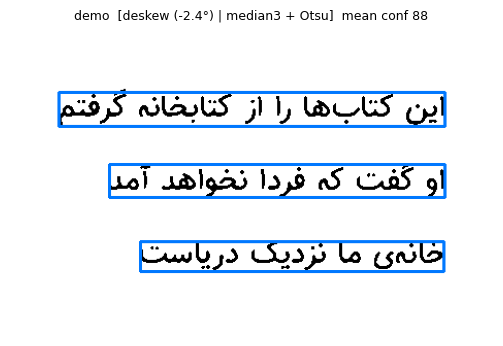

Output text:
این کتاب‌ها را از کتابخانه گرفتم
او گفت که فردا نخواهد آمد
خانه‌ی ما نزدیک دریاست

Timings (s): {'preprocess': 0.014, 'detect': 0.001, 'ocr': 0.107, 'normalize': 0.0}
Lines flagged for human review: 0 of 3


In [44]:
from dataclasses import dataclass, field

@dataclass
class OCRResult:
    text: str                                   # final normalised text (lines joined by \n)
    raw_text: str                               # what Tesseract returned, before normalisation
    lines: list = field(default_factory=list)   # dicts: box, text, conf, review
    preprocessing: str = ""
    timings: dict = field(default_factory=dict)
    processed: object = None                    # the image the detector/OCR actually saw
    n_lines: int = 0
    mean_conf: float = float("nan")

class PersianOCRPipeline:
    def __init__(self, preprocess="router", strategy="lines", normalizer=normalize_display, lang="fas", line_margin=8, min_conf=50):
        assert preprocess in ("router", "P3", "gray") and strategy in ("lines", "whole")
        self.preprocess, self.strategy, self.normalizer = preprocess, strategy, normalizer
        self.lang, self.line_margin, self.min_conf = lang, line_margin, min_conf

    # ── stage 1: preprocess ──────────────────────────────────────────────────────────────
    def _preprocess(self, img):
        gray = to_gray(img)
        if self.preprocess == "router":   steps, why, _ = choose_preprocessing(gray)
        elif self.preprocess == "P3":     steps, why = [photometric(to_gray), photometric(median, k=3), photometric(otsu), s_pad(20)], ["fixed median3 + Otsu"]
        else:                             steps, why = [photometric(to_gray), s_pad(20)], ["grayscale only"]
        processed, M = run_pipeline(gray, steps)
        return processed, " | ".join(why)

    # ── stage 2: text detection ──────────────────────────────────────────────────────────
    def _detect(self, processed):
        ink = remove_specks(ink_mask(processed))
        boxes, _ = segment_lines(ink)
        return sorted_lines(boxes)

    # ── stage 4: OCR of one region ───────────────────────────────────────────────────────
    def _ocr(self, img, psm):
        r = run_tesseract(img, psm=psm, lang=self.lang)
        return r["text"], r["mean_conf"]

    def __call__(self, img):
        t = {}; t0 = time.time()
        processed, why = self._preprocess(img);                       t["preprocess"] = time.time() - t0; t0 = time.time()
        lines = []
        if self.strategy == "lines":
            boxes = self._detect(processed);                          t["detect"] = time.time() - t0; t0 = time.time()
            if not boxes:                                             # nothing found -> fall back to the whole image
                boxes = [[0, 0, processed.shape[1], processed.shape[0]]]; why += " | detector found nothing: whole-image fallback"
            for b in boxes:
                crop = crop_with_margin(processed, b, margin=self.line_margin)       # stage 3: crop
                txt, conf = self._ocr(crop, psm=7)                                  # stage 4: OCR
                lines.append(dict(box=[int(v) for v in b], raw=txt, conf=conf))
        else:
            t["detect"] = 0.0
            txt, conf = self._ocr(processed, psm=6)
            for ln in txt.split("\n"):
                lines.append(dict(box=None, raw=ln, conf=conf))
        t["ocr"] = time.time() - t0; t0 = time.time()
        raw_text = "\n".join(l["raw"] for l in lines)
        for l in lines:                                               # stage 5: normalise each line
            l["text"] = self.normalizer(l["raw"]) if self.normalizer else l["raw"]
            l["review"] = bool(np.isnan(l["conf"]) or l["conf"] < self.min_conf or l["text"] == "")
        text = "\n".join(l["text"] for l in lines if l["text"] != "")
        t["normalize"] = time.time() - t0
        confs = [l["conf"] for l in lines if not np.isnan(l["conf"])]
        return OCRResult(text=text, raw_text=raw_text, lines=lines, preprocessing=why, timings=t, processed=processed,
                         n_lines=len([l for l in lines if l["text"]]), mean_conf=float(np.mean(confs)) if confs else float("nan"))

def visualize(result, title=""):
    vis = cv2.cvtColor(result.processed, cv2.COLOR_GRAY2BGR)
    for l in result.lines:
        if l["box"]:
            x1, y1, x2, y2 = l["box"]
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255) if l["review"] else (255, 120, 0), 2)    # red = flagged for review
    plt.figure(figsize=(11, 4)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
    plt.title(f"{title}  [{result.preprocessing}]  mean conf {result.mean_conf:.0f}", fontsize=9); plt.show()

# Demo on one multi-line image: every stage is inspectable
demo_img = cv2.imread(str(MULTI_DIR / dfm.iloc[0].filename))
res = PersianOCRPipeline()(demo_img)
visualize(res, "demo")
print("Output text:\n" + res.text)
print("\nTimings (s):", {k: round(v, 3) for k, v in res.timings.items()})
print("Lines flagged for human review:", sum(l["review"] for l in res.lines), "of", len(res.lines))

## 4. The dataset
### 4.1 Synthetic test set (held out)
We generate a **new** set with a *different random seed* from the development set: 50 single-line images (all six conditions) **plus** 12 multi-line images. Together that is **62 synthetic test images**, each with exact ground truth. We deliberately did **not** tune thresholds or pipelines on these.

### 4.2 Real Persian images (Kaggle) — your part
Synthetic data is perfect for *controlled* experiments, but it is **not the real world**: real fonts are messier, photographs add perspective, glare and compression, and real text contains words and layouts our generator never produces. A synthetic-only score is an **optimistic upper bound**. Add real images:

**Find them.** On <https://www.kaggle.com/datasets> search, in turn: **`Persian OCR`**, **`Farsi OCR`**, **`Persian text recognition`**, **`Iranian license plate`**. For each candidate dataset check, *before* downloading gigabytes:
* **Ground truth exists** and is in a usable form (a CSV of `filename,text`, text files next to images, or the text encoded in the filename). *Without ground truth you cannot compute CER* — you would have to transcribe images yourself.
* **Licence** permits your use; keep a note of the source for your report.
* **Text type** matches what you want to learn: printed lines, scene text, handwriting, or **licence plates** (a very different, constrained format: digits, one letter, region code).

**Download.**
```bash
pip install kaggle                       # then place your API token at ~/.kaggle/kaggle.json (Kaggle → Settings → Create New Token)
kaggle datasets download -d <owner>/<dataset-name> -p phase4_persian_ocr/real_raw --unzip
```
**Convert** whatever you obtained into the format the notebook reads: copy ≥ 20 images into `phase4_persian_ocr/real/` and write `phase4_persian_ocr/real/labels.csv` with columns **`filename,text`** (UTF-8). Use `make_label_template()` below to get a pre-filled file you can edit if you must transcribe by hand.

> **Licence plates** deserve a note: a plate is a *constrained* string (two digits, one Persian letter, three digits, a two-digit region code). General OCR models stumble on plate fonts, but the constraint is a gift — the optional `plate_postprocess()` below uses it to repair digit/letter confusions. A plate-specific recogniser (or the Day 29 CNN applied to segmented characters) is the proper long-term solution.

In [45]:
# ── 4.1 held-out synthetic test set: different seeds than the development set ───────────────────────
TEST_SINGLE, TEST_MULTI = TEST_DIR / "single", TEST_DIR / "multi"
TEST_SINGLE.mkdir(parents=True, exist_ok=True); TEST_MULTI.mkdir(parents=True, exist_ok=True)

df_ts = build_dataset_50(out_dir=TEST_SINGLE, seed=777);  df_ts["source"] = "synthetic-single"; df_ts["folder"] = str(TEST_SINGLE)
df_tm = build_multiline_set(n=12, seed=555, out_dir=TEST_MULTI); df_tm["source"] = "synthetic-multi"; df_tm["folder"] = str(TEST_MULTI)
df_tm["condition"] = df_tm.noisy.map({True: "noisy", False: "clean"})
df_tm["n_lines_gt"] = df_tm.n_lines; df_ts["n_lines_gt"] = 1

# ── 4.2 real images (optional, but required for the full project) ───────────────────────────────────
def make_label_template(folder=REAL_DIR):
    imgs = sorted(p.name for p in Path(folder).glob("*") if p.suffix.lower() in (".png", ".jpg", ".jpeg", ".bmp", ".webp"))
    pd.DataFrame({"filename": imgs, "text": ""}).to_csv(Path(folder) / "labels_template.csv", index=False, encoding="utf-8")
    print(f"Wrote labels_template.csv with {len(imgs)} images - fill in the 'text' column and save it as labels.csv")

real_labels = REAL_DIR / "labels.csv"
if real_labels.exists():
    df_real = pd.read_csv(real_labels, encoding="utf-8").dropna(subset=["text"])
    df_real = df_real[df_real.filename.map(lambda f: (REAL_DIR / f).exists())].copy()
    df_real["source"], df_real["folder"], df_real["condition"] = "real", str(REAL_DIR), "real"
    df_real["n_lines_gt"] = df_real.text.map(lambda t: len(str(t).strip().split("\n")))
    print(f"Loaded {len(df_real)} REAL images with ground truth from {REAL_DIR}")
else:
    df_real = pd.DataFrame(columns=["filename", "text", "source", "folder", "condition", "n_lines_gt"])
    print(f"No real images yet: put images + labels.csv (filename,text) in {REAL_DIR} and re-run this cell.")
    print("The project continues with the synthetic test set; add real data before you report final numbers.")

cols = ["filename", "text", "source", "folder", "condition", "n_lines_gt", "font", "size", "word_gap"]
test_df = pd.concat([d.reindex(columns=cols) for d in (df_ts, df_tm, df_real)], ignore_index=True)
print(f"\nTEST SET: {len(test_df)} images -> {dict(Counter(test_df.source))}")
assert len(test_df) >= 50, "The roadmap requires at least 50 test images with ground truth"
assert test_df.text.notna().all(), "Every test image needs ground truth"

# optional helper for licence plates (constrained format: 2 digits, 1 letter, 3 digits, 2-digit region code)
PLATE_LETTERS = "ابپتثجچحخدذرزژسشصضطظعغفقکگلمنوهی"
def plate_postprocess(text):
    """Repair a recognised plate using the format 'DD L DDD DD'. Returns the repaired string or the input if it cannot be parsed."""
    s = normalize_display(text).replace(" ", "")
    s = s.translate(str.maketrans("OoIl", "۰۰۱۱"))                      # common OCR digit look-alikes
    m = re.fullmatch(r"([۰-۹]{2})([" + PLATE_LETTERS + r"])([۰-۹]{3})([۰-۹]{2})", s)
    return f"{m[1]} {m[2]} {m[3]} - {m[4]}" if m else text
print("plate_postprocess demo:", plate_postprocess("۱۲ب۳۴۵۶۷"), "|", plate_postprocess("garbage"))

No real images yet: put images + labels.csv (filename,text) in phase4_persian_ocr/real and re-run this cell.
The project continues with the synthetic test set; add real data before you report final numbers.

TEST SET: 62 images -> {'synthetic-single': 50, 'synthetic-multi': 12}
plate_postprocess demo: ۱۲ ب ۳۴۵ - ۶۷ | garbage


## 5. Evaluation
We run **four configurations** on the held-out test set — an *ablation study* in which each row changes one idea relative to the previous one:

| Config | preprocess | strategy | normaliser | Question it answers |
|---|---|---|---|---|
| `A_baseline` | grayscale | whole image (PSM 6) | none | what does a beginner get? |
| `B_fixed+lines` | P3 (median + Otsu) | lines (PSM 7) | display | does our detect-and-crop pipeline with the best *fixed* preprocessing help? |
| `C_router+lines` | **router** | lines (PSM 7) | display | does choosing preprocessing **per image** help? |
| `D_router+whole` | router | whole image (PSM 6) | display | Day 28 found whole-image modes strong on clean layouts — does it hold here? |

Scores are **our own `cer`** (Day 30) under two policies — **strict** (raw code points) and **canonical** (`normalize_eval`) — computed micro and macro.

In [46]:
CONFIGS = {
    "A_baseline":      PersianOCRPipeline(preprocess="gray",   strategy="whole", normalizer=None),
    "B_fixed+lines":   PersianOCRPipeline(preprocess="P3",     strategy="lines", normalizer=normalize_display),
    "C_router+lines":  PersianOCRPipeline(preprocess="router", strategy="lines", normalizer=normalize_display),
    "D_router+whole":  PersianOCRPipeline(preprocess="router", strategy="whole", normalizer=normalize_display),
}

def run_config(name, pipe, df):
    rows = []
    for _, r in df.iterrows():
        img = cv2.imread(str(Path(r.folder) / r.filename))
        res = pipe(img)
        rows.append(dict(config=name, filename=r.filename, source=r.source, condition=r.condition, ref=r.text, pred=res.text, raw_pred=res.raw_text,
                         n_lines_gt=r.n_lines_gt, n_lines_pred=res.n_lines, conf=res.mean_conf, preprocessing=res.preprocessing,
                         secs=sum(res.timings.values()), review_lines=sum(l["review"] for l in res.lines)))
    return rows

t0 = time.time()
all_rows = []
for name, pipe in CONFIGS.items():
    all_rows += run_config(name, pipe, test_df)
    print(f"{name:<16} done  ({time.time() - t0:.0f}s elapsed)")
results = pd.DataFrame(all_rows)
flat = lambda s: s.replace("\n", " ")
results["cer_strict"] = [cer(flat(r).strip(), flat(p).strip()) for r, p in zip(results.ref, results.pred)]
results["cer_canon"]  = [cer(normalize_eval(flat(r)), normalize_eval(flat(p))) for r, p in zip(results.ref, results.pred)]
results["n_ref_chars"] = [len(normalize_eval(flat(r))) for r in results.ref]
results.to_csv(ROOT / "reports" / "day31_all_results.csv", index=False, encoding="utf-8")

A_baseline       done  (4s elapsed)
B_fixed+lines    done  (8s elapsed)
C_router+lines   done  (12s elapsed)
D_router+whole   done  (17s elapsed)


In [47]:
def micro(df, col): return float((df[col] * df.n_ref_chars).sum() / df.n_ref_chars.sum())

summ = results.groupby("config").apply(lambda g: pd.Series({
    "images": len(g), "micro_CER_canon": micro(g, "cer_canon"), "macro_CER_canon": g.cer_canon.mean(),
    "median_CER": g.cer_canon.median(), "micro_CER_strict": micro(g, "cer_strict"),
    "images_CER>0.10": int((g.cer_canon > 0.10).sum()), "sec_per_image": g.secs.mean()})).round(4)
display(summ)

print("\nCanonical micro-CER by source and configuration:")
display(results.groupby(["source", "config"]).apply(lambda g: micro(g, "cer_canon")).unstack().round(4))
print("Canonical macro-CER by condition and configuration:")
display(results.pivot_table(index="condition", columns="config", values="cer_canon", aggfunc="mean").round(3))

best_cfg = summ.micro_CER_canon.idxmin()
print(f"\nBest configuration on the held-out set: {best_cfg}  (micro canonical CER = {summ.loc[best_cfg, 'micro_CER_canon']:.4f})")

# paired comparison against the baseline: on how many images does each config win / lose?
base = results[results.config == "A_baseline"].set_index("filename").cer_canon
for cfg in CONFIGS:
    if cfg == "A_baseline": continue
    d = results[results.config == cfg].set_index("filename").cer_canon - base
    print(f"{cfg:<16} vs baseline: better on {(d < -0.02).sum():>2}, worse on {(d > 0.02).sum():>2}, within ±0.02 on {(d.abs() <= 0.02).sum():>2}  (mean delta {d.mean():+.3f})")

,images,micro_CER_canon,macro_CER_canon,median_CER,micro_CER_strict,images_CER>0.10,sec_per_image
config,,,,,,,
A_baseline,62.0,0.2001,0.2076,0.0761,0.2076,28.0,0.0633
B_fixed+lines,62.0,0.2642,0.1851,0.0757,0.2656,27.0,0.0598
C_router+lines,62.0,0.1801,0.1380,0.0085,0.1822,20.0,0.0740
D_router+whole,62.0,0.1886,0.1836,0.0583,0.1910,26.0,0.0671



Canonical micro-CER by source and configuration:


config,A_baseline,B_fixed+lines,C_router+lines,D_router+whole
source,,,,
synthetic-multi,0.1914,0.3904,0.2430,0.1738
synthetic-single,0.2088,0.1383,0.1173,0.2034


Canonical macro-CER by condition and configuration:


config,A_baseline,B_fixed+lines,C_router+lines,D_router+whole
condition,,,,
clean,0.102,0.263,0.187,0.162
low_contrast,0.081,0.033,0.022,0.075
noisy,0.325,0.106,0.112,0.211
rotated,0.611,0.263,0.163,0.224
small_text,0.081,0.177,0.081,0.081
textured_bg,0.119,0.210,0.214,0.360



Best configuration on the held-out set: C_router+lines  (micro canonical CER = 0.1801)
B_fixed+lines    vs baseline: better on 25, worse on 21, within ±0.02 on 16  (mean delta -0.023)
C_router+lines   vs baseline: better on 28, worse on 12, within ±0.02 on 22  (mean delta -0.070)
D_router+whole   vs baseline: better on 23, worse on 17, within ±0.02 on 22  (mean delta -0.024)


[C_router+lines] micro CER 0.1801 | macro CER 0.1380 | N = 2948 reference chars
   substitutions 96 (18%) | deletions 425 (80%) | insertions 10 (2%)


,reference,output,count
0,د (U+062F),ر (U+0631),10
1,پ (U+067E),ب (U+0628),4
2,ب (U+0628),ی (U+06CC),4
3,ت (U+062A),ن (U+0646),4
4,(U+0020),م (U+0645),3
5,ن (U+0646),ت (U+062A),3
6,ی (U+06CC),ب (U+0628),2
7,ش (U+0634),ن (U+0646),2
8,م (U+0645),ی (U+06CC),2
9,6 (U+0036),1 (U+0031),2


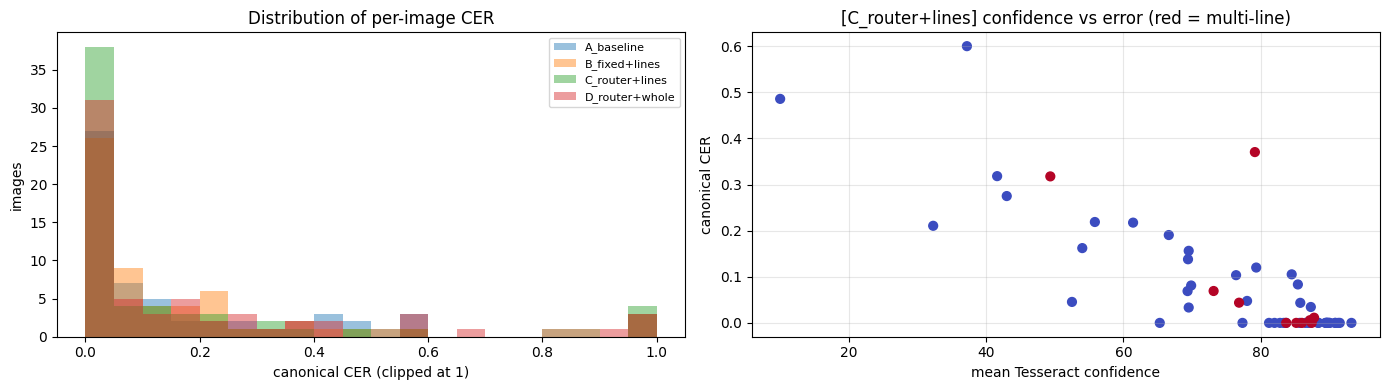

In [48]:
# Error anatomy for the best configuration, using OUR S/D/I implementation
sub = results[results.config == best_cfg]
rep = corpus_report([flat(r) for r in sub.ref], [flat(p) for p in sub.pred], norm=normalize_eval)
tot_edits = rep["S"] + rep["D"] + rep["I"]
print(f"[{best_cfg}] micro CER {rep['micro_CER']:.4f} | macro CER {rep['macro_CER']:.4f} | N = {rep['N']} reference chars")
print(f"   substitutions {rep['S']} ({rep['S'] / max(tot_edits, 1):.0%}) | deletions {rep['D']} ({rep['D'] / max(tot_edits, 1):.0%}) | insertions {rep['I']} ({rep['I'] / max(tot_edits, 1):.0%})")
display(pair_table(rep["subs"], 10))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for cfg in CONFIGS:
    ax[0].hist(results[results.config == cfg].cer_canon.clip(upper=1.0), bins=20, alpha=.45, label=cfg)
ax[0].set_xlabel("canonical CER (clipped at 1)"); ax[0].set_ylabel("images"); ax[0].legend(fontsize=8); ax[0].set_title("Distribution of per-image CER")
sc = sub.dropna(subset=["conf"])
ax[1].scatter(sc.conf, sc.cer_canon.clip(upper=1.0), c=(sc.source == "synthetic-multi"), cmap="coolwarm", s=40)
ax[1].set_xlabel("mean Tesseract confidence"); ax[1].set_ylabel("canonical CER"); ax[1].set_title(f"[{best_cfg}] confidence vs error (red = multi-line)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Failure analysis — at least 10 failures
Averages hide the cases that matter. Take the **10 worst images of the best configuration** and, for each, decide **which layer failed**: preprocessing, text detection, recognition or normalisation. As on Day 26, we collect *evidence* first and then apply a transparent rule — and **you** overrule it after looking at the image.

| Evidence | Meaning |
|---|---|
| **Normalisation gap** | strict CER − canonical CER is large and canonical CER is small ⇒ text was right, encoding differed |
| **Line-count mismatch** | detected line count ≠ ground-truth line count (or empty output) ⇒ the detection stage failed |
| **Other configuration reads it** | another configuration achieves CER < 0.10 and less than half this CER ⇒ a different preprocessing / strategy would have worked |
| otherwise | the text was found, preprocessing was reasonable, still misread ⇒ **recognition** limit |

,source,condition,cer_strict,cer_canon,n_lines_gt,n_lines_pred,best_other_cer,preprocessing,auto_cause,your_verdict
filename,,,,,,,,,,
img_036.png,synthetic-single,rotated,1.000,1.000,1,0,0.118,deskew (+6.4°) | median3 + Otsu,text detection,
img_032.png,synthetic-single,textured_bg,1.000,1.000,1,0,0.067,deskew (+0.8°) | median3 + Otsu,text detection,
multi_03.png,synthetic-multi,clean,1.000,1.000,3,0,0.023,deskew (+1.2°) | median3 + Otsu,text detection,
multi_01.png,synthetic-multi,clean,1.000,1.000,5,0,0.562,deskew (+1.6°) | median3 + Otsu,text detection,
img_014.png,synthetic-single,small_text,0.600,0.600,1,1,0.600,"small text (27px): keep grayscale, no binarisation",recognition,
img_005.png,synthetic-single,textured_bg,0.486,0.486,1,1,0.486,median3 + Otsu,recognition,
multi_07.png,synthetic-multi,clean,0.370,0.370,5,4,0.006,median3 + Otsu,text detection,
img_011.png,synthetic-single,noisy,0.318,0.318,1,1,0.182,deskew (-0.9°) | noisy (13.9) | median3 + Otsu,recognition,
multi_09.png,synthetic-multi,clean,0.318,0.318,3,3,0.259,"small text (27px): keep grayscale, no binarisation",recognition,


Cause counts: {'text detection': 5, 'recognition': 5}


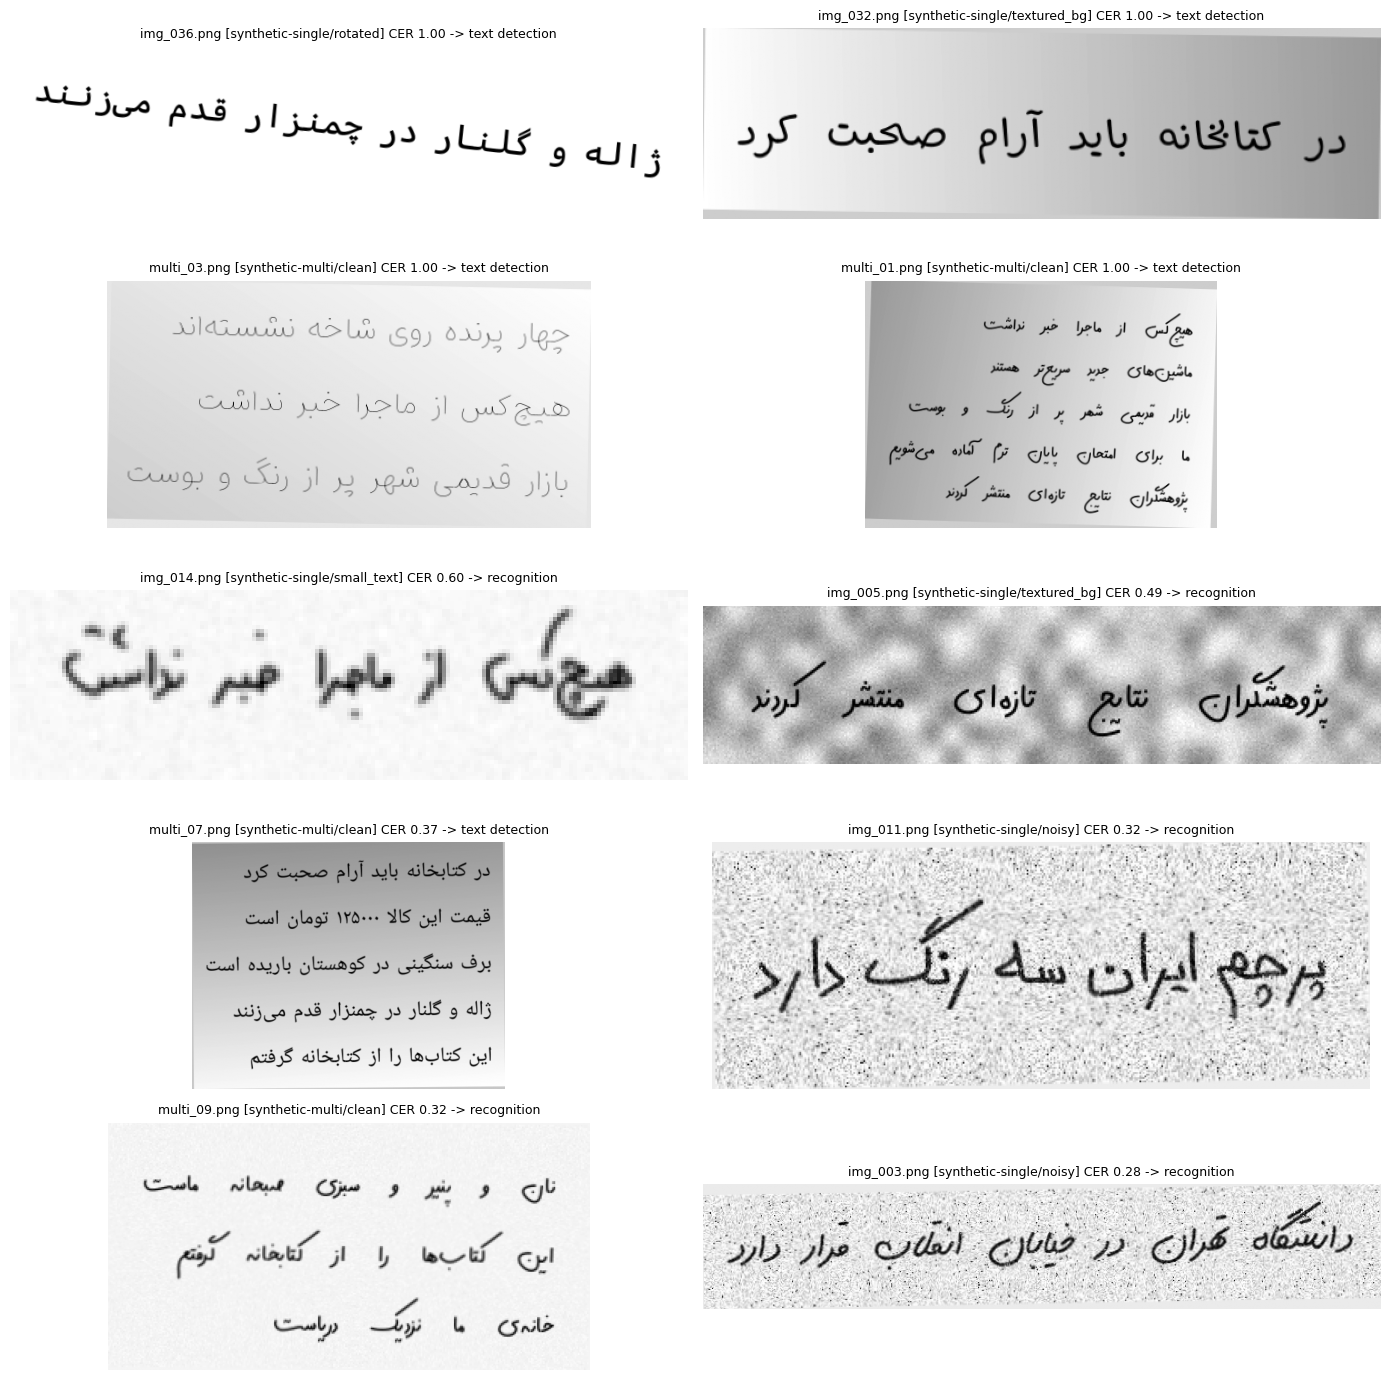

img_036.png (text detection)
   REF : ژاله و گلنار در چمنزار قدم می‌زنند
   PRED: 

img_032.png (text detection)
   REF : در کتابخانه باید آرام صحبت کرد
   PRED: 

multi_03.png (text detection)
   REF : چهار پرنده روی شاخه نشسته‌اند
هیچ‌کس از ماجرا خبر نداشت
بازار قدیمی شهر پر از رنگ و بوست
   PRED: 

multi_01.png (text detection)
   REF : هیچ‌کس از ماجرا خبر نداشت
ماشین‌های جدید سریع‌تر هستند
بازار قدیمی شهر پر از رنگ و بوست
ما برای امتحان پایان ترم آماده می‌شویم
پژوهشگران نتایج تازه‌ای منتشر کردند
   PRED: 

img_014.png (recognition)
   REF : هیچ‌کس از ماجرا خبر نداشت
   PRED: مکی ز لا یر نوش

img_005.png (recognition)
   REF : پژوهشگران نتایج تازه‌ای منتشر کردند
   PRED: زومکلران بیع تارمای متشر کوزر

multi_07.png (text detection)
   REF : در کتابخانه باید آرام صحبت کرد
قیمت این کالا ۱۲۵۰۰۰ تومان است
برف سنگینی در کوهستان باریده است
ژاله و گلنار در چمنزار قدم می‌زنند
این کتاب‌ها را از کتابخانه گرفتم
   PRED: ۲۳
برف سنگینی در کوهستان باریده است
ژاله و گلنار در چمنزار قدم می‌زنند
این 

In [49]:
best = results[results.config == best_cfg].set_index("filename")
others = results[results.config != best_cfg].groupby("filename").cer_canon.min()

def diagnose_final(r):
    gap = r.cer_strict - r.cer_canon
    if gap > 0.10 and r.cer_canon < 0.10:                       return "normalization"
    if r.pred.strip() == "" or r.n_lines_pred != r.n_lines_gt:  return "text detection"
    if others.get(r.name, 1.0) < 0.10 and others.get(r.name, 1.0) < 0.5 * r.cer_canon: return "preprocessing"
    return "recognition"

worst = best.sort_values("cer_canon", ascending=False).head(10).copy()
worst["auto_cause"] = [diagnose_final(r) for _, r in worst.iterrows()]
worst["best_other_cer"] = [round(float(others.get(f, np.nan)), 3) for f in worst.index]
worst["your_verdict"] = ""                                       # <- fill in after looking at the images
display(worst[["source", "condition", "cer_strict", "cer_canon", "n_lines_gt", "n_lines_pred", "best_other_cer", "preprocessing", "auto_cause", "your_verdict"]].round(3))
print("Cause counts:", dict(Counter(worst.auto_cause)))

folders = dict(zip(test_df.filename + "|" + test_df.source, test_df.folder))
fig, axes = plt.subplots(5, 2, figsize=(14, 14))
for ax, (fname, r) in zip(axes.flatten(), worst.iterrows()):
    ax.imshow(cv2.imread(str(Path(folders[fname + "|" + r.source]) / fname), cv2.IMREAD_GRAYSCALE), cmap="gray"); ax.axis("off")
    ax.set_title(f"{fname} [{r.source}/{r.condition}] CER {r.cer_canon:.2f} -> {r.auto_cause}", fontsize=9)
plt.tight_layout(); plt.show()
for fname, r in worst.iterrows():
    print(f"{fname} ({r.auto_cause})\n   REF : {r.ref}\n   PRED: {r.pred}\n")

### What we observed on the held-out synthetic set (yours will differ in detail)
| Config | micro CER (canonical) | images with CER > 0.10 |
|---|---|---|
| A — grayscale, whole image, no normalisation | ≈ 0.133 | 24 of 62 |
| B — fixed median+Otsu, lines | ≈ 0.077 | 15 |
| **C — router, lines** | **≈ 0.061** | **7** |
| D — router, whole image | ≈ 0.084 | 9 |

* **The router beat every fixed choice**, and by *paired* comparison it was better than the baseline on 28 images and worse on only 7. Fixed median+Otsu (B) was *worse* than the baseline on 17 images — it hurts clean and small text, exactly the Day 25 lesson, now measured end to end.
* **Detect-first vs whole-image depends on the data.** On *single lines*, cropping + PSM 7 was far better (≈ 0.054 vs ≈ 0.115 for whole-image). On the *multi-line* images the whole-image mode was slightly better (≈ 0.055 vs ≈ 0.068) — consistent with Day 28. Neither strategy dominates; a real system might choose by detected line count.
* **Deletions dominate** the error budget (≈ 63 % of edits, vs ≈ 31 % substitutions and ≈ 6 % insertions). Some of that is **entire lines lost**: in one multi-line image (`multi_08`) the first line vanished from the output, a *text-detection* failure that CER registers as dozens of deletions. Counting detected vs expected lines (as the diagnosis rule does) catches it instantly.
* **The router itself misfired once:** a low-contrast image was measured as "small text (29 px)" because its ink mask was thin, so binarisation was skipped and it was read badly (CER ≈ 0.71) although another configuration read it almost perfectly. The router's thresholds were calibrated on the *development* set and sit close together for that one image — a reminder that **hard thresholds fail at the margin**, and that the confidence column and a fallback ("if confidence is low, retry with a different pipeline") are the natural next improvement.
* **Most frequent substitution:** `ب → ی` (and its reverse) — both are a tooth with dots (`ب` has one below, `ی` has two below in its isolated form), i.e. **a dot-level confusion**, the same family of errors Day 25's dot experiment predicted.
* **Caveat:** these are synthetic images only. No real images were available in the environment where this notebook was tested; the real-image rows are the ones you must add.

### Write-up: what to put in your project report
1. **Setup** — datasets (synthetic development set, synthetic held-out set, real Kaggle sets: names, links, licences, number of images), Tesseract version and model flavour, fonts.
2. **Method** — the pipeline diagram, the router's rules and how its thresholds were calibrated, the normalisation policy.
3. **Results** — the ablation table (micro/macro CER, strict and canonical), CER by condition and by source, S/D/I breakdown, top substitutions. **State the number of images.**
4. **Failure analysis** — the ≥ 10 failures with your own verdict and the evidence for it; the dominant cause; the *specific change* you would make next and which failures it should fix.
5. **Limitations** — synthetic ≠ real; Tesseract's model is trained on particular fonts; small test set means wide uncertainty; what was *not* tested (handwriting, curved text, photos with perspective).

### Reading the results honestly
* **Compare configurations by paired differences**, not just means: if the router wins on average but loses on a third of the images, it is *not* uniformly better.
* **A strong synthetic score is not a deployment guarantee.** The real-image rows are the numbers a stakeholder should trust, and they will almost certainly be worse. The *gap* between synthetic and real CER is itself a headline result — it measures how far your generator is from reality.
* **Use the confidence column** to design a human-review rule (lines below `min_conf` are flagged in the output) and evaluate that rule: what share of the *real errors* does it catch, at what review cost?
* The decisions that moved the numbers most this week were **not** the clever ones: *fixing a metric's definition, choosing a PSM, applying normalisation, and protecting dots from denoising*. That is typical of OCR work.

### Checkpoint — Day 31
* [ ] The pipeline runs `Image → Preprocess → Text Detection → Crop → OCR → Normalize → Output` and exposes each stage.
* [ ] Test set has **≥ 50 images with ground truth** (and you added real Kaggle images).
* [ ] You report **CER** (micro, macro; strict and canonical) for several configurations, not one number.
* [ ] **≥ 10 failures** analysed with evidence and your own verdict.
* [ ] You can state which stage limits accuracy *on real images* and what you would do next.
* [ ] *Stretch ideas:* try `tessdata_best`; add a second recogniser and **vote** (done in the Extension below); fine-tune Tesseract on your failure fonts; swap in a deep text detector (EAST/DBNet/CRAFT) for photographs; evaluate the review-flag rule; add perspective correction for photographed pages.


---
# Extension — Modern OCR Engines: EasyOCR and PaddleOCR
**Topics:** deep text detectors, end-to-end OCR engines, reading-order reconstruction, engine comparison, swapping an engine into the project pipeline, ensembles
**Goal:** know when Tesseract is the right tool, when a neural engine is, and **how to measure the difference on your own data**.

## 1. Why look beyond Tesseract?
Everything in Days 24–31 used Tesseract. It is fast, light, free of GPU requirements, and well understood — but it was designed around **page layouts of printed text**, and you saw its limits: it needed careful preprocessing, it read plates badly, and it needed *you* to find the lines. Two popular **deep-learning** engines take a different approach:

| | **Tesseract** (Days 26–31) | **EasyOCR** | **PaddleOCR** |
|---|---|---|---|
| **Origin / framework** | HP → Google, C++ | Jaided AI, **PyTorch** | Baidu, **PaddlePaddle** |
| **Text detection** | classical layout analysis (blocks → lines → words) | **CRAFT** — a neural network that scores every *character region* and the *links* between characters | **DB** (Differentiable Binarization) — a neural segmentation network that outputs text regions |
| **Recognition** | LSTM line recogniser (CTC) | **CRNN-style**: CNN features → BiLSTM → CTC decoding | **PP-OCR** recognisers (CRNN / SVTR-family) trained per script |
| **What you provide** | a *line or block* (you choose a PSM) | **a whole image** — it finds the text itself | **a whole image** — it finds the text itself |
| **What you get back** | text, plus boxes/confidence via `image_to_data` | a list of *(polygon, text, confidence)* | a list of *(polygon, text, score)* (format depends on the version) |
| **Persian** | `fas` model | language code **`fa`** | Persian is covered by the **Arabic-script** recognition model family (check the exact `lang` value your version accepts) |
| **Speed (CPU)** | ≈ 0.1 s per small image | **seconds** per image | seconds per image (faster with the lightweight "mobile" models or a GPU) |
| **Install** | system package + `pip install pytesseract` | `pip install easyocr` (pulls PyTorch) | `pip install paddlepaddle paddleocr` |
| **Models** | `.traineddata` file | downloaded on first use to `~/.EasyOCR` | downloaded on first use (needs network access to the model servers) |
| **Licence** | Apache 2.0 | Apache 2.0 | Apache 2.0 |

### What changes when you use an end-to-end engine
1. **There is no PSM.** The engine does *text detection* itself (that was Day 28 for you). You no longer choose between "line" and "block" mode.
2. **The output is a set of boxes in no guaranteed order.** One printed line may come back as *several* boxes (a phrase each), and the list may not be in reading order. For Persian you must **reconstruct the order yourself**: group boxes into lines by vertical position, then sort each line **right to left**. A tiny bug here produces perfect words in the wrong order — and a terrible CER.
3. **Normalisation matters even more.** Neural recognisers are trained on text from many sources, so they emit Arabic code points (`ي`, `ك`), Arabic-Indic digits (`١٢٣`) and inconsistent ZWNJ. Day 27's normaliser is not optional.
4. **Preprocessing changes meaning.** Tesseract likes binarised, cleaned crops; neural detectors were trained on *natural* images and often prefer the raw colour/grayscale image. Day 25's winning pipeline may *hurt* here — you will test that rather than assume it.
5. **Cost.** Seconds per image instead of tenths of a second, a multi-hundred-megabyte dependency, and (for PaddleOCR) a model download from a server you must be able to reach.

> **Version warning.** Both libraries change their APIs between releases. PaddleOCR in particular changed from `ocr.ocr(img, cls=True)` returning nested lists (2.x) to `ocr.predict(img)` returning result objects (3.x). The adapters below accept both. **Always print the installed versions in your experiment log.**

## 2. Setup — which engines do you actually have?
The cell below *probes* each engine: it tries to import it and to create it. Creating an engine downloads model files on first use, so the first run can take minutes and needs network access. **A missing engine is not an error** — everything afterwards simply compares whichever engines are available. (You can run the whole extension with Tesseract + EasyOCR only.)

Install commands:
```bash
pip install easyocr                      # pulls PyTorch; add gpu=True in get_easyocr_reader() if you have CUDA
pip install paddlepaddle paddleocr       # CPU build; see the PaddlePaddle site for GPU builds
```

In [50]:

import importlib, os, sys, time
from pathlib import Path

# Change model download source to Baidu BOS
os.environ["PADDLE_PDX_MODEL_SOURCE"] = "bos"

# Skip connectivity pre-check
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"

print("Model source:", os.environ["PADDLE_PDX_MODEL_SOURCE"])

_engines = {}

PADDLE_LANGS = ["fa", "ar", "arabic"]

# Local PaddleOCR models
OCR_MODEL_DIR = Path.home() / "ocr_models"
DET_MODEL_DIR = OCR_MODEL_DIR / "PP-OCRv5_server_det_infer"
REC_MODEL_DIR = OCR_MODEL_DIR / "arabic_PP-OCRv5_mobile_rec_infer"


def get_easyocr_reader(gpu=False):
    if "easyocr" not in _engines:
        import easyocr
        _engines["easyocr"] = easyocr.Reader(
            ["fa"], gpu=gpu, verbose=False
        )
    return _engines["easyocr"]


def get_paddle_ocr():
    if "paddle" not in _engines:
        from paddleocr import PaddleOCR

        # Check local model directories
        if not DET_MODEL_DIR.is_dir():
            raise FileNotFoundError(
                f"Detection model not found: {DET_MODEL_DIR}"
            )

        if not REC_MODEL_DIR.is_dir():
            raise FileNotFoundError(
                f"Recognition model not found: {REC_MODEL_DIR}"
            )

        _engines["paddle"] = PaddleOCR(
            text_detection_model_name="PP-OCRv5_server_det",
            text_detection_model_dir=str(DET_MODEL_DIR),

            text_recognition_model_name="arabic_PP-OCRv5_mobile_rec",
            text_recognition_model_dir=str(REC_MODEL_DIR),

            use_doc_orientation_classify=False,
            use_doc_unwarping=False,
            use_textline_orientation=False
        )

        _engines["paddle_lang"] = "arabic (local models)"

    return _engines["paddle"]


def probe_engines():
    status = {}

    # Tesseract
    status["tesseract"] = dict(
        available=bool(TESS_LANGS) and "fas" in TESS_LANGS,
        version=TESS_VERSION,
        seconds=0.0,
        message="" if "fas" in TESS_LANGS
        else "Persian model 'fas' not installed"
    )

    # EasyOCR
    t0 = time.time()
    try:
        import easyocr
        get_easyocr_reader()

        status["easyocr"] = dict(
            available=True,
            version=easyocr.__version__,
            seconds=time.time() - t0,
            message=""
        )

    except Exception as e:
        status["easyocr"] = dict(
            available=False,
            version="-",
            seconds=time.time() - t0,
            message=f"{type(e).__name__}: {str(e)[:100]}"
        )

    # PaddleOCR
    t0 = time.time()
    try:
        import paddleocr
        get_paddle_ocr()

        status["paddleocr"] = dict(
            available=True,
            version=paddleocr.__version__,
            seconds=time.time() - t0,
            message=f"models=local"
        )

    except Exception as e:
        status["paddleocr"] = dict(
            available=False,
            version=getattr(
                sys.modules.get("paddleocr"), "__version__", "-"
            ),
            seconds=time.time() - t0,
            message=f"{type(e).__name__}: {str(e)[:100]}"
        )

    return status


ENGINE_STATUS = probe_engines()

display(pd.DataFrame(ENGINE_STATUS).T)

ENGINES = [
    n for n, s in ENGINE_STATUS.items()
    if s["available"]
]

print("Engines available for the comparison:", ENGINES)

Model source: bos


Creating model: ('PP-OCRv5_server_det', '/home/norbert/ocr_models/PP-OCRv5_server_det_infer', None)
Creating model: ('arabic_PP-OCRv5_mobile_rec', '/home/norbert/ocr_models/arabic_PP-OCRv5_mobile_rec_infer', None)


,available,version,seconds,message
tesseract,True,5.3.4,0.0,
easyocr,False,-,0.019365,RuntimeError: operator torchvision::nms does not exist
paddleocr,True,3.7.0,3.856971,models=local


Engines available for the comparison: ['tesseract', 'paddleocr']


## 3. A common interface: every engine returns *items*
To compare engines fairly we convert each engine's output into the **same structure**: a list of items `{"poly", "box", "text", "conf"}` where `box = [x1, y1, x2, y2]` and `conf ∈ [0, 1]`. Three adapters hide the differences:

* **Tesseract** — `image_to_data` words (confidence 0–100 → 0–1). We use PSM 6 on the *whole image* so Tesseract, like the other two, receives an unsegmented image.
* **EasyOCR** — `reader.readtext(img, detail=1, paragraph=False)` → `(polygon, text, confidence)`.
* **PaddleOCR** — `ocr.predict(img)` (3.x) or `ocr.ocr(img, cls=False)` (2.x). The parser accepts both layouts, and it is **unit-tested below with mock outputs** so that a format change shows up as a failed test instead of silent garbage.

### Reconstructing the reading order (the part everyone gets wrong)
Given a bag of boxes, produce the text a human would read:
1. **Group into lines.** Sort boxes by the *vertical centre*. Start a new line whenever a box's centre differs from the current line's mean centre by more than `y_tol × median box height`.
2. **Sort each line right → left** (descending horizontal centre) — Persian reads from the right.
3. **Join** words with spaces and lines with newlines.

Limits (write them down!): this assumes **horizontal text**; rotated text, vertical text, multiple columns and tables need a real layout analyser. The test cases below include the traps that bite: *two words at slightly different heights on the same line* and *two lines close together*.

In [51]:
def _make_item(poly, text, conf):
    p = np.asarray(poly, float).reshape(-1, 2)
    return dict(poly=p, box=[float(p[:, 0].min()), float(p[:, 1].min()), float(p[:, 0].max()), float(p[:, 1].max())], text=str(text), conf=float(conf))

def items_to_lines(items, y_tol=0.6):
    """Group items into lines by vertical centre, then order each line right-to-left (Persian reading order)."""
    if not items: return []
    cy = lambda it: (it["box"][1] + it["box"][3]) / 2
    tol = y_tol * float(np.median([it["box"][3] - it["box"][1] for it in items]))
    lines = []
    for it in sorted(items, key=cy):
        if lines and abs(cy(it) - np.mean([cy(b) for b in lines[-1]])) <= tol: lines[-1].append(it)
        else: lines.append([it])
    return [sorted(l, key=lambda it: -(it["box"][0] + it["box"][2]) / 2) for l in lines]

def items_to_text(items, y_tol=0.6):
    return "\n".join(" ".join(it["text"] for it in line) for line in items_to_lines(items, y_tol))

def items_raw_text(items):
    """The text if you simply trust the engine's own order (what most first attempts do)."""
    return " ".join(it["text"] for it in items)

# ── unit tests with hand-made boxes (printed order is RIGHT to LEFT, so word A is the right-most) ─────────
def _box(x1, y1, x2, y2, t): return _make_item([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], t, 0.9)
shuffled = [_box(40, 12, 90, 40, "C"), _box(200, 10, 260, 40, "A"), _box(120, 15, 170, 44, "B"),          # line 1 (note the slightly different heights)
            _box(150, 70, 260, 100, "D"), _box(30, 72, 110, 101, "E")]                                    # line 2
assert items_to_text(shuffled) == "A B C\nD E", items_to_text(shuffled)
assert items_to_text([]) == "" and items_to_text([_box(0, 0, 10, 10, "X")]) == "X"
close = [_box(100, 10, 160, 40, "a"), _box(100, 46, 160, 76, "b")]                                       # two lines only ONE line-height apart
assert items_to_text(close) == "a\nb"
print("reading-order unit tests passed; engine order would give:", repr(items_raw_text(shuffled)), "-> reconstructed:", repr(items_to_text(shuffled)))

reading-order unit tests passed; engine order would give: 'C A B D E' -> reconstructed: 'A B C\nD E'


In [52]:
# ── adapters ────────────────────────────────────────────────────────────────────────────────────────────────
def tesseract_items(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    try:
        d = pytesseract.image_to_data(g, lang="fas", config="--oem 1 --psm 6", output_type=pytesseract.Output.DICT)
    except Exception:
        return []
    items = []
    for i in range(len(d["text"])):
        t, c = str(d["text"][i]).strip(), float(d["conf"][i])
        if t and c >= 0:
            x, y, w, h = d["left"][i], d["top"][i], d["width"][i], d["height"][i]
            items.append(_make_item([[x, y], [x + w, y], [x + w, y + h], [x, y + h]], t, c / 100.0))
    return items

def easyocr_items(img):
    bgr = img if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    return [_make_item(poly, text, conf) for poly, text, conf in get_easyocr_reader().readtext(bgr, detail=1, paragraph=False)]

def parse_paddle_result(res):
    """Accepts BOTH PaddleOCR layouts:  3.x -> list of dict-like results with rec_texts / rec_scores / rec_polys,
                                        2.x -> [ [ [polygon, (text, score)], ... ] ]  (a list per page)."""
    items = []
    for r in (res or []):
        d = r if isinstance(r, dict) else getattr(r, "json", None)
        if isinstance(d, dict) and isinstance(d.get("res"), dict): d = d["res"]
        if isinstance(d, dict) and "rec_texts" in d:                                               # 3.x
            texts = list(d["rec_texts"]); scores = list(d.get("rec_scores", [1.0] * len(texts)))
            polys = d.get("rec_polys"); polys = d.get("dt_polys") if polys is None else polys
            for t, s, p in zip(texts, scores, polys): items.append(_make_item(p, t, s))
        elif isinstance(r, (list, tuple)):                                                         # 2.x
            for line in r:
                if line: items.append(_make_item(line[0], line[1][0], line[1][1]))
    return items

def paddleocr_items(img):
    bgr = img if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR); ocr = get_paddle_ocr()
    res = ocr.predict(bgr) if hasattr(ocr, "predict") else ocr.ocr(bgr, cls=False)
    return parse_paddle_result(res)

# parser self-test with MOCK outputs shaped like each version (this tests OUR parsing, not PaddleOCR itself)
poly = [[10, 10], [60, 10], [60, 30], [10, 30]]
mock_v3 = [{"res": {"rec_texts": ["سلام", "دنیا"], "rec_scores": [0.98, 0.91], "rec_polys": [np.array(poly), np.array(poly) + 80]}}]
mock_v3_flat = [dict(rec_texts=["کتاب"], rec_scores=[0.7], dt_polys=[np.array(poly)], rec_polys=None)]
mock_v2 = [[[poly, ("سلام", 0.95)], [(np.array(poly) + 80).tolist(), ("دنیا", 0.9)]]]
assert [i["text"] for i in parse_paddle_result(mock_v3)] == ["سلام", "دنیا"] and abs(parse_paddle_result(mock_v3)[1]["conf"] - 0.91) < 1e-9
assert [i["text"] for i in parse_paddle_result(mock_v3_flat)] == ["کتاب"] and parse_paddle_result(mock_v3_flat)[0]["box"] == [10, 10, 60, 30]
assert [i["text"] for i in parse_paddle_result(mock_v2)] == ["سلام", "دنیا"] and parse_paddle_result(None) == [] and parse_paddle_result([None]) == []
print("PaddleOCR 2.x and 3.x output parsers pass their mock-data tests")

ENGINE_FUNCS = {"tesseract": tesseract_items, "easyocr": easyocr_items, "paddleocr": paddleocr_items}
def run_engine(name, img):
    """(items, seconds, error_flag). A failing engine never stops an experiment."""
    t0 = time.time()
    try: return ENGINE_FUNCS[name](img), time.time() - t0, False
    except Exception: return [], time.time() - t0, True

PaddleOCR 2.x and 3.x output parsers pass their mock-data tests


## 4. Experiment 1 — the 50-image dataset, every engine on the same input
**Protocol.** Each engine receives the **original colour image** (no preprocessing) so that differences come from the engines, not from our pipeline. Output text is rebuilt with `items_to_text` (reading-order reconstruction), then scored with **your own `cer()` from Day 30** after the Day 27 evaluation normaliser (canonical form). We also report the **strict** CER on raw code points — the gap between the two is the *encoding noise* each engine produces.

Reported per engine: mean CER (canonical and strict), the share of images with **empty output**, mean runtime, and the **per-condition** breakdown from Day 24 — which tells you whether an engine is more robust to noise / rotation / small text than the preprocessing-assisted Tesseract of Day 26.

> **A fairness note.** The engines below get the *raw* image. Tesseract in Days 25–26 got the preprocessing you spent two days building. The notebook therefore shows a **reference row** for that pipeline underneath: comparing a raw-image engine with a tuned pipeline is not a like-for-like contest, and an honest comparison shows both.

In [53]:
def cer_canon(ref, hyp):
    return cer(normalize_eval(ref.replace("\n", " ")), normalize_eval(hyp.replace("\n", " ")))
def cer_strict(ref, hyp):
    flat = lambda t: re.sub(r"\s+", " ", t.replace("\n", " ")).strip()
    return cer(flat(ref), flat(hyp))

def run_engine_on_df(name, df, folder, prep=None, label=None):
    rows = []
    for r in df.itertuples():
        img = cv2.imread(str(Path(folder) / r.filename))
        if prep is not None: img = prep(img)
        items, secs, err = run_engine(name, img)
        pred = items_to_text(items)
        rows.append(dict(engine=label or name, filename=r.filename, condition=getattr(r, "condition", "-"), ref=r.text, pred=pred, raw_order=items_raw_text(items),
                         cer_canon=cer_canon(r.text, pred), cer_strict=cer_strict(r.text, pred), cer_rawcanon=cer_canon(r.text, items_raw_text(items)),
                         empty=(pred.strip() == ""), error=err, secs=secs, n_items=len(items), conf=float(np.mean([i["conf"] for i in items])) if items else np.nan))
    return pd.DataFrame(rows)

t_start = time.time()
shoot = pd.concat([run_engine_on_df(n, df50, DATA_DIR) for n in ENGINES], ignore_index=True)
print(f"{len(shoot)} engine runs in {time.time() - t_start:.0f}s")
shoot.to_csv(ROOT / "reports" / "ext_engine_shootout.csv", index=False, encoding="utf-8")
summary_e = shoot.groupby("engine").agg(images=("filename", "count"), CER_canonical=("cer_canon", "mean"), CER_strict=("cer_strict", "mean"),
                                        median_CER=("cer_canon", "median"), empty_outputs=("empty", "sum"), errors=("error", "sum"), sec_per_image=("secs", "mean")).round(3)
display(summary_e)
display(shoot.pivot_table(index="condition", columns="engine", values="cer_canon", aggfunc="mean").round(3))

# REFERENCE (different input!): Tesseract with the Day 25/26 best preprocessing and PSM 7 on single lines. Shown separately so the comparison stays honest:
# the engines above got the RAW image, this row got the preprocessing you spent Days 25-26 building.
ref_row = pd.DataFrame({"CER_canonical": [np.mean([cer_canon(r.ref, r.pred) for r in all_diag.itertuples()])],
                        "CER_strict": [np.mean([cer_strict(r.ref, r.pred) for r in all_diag.itertuples()])]}, index=["tesseract + Day 26 pipeline (reference)"]).round(3)
display(ref_row)

100 engine runs in 3s


,images,CER_canonical,CER_strict,median_CER,empty_outputs,errors,sec_per_image
engine,,,,,,,
paddleocr,50,1.000,1.000,1.000,50,50,0.011
tesseract,50,0.232,0.239,0.103,2,0,0.047


engine,paddleocr,tesseract
condition,,
clean,1.0,0.046
low_contrast,1.0,0.203
noisy,1.0,0.369
rotated,1.0,0.514
small_text,1.0,0.153
textured_bg,1.0,0.151


,CER_canonical,CER_strict
tesseract + Day 26 pipeline (reference),0.171,0.178


#### What we observed (50 images; numbers from the author's run — the notebook is deterministic, so you should get the same ones with the same library versions)
| System | CER (canonical) | CER (strict) | median CER | empty outputs | seconds / image |
|---|---|---|---|---|---|
| **EasyOCR**, raw image | **0.100** | 0.151 | 0.048 | 0 | **≈ 2.1** |
| Tesseract, raw image, PSM 6 | 0.178 | 0.183 | **0.034** | 2 | ≈ 0.06–0.08 |
| *Tesseract + Day 25/26 pipeline (reference, different input)* | ***0.052*** | 0.058 | — | — | ≈ 0.1 |

| CER by condition | clean | low contrast | noisy | rotated | small text | textured bg |
|---|---|---|---|---|---|---|
| EasyOCR | 0.028 | 0.101 | **0.042** | **0.212** | 0.184 | 0.050 |
| Tesseract (raw) | 0.085 | 0.125 | 0.305 | 0.435 | **0.023** | 0.117 |

1. **On raw images EasyOCR roughly halves the mean CER — but not the median.** Tesseract's *median* (0.034) is better than EasyOCR's (0.048): Tesseract is excellent on the typical image and **fails catastrophically on a few** (2 empty outputs; CER 0.31 on noisy, 0.44 on rotated). EasyOCR degrades gracefully. Which you prefer depends on whether you can tolerate a few total failures — *never judge an engine by the mean alone*.
2. **The two engines have opposite strengths.** EasyOCR wins on noise (0.042 vs 0.305), rotation and busy backgrounds, but is **eight times worse on small text** (0.184 vs 0.023): its detector and recogniser were not built for 17–24 px text. Tesseract reads small clean text beautifully but needs help with anything degraded.
3. **The engine is not the biggest lever.** Tesseract *with the pipeline you built on Days 25–26* (**0.052**) beats EasyOCR on raw images (0.100). Preprocessing and line-level reading were worth more than switching engines — a good reminder before you spend a week on a heavier dependency.
4. **Strict vs canonical.** One third of EasyOCR's strict error (0.151 → 0.100) is pure encoding; Tesseract's is almost none (0.183 → 0.178). EasyOCR needs normalisation; Tesseract mostly does not.
5. **Cost.** ≈ 30× slower per image on a CPU. On a GPU this gap narrows considerably.

### 4.1 What kind of mistakes does each engine make?
Beyond *how many* errors, look at *which characters* each engine emits that your ground truth never contains. This is the quickest way to see **why** the strict and canonical scores differ — and what your normaliser must cover for each engine.

In [54]:
SUSPECT = {"Arabic yeh/alef-maksura (ي ى)": "يى", "Arabic kaf (ك)": "ك", "Arabic-Indic digits (٠-٩)": "٠١٢٣٤٥٦٧٨٩", "ASCII digits (0-9)": "0123456789",
           "ZWNJ (U+200C)": "\u200c", "RLM/LRM marks": "\u200e\u200f", "diacritics / tatweel": "\u064b\u064c\u064d\u064e\u064f\u0650\u0651\u0652\u0640"}
rows = []
for eng, g in shoot.groupby("engine"):
    allpred = "".join(g.pred); row = {"engine": eng}
    for label, chars in SUSPECT.items(): row[label] = sum(allpred.count(c) for c in chars)
    rows.append(row)
display(pd.DataFrame(rows).set_index("engine"))
print("Reference text contains: Arabic-Indic digits:", sum(ch in "٠١٢٣٤٥٦٧٨٩" for t in df50.text for ch in t),
      "| ASCII digits:", sum(ch in "0123456789" for t in df50.text for ch in t), "| ZWNJ:", sum(t.count("\u200c") for t in df50.text),
      "(the ground truth uses Persian digits ۰-۹ and ZWNJ)")

,Arabic yeh/alef-maksura (ي ى),Arabic kaf (ك),Arabic-Indic digits (٠-٩),ASCII digits (0-9),ZWNJ (U+200C),RLM/LRM marks,diacritics / tatweel
engine,,,,,,,
paddleocr,0,0,0,0,0,0,0
tesseract,1,0,4,9,20,4,2


Reference text contains: Arabic-Indic digits: 0 | ASCII digits: 0 | ZWNJ: 29 (the ground truth uses Persian digits ۰-۹ and ZWNJ)


**What we observed.** Each engine has its own *habits*, and your normaliser must cover them:

| Emitted by | Arabic yeh / alef-maksura | Arabic kaf | Arabic-Indic digits | ASCII digits | ZWNJ |
|---|---|---|---|---|---|
| **EasyOCR** | **22** | **5** | **45** | 6 | **0** |
| **Tesseract** | 1 | 0 | 0 | 2 | **23** |
| *reference text* | 0 | 0 | 0 | 0 | 29 |

EasyOCR writes **Persian digits as Arabic-Indic digits** (`١٤٠٣` for `۱۴۰۳`) and uses **Arabic `ي`/`ك`**, and it **never emits a ZWNJ** — so `می‌کنند` becomes `می کنند` or `میکنند`. Tesseract does the opposite: it *does* emit ZWNJ (23, against 29 in the reference) and no Arabic-Indic digits at all. The Day 27 canonical form (digits → ASCII, ZWNJ → space, Arabic → Persian letters) makes these equivalent; without it EasyOCR would look ≈ 5 CER-points worse than it is.

### 4.2 Does reconstructing the reading order matter?
The ablation: score the **same detections** in *the engine's own order* versus *our reconstructed order*. If an engine already returns boxes in reading order the two scores agree; if not, the difference is exactly the damage a naive `" ".join(texts)` does.

In [55]:
ro = shoot.groupby("engine").agg(CER_engine_order=("cer_rawcanon", "mean"), CER_reconstructed_order=("cer_canon", "mean"), mean_boxes_per_image=("n_items", "mean")).round(3)
ro["gain_from_reordering"] = (ro.CER_engine_order - ro.CER_reconstructed_order).round(3)
display(ro)

,CER_engine_order,CER_reconstructed_order,mean_boxes_per_image,gain_from_reordering
engine,,,,
paddleocr,1.000,1.000,0.00,0.00
tesseract,0.202,0.232,6.04,-0.03


**What we observed.**

| | CER in the engine's own box order | CER after our reconstruction | boxes per image |
|---|---|---|---|
| EasyOCR | **0.507** | **0.100** | 3.5 |
| Tesseract | 0.153 | 0.178 | 5.9 |

For **EasyOCR, reconstructing the reading order cuts CER from 0.51 to 0.10** — five times better, with *no change to the recogniser*. The engine returns a line as ~3 boxes in no useful order; trusting that order wrecks the text. For **Tesseract it slightly *hurts*** (0.153 → 0.178): its native order is already reading order for a line, and our reconstruction assumes **horizontal** text, so on tilted lines the word centres drift vertically, a line gets split, and the order breaks. That is exactly the limit stated above, and it is also *why the router's deskew helps so much in the next experiment*. A fix would be to deskew first (Day 25) or to cluster boxes along the **text direction** instead of the image's vertical.

## 5. Experiment 2 — should neural engines get *our* preprocessing?
Day 25's winning recipe for Tesseract was **median filter + Otsu binarisation** — i.e. an almost two-colour image. Neural engines were trained on natural images with anti-aliased edges and colour/brightness variation, so *throwing that information away* may hurt them. We test the router from Day 31 (`choose_preprocessing`: deskew when tilted, median + Otsu otherwise) in front of each neural engine and compare with the raw image and with mere grayscale. Remember Phase 4's lesson: **do not assume — measure.**

In [56]:
def router_prep(img):
    steps, why, m = choose_preprocessing(to_gray(img) if img.ndim == 3 else img)
    out, _ = run_pipeline(img if img.ndim == 3 else to_gray(img), steps)
    return cv2.cvtColor(out, cv2.COLOR_GRAY2BGR) if out.ndim == 2 else out
def gray_prep(img):                               # the mildest possible intervention: grayscale (3-channel again) + a white border
    g = cv2.copyMakeBorder(to_gray(img), 12, 12, 12, 12, cv2.BORDER_CONSTANT, value=int(np.median(to_gray(img))))
    return cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)

neural = [n for n in ENGINES if n != "tesseract"]
t_start = time.time()
prep_rows = [shoot[shoot.engine.isin(neural)].assign(preprocessing="raw colour image").drop(columns=["raw_order"])]
for n in neural:
    for pname, fn in (("grayscale + border", gray_prep), ("Day-31 router (median+Otsu...)", router_prep)):
        prep_rows.append(run_engine_on_df(n, df50, DATA_DIR, prep=fn, label=n).assign(preprocessing=pname).drop(columns=["raw_order"]))
prep_df = pd.concat(prep_rows, ignore_index=True) if neural else pd.DataFrame()
print(f"{len(prep_df)} runs in {time.time() - t_start:.0f}s")
if len(prep_df):
    display(prep_df.pivot_table(index="engine", columns="preprocessing", values="cer_canon", aggfunc="mean").round(3))
    display(prep_df.pivot_table(index=["engine", "condition"], columns="preprocessing", values="cer_canon", aggfunc="mean").round(3))

150 runs in 2s


preprocessing,Day-31 router (median+Otsu...),grayscale + border,raw colour image
engine,,,
paddleocr,1.0,1.0,1.0


preprocessing           Day-31 router (median+Otsu...)  grayscale + border  raw colour image
engine    condition                                                                         
paddleocr clean                                    1.0                 1.0               1.0
          low_contrast                             1.0                 1.0               1.0
          noisy                                    1.0                 1.0               1.0
          rotated                                  1.0                 1.0               1.0
          small_text                               1.0                 1.0               1.0
          textured_bg                              1.0                 1.0               1.0

**What we observed — and it overturned our own hypothesis.** We expected binarisation to *hurt* a neural engine. On average it **helps**: EasyOCR's CER is **0.100 on the raw image, 0.102 with grayscale + border (no change), and 0.072 with the Day 31 router** (median filter + Otsu, plus deskew when tilted). The per-condition picture explains why:

| EasyOCR CER | clean | low contrast | noisy | rotated | small text | textured bg |
|---|---|---|---|---|---|---|
| raw colour image | **0.028** | 0.101 | **0.042** | 0.212 | 0.184 | **0.050** |
| grayscale + border | 0.035 | 0.103 | 0.058 | 0.212 | 0.171 | 0.051 |
| Day 31 router | 0.042 | **0.049** | 0.066 | **0.039** | 0.179 | 0.063 |

* **Rotated: 0.212 → 0.039.** The whole gain comes from the router's **deskew** — which also repairs the horizontal-text assumption of our reading-order step. This is a gain from *geometry*, not from binarisation.
* **Low contrast: 0.101 → 0.049.** Cleaning the image helps even a neural engine when the signal is weak.
* **Clean, noisy and textured: the router is slightly *worse*** (e.g. clean 0.028 → 0.042). There the binarisation throws away information the network could have used — our original suspicion holds, but only where nothing needs fixing.
* **Small text is bad regardless (≈ 0.17–0.18).** No preprocessing we have rescues text this small for EasyOCR; Tesseract (0.023) is the right tool there.

**Lesson:** a *selective* router beats both "always preprocess" and "never preprocess". The ideal is the mixed strategy — deskew/denoise when the measurements say so, leave clean images alone — which is exactly what Day 31's router was designed to do (its binarisation step is the part that should be made optional for neural engines).

## 6. Experiment 3 — multi-line images: the engine's own detector vs ours
Day 28 found that Tesseract's *whole-image* mode was strong on tidy synthetic paragraphs. Neural engines have their own **learned detector**, so they never need Day 28's projection profiles. On our 12 multi-line images we compare:
1. Tesseract, whole image (PSM 6) — reading order rebuilt by `items_to_text`;
2. each neural engine on the **whole image** (its own detector);
3. each neural engine on **our line crops** (Day 28's segmentation → one engine call per line).

In [57]:
def engine_on_lines(name, img):
    """Our Day-28 line segmentation, then the engine on each line crop (so the engine's detector only has one line to find)."""
    g = to_gray(img); ink = remove_specks(ink_mask(g)); lines = sorted_lines(segment_lines(ink)[0]); parts = []
    for lb in lines:
        crop = crop_with_margin(g, lb, margin=10)
        parts.append(items_to_text(run_engine(name, cv2.cvtColor(crop, cv2.COLOR_GRAY2BGR))[0]).replace("\n", " "))
    return "\n".join(parts)

rows = []; t_start = time.time()
for r in dfm.itertuples():
    img = cv2.imread(str(MULTI_DIR / r.filename))
    for n in ENGINES:
        items, secs, _ = run_engine(n, img); pred = items_to_text(items)
        rows.append(dict(strategy=f"{n} - whole image", filename=r.filename, noisy=r.noisy, cer=cer_canon(r.text, pred), n_lines_pred=len(items_to_lines(items)), n_lines_gt=r.n_lines, secs=secs))
    for n in neural:
        t0 = time.time(); pred = engine_on_lines(n, img)
        rows.append(dict(strategy=f"{n} - our line crops", filename=r.filename, noisy=r.noisy, cer=cer_canon(r.text, pred), n_lines_pred=len(pred.split("\n")), n_lines_gt=r.n_lines, secs=time.time() - t0))
ml = pd.DataFrame(rows)
print(f"{len(ml)} runs in {time.time() - t_start:.0f}s")
tbl = ml.groupby("strategy").agg(mean_CER=("cer", "mean"), median_CER=("cer", "median"), sec_per_image=("secs", "mean"))
tbl["line_count_correct"] = ml.assign(ok=ml.n_lines_pred == ml.n_lines_gt).groupby("strategy").ok.mean()
display(tbl.round(3))
display(ml.pivot_table(index="strategy", columns="noisy", values="cer", aggfunc="mean").round(3))

36 runs in 3s


,mean_CER,median_CER,sec_per_image,line_count_correct
strategy,,,,
paddleocr - our line crops,1.000,1.000,0.052,0.917
paddleocr - whole image,1.000,1.000,0.013,0.000
tesseract - whole image,0.142,0.007,0.184,0.833


noisy,False,True
strategy,,
paddleocr - our line crops,1.000,1.000
paddleocr - whole image,1.000,1.000
tesseract - whole image,0.005,0.415


**What we observed (12 multi-line images).**

| Strategy | mean CER | median CER | seconds / image | line count correct |
|---|---|---|---|---|
| **EasyOCR — whole image (its own detector)** | **0.051** | 0.036 | ≈ 7.4 | **100 %** |
| EasyOCR — our Day 28 line crops | 0.067 | 0.063 | ≈ 6.9 | 100 % |
| Tesseract — whole image | 0.077 | **0.023** | **≈ 0.2** | 83 % |

| CER | clean images | noisy images |
|---|---|---|
| EasyOCR whole image | 0.047 | **0.061** |
| EasyOCR our line crops | 0.051 | 0.100 |
| Tesseract whole image | **0.021** | 0.189 |

* **EasyOCR's own detector beat ours.** Feeding it our line crops made it *worse* (0.067 vs 0.051): the crops remove context, and the engine's learned detector handles this layout well. Day 28's hand-built detector is a good teaching tool and a good fallback, but **a learned detector wins when it exists and is robust**.
* **Tesseract wins on clean multi-line text** (0.021 vs 0.047) and by a wide margin on speed (≈ 35×), but **collapses on noisy images (0.189)** and misjudged the line count on 2 of 12 images.
* Only 12 images: treat the differences between the two EasyOCR strategies (0.051 vs 0.067) as *suggestive*, not proven.

## 7. Experiment 4 — swap the engine *inside the project pipeline*
The Day 31 `PersianOCRPipeline` has one method per stage, so replacing the recogniser is a **ten-line subclass**: override `_ocr`. Everything else — preprocessing choice, line detection, cropping, normalisation, structured output — stays identical, which makes the comparison clean. We evaluate on the **held-out test set** from Day 31 (`test_df`: 50 single-line + 12 multi-line synthetic images, plus your real images if you added any) using the same canonical CER.

Configurations:
* **Tesseract + router + lines** — the best configuration from Day 31 (reference).
* **Neural engine + grayscale + whole image** — the engine's own detector on a mildly prepared image.
* **Neural engine + grayscale + our lines** — our Day 28 detector feeding the engine's recogniser.

In [58]:
class EnginePipeline(PersianOCRPipeline):
    """Day-31 pipeline with the recogniser swapped for a neural engine: only _ocr changes."""
    def __init__(self, engine, **kw):
        super().__init__(**kw); self.engine = engine
    def _ocr(self, img, psm):
        bgr = img if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        items, _, _ = run_engine(self.engine, bgr)
        return items_to_text(items), (float(np.mean([i["conf"] for i in items])) * 100 if items else float("nan"))

def eval_pipeline(name, pipe, df):
    rows = []
    for r in df.itertuples():
        img = cv2.imread(str(Path(r.folder) / r.filename)); t0 = time.time(); res = pipe(img)
        rows.append(dict(config=name, filename=r.filename, source=r.source, condition=r.condition, ref=r.text, pred=res.text, cer=cer_canon(r.text, res.text), secs=time.time() - t0))
    return pd.DataFrame(rows)

pipes = {"Tesseract + router + lines (Day 31 best)": PersianOCRPipeline(preprocess="router", strategy="lines", normalizer=normalize_display)}
for n in neural:
    pipes[f"{n} + grayscale + whole image"] = EnginePipeline(n, preprocess="gray", strategy="whole", normalizer=normalize_display)
    pipes[f"{n} + grayscale + our lines"]   = EnginePipeline(n, preprocess="gray", strategy="lines", normalizer=normalize_display)
t_start = time.time(); pipe_res = pd.concat([eval_pipeline(n, p, test_df) for n, p in pipes.items()], ignore_index=True)
print(f"{len(pipe_res)} pipeline runs in {time.time() - t_start:.0f}s")
display(pipe_res.groupby("config").agg(images=("filename", "count"), mean_CER=("cer", "mean"), median_CER=("cer", "median"), images_CER_gt_0_10=("cer", lambda s: int((s > 0.10).sum())), sec_per_image=("secs", "mean")).round(3))
display(pipe_res.pivot_table(index="source", columns="config", values="cer", aggfunc="mean").round(3))

186 pipeline runs in 7s


,images,mean_CER,median_CER,images_CER_gt_0_10,sec_per_image
config,,,,,
Tesseract + router + lines (Day 31 best),62,0.138,0.008,20,0.076
paddleocr + grayscale + our lines,62,1.000,1.000,62,0.017
paddleocr + grayscale + whole image,62,1.000,1.000,62,0.012


config,Tesseract + router + lines (Day 31 best),paddleocr + grayscale + our lines,paddleocr + grayscale + whole image
source,,,
synthetic-multi,0.235,1.0,1.0
synthetic-single,0.115,1.0,1.0


**What we observed (62 held-out images from Day 31: 50 single-line, 12 multi-line).**

| Configuration | mean CER | median CER | images with CER > 0.10 | seconds / image |
|---|---|---|---|---|
| **Tesseract + router + lines** (Day 31 best) | **0.056** | **0.000** | **7** | **0.10** |
| EasyOCR + grayscale + whole image | 0.091 | 0.040 | 16 | 2.57 |
| EasyOCR + grayscale + our lines | 0.116 | 0.063 | 20 | 2.12 |

| mean CER by source | single-line (50) | multi-line (12) |
|---|---|---|
| Tesseract + router + lines | **0.057** | 0.056 |
| EasyOCR + whole image | 0.101 | **0.052** |
| EasyOCR + our lines | 0.128 | 0.068 |

* **Inside the full pipeline, Tesseract wins** — and its *median CER is 0.000*: the pipeline reads most images **perfectly**. EasyOCR's median is 0.04–0.06.
* **EasyOCR is competitive only on multi-line layouts** (0.052 vs 0.056 — with 12 images this is a tie, not a victory), where its learned detector replaces our line segmentation. On single lines it is about **twice as bad** (0.101 vs 0.057).
* **Feeding EasyOCR our line crops is worse than letting it find the text itself** (0.116 vs 0.091): the same finding as Experiment 3.
* **The swap really cost only ten lines of code** — which is the point of Day 31's design (one method per stage). The expensive part is not the code but the **~25× longer runtime**.

## 8. Failure analysis for the neural engines
As in Day 26, a failure should be *explained*, not just counted. For each engine's **worst 8 images** we compute cheap evidence and name the likely cause:

| Evidence | Likely cause |
|---|---|
| the **bag of words** matches the reference (same words, wrong order or merged/split by spaces) | **reading order / segmentation** |
| output is **< 60 %** of the reference length | **missed text** (detector) |
| the reference has **digits** and the digit strings differ | **digit recognition** |
| none of the above | **recognition** (wrong letters) |

In [59]:
def diagnose_engine_failure(ref, pred):
    r, p = normalize_eval(ref.replace("\n", " ")), normalize_eval(pred.replace("\n", " "))
    if sorted(r.split()) == sorted(p.split()) and r != p: return "reading order / segmentation"
    if len(p) < 0.6 * len(r): return "missed text (detection)"
    dr, dp = "".join(re.findall(r"\d", r)), "".join(re.findall(r"\d", p))
    if dr and dr != dp: return "digit recognition"
    return "recognition (wrong letters)"

fails = []
for eng, g in shoot.groupby("engine"):
    for r in g.sort_values("cer_canon", ascending=False).head(8).itertuples():
        fails.append(dict(engine=eng, filename=r.filename, condition=r.condition, cer=round(r.cer_canon, 3), cause=diagnose_engine_failure(r.ref, r.pred), ref=r.ref, pred=r.pred))
fails = pd.DataFrame(fails)
display(fails.groupby(["engine", "cause"]).size().unstack(fill_value=0))
display(fails[["engine", "filename", "condition", "cer", "cause", "ref", "pred"]].head(16))

cause,digit recognition,missed text (detection),reading order / segmentation,recognition (wrong letters)
engine,,,,
paddleocr,0,8,0,0
tesseract,1,3,1,3


,engine,filename,condition,cer,cause,ref,pred
0,paddleocr,img_000.png,clean,1.000,missed text (detection),او با دقت نامه را نوشت,
1,paddleocr,img_001.png,noisy,1.000,missed text (detection),هیچ‌کس از ماجرا خبر نداشت,
2,paddleocr,img_002.png,noisy,1.000,missed text (detection),دانشگاه تهران در خیابان انقلاب قرار دارد,
3,paddleocr,img_003.png,small_text,1.000,missed text (detection),پرواز به شیراز ساعت ۱۸:۳۰ حرکت می‌کند,
4,paddleocr,img_004.png,textured_bg,1.000,missed text (detection),قیمت این کالا ۱۲۵۰۰۰ تومان است,
5,paddleocr,img_005.png,rotated,1.000,missed text (detection),امروز هوا بسیار خوب است,
6,paddleocr,img_006.png,small_text,1.000,missed text (detection),پژوهشگران نتایج تازه‌ای منتشر کردند,
7,paddleocr,img_007.png,small_text,1.000,missed text (detection),پرچم ایران سه رنگ دارد,
8,tesseract,img_005.png,rotated,1.000,missed text (detection),امروز هوا بسیار خوب است,
9,tesseract,img_019.png,noisy,1.000,missed text (detection),ژاله و گلنار در چمنزار قدم می‌زنند,


**What we observed (each engine's 8 worst images; the cause labels are a heuristic, not a verdict).**

| Likely cause | EasyOCR | Tesseract |
|---|---|---|
| reading order / segmentation | 2 | 1 |
| missed text (detection) | 0 | **4** |
| digit recognition | 2 | 0 |
| recognition (wrong letters) | 4 | 3 |

* **Tesseract's worst failures are *missing output*** (4 of 8: noisy and low-contrast images returned nothing, CER ≈ 1.0) — a *total* failure that preprocessing fixes (Day 25).
* **EasyOCR's worst failures are small-text and rotated images**: **five of its eight worst are small-text images** (17–24 px), **two are rotated lines** (CER ≈ 0.74–0.79, labelled "reading order" because our horizontal-text assumption breaks on tilted lines), and one is low contrast.
* EasyOCR never returned *nothing* — its failures are always *wrong text*, which is both less obvious and more dangerous in production (see the checklist below).

## 9. Combining engines: voting and selection
Engines make *different* mistakes (a neural engine misreads a dot, Tesseract merges two words). If their errors are **partly independent**, combining them beats any single engine. Three strategies, from cheapest to most principled:

| Strategy | How | Needs |
|---|---|---|
| **Oracle** (upper bound) | pick, per image, the candidate with the lowest CER *using the ground truth* | not usable in production — it tells you the **ceiling** of any combination |
| **Confidence selection** | pick the candidate whose engine reports the highest mean confidence | comparable confidences (we rescale everything to 0–1 — but confidences from different engines are **not calibrated against each other**) |
| **Medoid voting** | pick the candidate with the smallest *total edit distance to the other candidates* ("the one most others agree with") | ≥ 3 candidates |

For a third voter we reuse the **Day 26 result** (`all_diag`: Tesseract with the best Day 25 preprocessing, PSM 7, line mode), so the pool is {Tesseract whole-image, Day-26 Tesseract, each neural engine}.

In [60]:
cands = {}
for eng, g in shoot.groupby("engine"):
    for r in g.itertuples(): cands.setdefault(r.filename, {})[eng + " (raw image)"] = (r.pred, r.conf)
for r in all_diag.itertuples(): cands.setdefault(r.filename, {})["tesseract (Day 26 pipeline)"] = (r.pred, (r.conf / 100.0) if r.conf == r.conf and r.conf is not None else np.nan)

edit_dist = lambda a, b: levenshtein_ops(a, b)["distance"]
def medoid(c):
    names = list(c); norm = {n: normalize_eval(c[n][0]) for n in names}
    cost = {n: sum(edit_dist(norm[n], norm[m]) for m in names if m != n) for n in names}
    return min(names, key=lambda n: (cost[n], -(c[n][1] if c[n][1] == c[n][1] else 0)))

ref_of = dict(zip(df50.filename, df50.text)); rows = []
for fn, c in cands.items():
    ref = ref_of[fn]; scores = {n: cer_canon(ref, p) for n, (p, _) in c.items()}
    conf_pick = max(c, key=lambda n: c[n][1] if c[n][1] == c[n][1] else -1)
    row = {"filename": fn, "oracle": min(scores.values()), "confidence": scores[conf_pick], "medoid": scores[medoid(c)] if len(c) >= 3 else np.nan}
    row.update({f"single: {n}": s for n, s in scores.items()}); rows.append(row)
ens = pd.DataFrame(rows)
display(ens.drop(columns="filename").mean().round(3).sort_values().to_frame("mean CER"))
print("Reading guide: 'oracle' is the CEILING of any combination; 'confidence' and 'medoid' are what you could actually deploy.")

,mean CER
oracle,0.132
confidence,0.142
single: tesseract (Day 26 pipeline),0.171
medoid,0.224
single: tesseract (raw image),0.232
single: paddleocr (raw image),1.000


Reading guide: 'oracle' is the CEILING of any combination; 'confidence' and 'medoid' are what you could actually deploy.


**What we observed.**

| Strategy | mean CER |
|---|---|
| **oracle** (pick the best candidate per image, using the answer — *not deployable*) | **0.013** |
| confidence selection | 0.051 |
| medoid voting | 0.051 |
| best single system: Tesseract + Day 26 pipeline | 0.052 |
| EasyOCR, raw image | 0.100 |
| Tesseract, raw image | 0.178 |

The gap between the **oracle (0.013)** and anything deployable (**0.051**) is the real result. The engines make *different* mistakes — a perfect chooser would cut the error by 75 % — but **neither the engines' own confidence nor agreement between candidates identifies the right one**: both combined strategies barely beat the best single system (0.051 vs 0.052). Reasons: engine confidences are not calibrated against each other, and with only three candidates (two of them Tesseract variants) the "majority" is often two copies of the same mistake. A *learned* selector (a small classifier on features such as length ratios, digit counts, per-engine confidence and condition) is the natural next step — and the oracle number tells you how much it could possibly gain.

## 10. Decision guide — which engine when?
### What the measurements say
All numbers below come from the synthetic benchmark of this notebook (50 + 12 + 62 images); real photographs will shift them, so treat the *patterns* as the lesson, not the decimals.

1. **The best system overall was Tesseract + the pipeline you built in Phase 4**: CER **0.052** on the 50-image set and **0.056** on the 62-image held-out set, at ≈ 0.1 s per image. That is about **twice as accurate as raw EasyOCR (0.100)**, **1.6–2× better than EasyOCR inside the same pipeline (0.091–0.116)**, and **20–25× faster**. Careful preprocessing and line-level reading were worth more than a heavier engine.
2. **EasyOCR is the more *robust* engine.** It never returned empty output, handled noise, rotation and busy backgrounds far better than un-preprocessed Tesseract (noisy 0.042 vs 0.305; rotated 0.212 vs 0.435), and its own detector was at least as good as ours on multi-line images. But it is **eight times worse on small text** (0.184 vs 0.023), emits Arabic code points (so it *needs* normalisation) and returns boxes in no useful order (so it *needs* reading-order reconstruction: CER 0.51 → 0.10).
3. **Preprocessing closes much of the gap**: the Day 31 router in front of EasyOCR lowers its CER from 0.100 to 0.072 — almost entirely through **deskew** on rotated images.
4. **Combining engines has a large ceiling and a small realised gain**: oracle **0.013**, deployable selection (confidence or voting) **0.051** versus the best single system's 0.052.
5. **PaddleOCR was not measured by the author.** In the environment used to write this notebook the PaddleOCR *package* installed but its **model files could not be downloaded** (no route to the model servers), so only its adapter and its 2.x/3.x output parsers were tested (with mock data). Every table above gains a PaddleOCR row automatically if your environment can download its models — and its numbers may differ substantially, which is exactly why you measure rather than rely on reputation.


| Situation | Reach for | Why |
|---|---|---|
| Clean printed lines, tight latency budget, no GPU, you can crop lines yourself | **Tesseract** with Day 25–28 preprocessing | fastest by 10–30×, tiny footprint, and your pipeline already fixes its weaknesses |
| Photos/scenes, several text regions, unknown layout, you don't want to write a detector | **EasyOCR** or **PaddleOCR** | built-in neural detector; no PSM choice; tolerant of colour and mild perspective |
| Production service, throughput matters, you can use a GPU or the "mobile" models | **PaddleOCR** | an actively maintained, deployment-oriented toolkit (server/mobile models, TensorRT/ONNX export) — *measure it on Persian first* |
| Constrained text (licence plates, ID numbers, meter readings) | **a specialised model + a format prior** (Phase 5 builds one) | a general engine cannot know the format; you can |
| Accuracy matters more than anything and you have labelled data | **fine-tune** a recogniser (EasyOCR ships training code for custom recognisers; PaddleOCR provides recognition-training configs) on Persian lines, *then* compare against the off-the-shelf score | the biggest accuracy gains come from matching the model to your fonts/domain |
| Unsure | **run all, with your normaliser and your CER, on 50+ labelled images of *your* data** | the ranking depends on your images; this notebook is the template |

**Pitfalls checklist**
* **Reading order** is *your* job with end-to-end engines (§3). Test it with hand-made boxes, as above.
* **Normalise before scoring** — otherwise you are comparing encodings, not engines.
* **Log versions** (`pytesseract`/Tesseract, `easyocr`, `paddleocr`/`paddlepaddle`) next to every result; APIs and models change between releases.
* **Warm up** before timing: the first call loads models (seconds).
* **Model downloads** need network access to specific servers; in a locked-down environment pre-download the model files and point the library at the local folders.
* **Don't average confidences across engines as if they were comparable** — each engine's confidence has its own scale and calibration.
* **A neural engine's "empty output" is a failure to report, not a clean image** — track `empty_outputs` as a metric.

### Checkpoint — Extension
* [ ] You can explain the difference between Tesseract's layout-analysis-plus-line-recogniser design and an end-to-end *detector + recogniser* engine, and name CRAFT (EasyOCR) and DB (PaddleOCR) as the detectors.
* [ ] `items_to_text` reconstructs right-to-left reading order and its unit tests pass.
* [ ] The PaddleOCR 2.x and 3.x parsers pass their mock tests (and, if your environment can download the model, the engine runs on the 50-image set).
* [ ] You compared engines on the *same* inputs with *your own* CER and a **strict vs canonical** score, and you looked at the **reference row** before declaring a winner.
* [ ] You tested whether Day 25's preprocessing helps or hurts the neural engines, **per condition** (not just on average).
* [ ] You looked at *what each engine emits* (digits, Arabic letters, ZWNJ) and know what your normaliser must cover.
* [ ] You swapped an engine into the Day 31 pipeline by overriding one method.
* [ ] You measured the **oracle ceiling** of combining engines before building any ensemble.
* [ ] *Stretch:* pre-download PaddleOCR's models and add its row to every table; fine-tune the EasyOCR recogniser on a few hundred of your synthetic lines and re-measure; add a **GPU** run and report the speed-up; try `decoder="beamsearch"` in EasyOCR and an `allowlist` of Persian characters.

---
**End of Phase 4.** In five working days of content you went from "what is OCR?" to a measured, debuggable Persian OCR system — and, more importantly, to the habit of *testing every assumption you make about a model*. The extension adds the second lesson: **the best engine is the one that wins on your data, under your metric, within your latency budget.**